# Indonesia Coffee Chain Wars 2026 — Professional Analytics Notebook
**Peran:** Senior Data Analyst / Analytics Consultant | **Data:** `indonesia_coffee_chain_wars_enriched_2026.csv` (13.000 observasi gerai, 26 kolom)  
**Alur:** Data Quality → Descriptive → Diagnostic → Statistical → Segmentation → Strategic → Recommendations  
> *Jangan memakai data untuk membuktikan sebuah cerita; gunakan analisis untuk menemukan cerita mana yang benar-benar didukung bukti.*

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, re, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from patsy import dmatrices
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, calinski_harabasz_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
SEED = 42; rng = np.random.default_rng(SEED)

FILE = 'indonesia_coffee_chain_wars_enriched_2026.csv'
PATH = next(p for p in [FILE, f'/mnt/user-data/uploads/{FILE}', f'data/{FILE}'] if os.path.exists(p))
raw = pd.read_csv(PATH)

ALIAS = {'store_transaction_id':'id','coffee_brand':'brand','city_location':'city','store_format':'fmt','competitor_density_500m':'dens',
 'base_price_idr':'base_price','discount_voucher_pct':'disc','order_method':'order','daily_cups_sold':'cups','customer_review_rating':'rating',
 'coffee_beans_type':'beans','store_amenities':'amenities','primary_customer_segment':'seg','dwell_time_minutes':'dwell',
 'net_discounted_price_idr':'net_price','daily_revenue_estimate_idr':'rev','revenue_per_competitor_density':'rev_per_comp',
 'price_competitiveness_ratio':'price_comp','dwell_time_to_spend_ratio':'dwell_spend','cannibalization_risk_index':'canni',
 'customer_price_sensitivity_score':'sens','outlet_operating_margin_estimate_pct':'margin','customer_brand_loyalty_tier':'loyalty',
 'primary_brand_switch_driver':'switch','cot_retail_dynamics_rationale':'rationale','confidence_score':'conf'}
d = raw.rename(columns=ALIAS).copy()

def md_(s): display(Markdown(s))
def fidr(x): return f'Rp{x/1e6:,.2f} jt'
print(f'Loaded {PATH}  ->  {d.shape[0]:,} baris x {d.shape[1]} kolom')

Loaded /mnt/user-data/uploads/indonesia_coffee_chain_wars_enriched_2026.csv  ->  13,000 baris x 26 kolom


# 00. Executive Summary
> Ringkasan ini ditulis **setelah** seluruh analisis selesai. Setiap angka diverifikasi otomatis oleh *audit cell* di akhir notebook (Bagian 18.3).

**Cakupan data.** 13.000 observasi gerai (snapshot harian), 5 merek, 16 kota/area, 5 format gerai, 26 kolom. Tidak ada missing value atau duplikat. Namun **margin, indeks kanibalisasi, dan skor sensitivitas harga hampir seluruhnya merupakan fungsi linear dari kolom mentah** (R² 0,999 / 1,000 / 0,997), sehingga data sangat mungkin sintetis: temuan dibaca sebagai *struktur ekonomi dalam data*, bukan bukti perilaku pasar riil.

| Pertanyaan | Jawaban berbasis bukti |
|---|---|
| **Temuan pasar utama** | Diskon membeli volume dengan harga profit. Dibanding gerai berdiskon <=10%, gerai berdiskon >40% mencatat cups +58%, tetapi revenue -33%, margin -18 poin persentase, dan profit proxy -64%. Di **dalam** satu merek, diskon nyaris tidak menambah volume (+0,03%/poin diskon), sedangkan margin turun 0,35 poin per poin diskon. Kenaikan volume pada level agregat adalah efek komposisi merek (terutama Tomoro). |
| **Pendorong kinerja terkuat** | Untuk margin: **kedalaman diskon, format gerai, dan jenis biji** menjelaskan 99,9% variasi; merek, loyalitas, kompetitor, segmen, dan kota nyaris tidak menambah apa pun. Untuk revenue: **format, merek, dan diskon**. |
| **Risiko ekonomi terbesar** | **Volume Trap**: 26,5% gerai menghasilkan 33,1% revenue tetapi hanya 28,2% profit proxy (margin ~25%). Terkonsentrasi di **Mall Kiosk / Office Lobby** (45-48% gerainya) dan pada **Fore Coffee** (41% gerainya). Terpisah dari itu, **Tomoro** memimpin volume tetapi profit per gerai terendah dan hampir tanpa pelanggan Die-Hard. |
| **Peluang terkuat** | **Disiplin diskon**: membatasi diskon pada 30% (skenario konservatif, revenue dijaga konstan) menaikkan profit proxy ~2,9% secara indikatif. Pasar punya "inti sehat" (gerai diskon rendah, loyal, margin ~34%) yang menyumbang profit per gerai tertinggi. |
| **Wawasan pelanggan** | Nilai pelanggan ditentukan oleh **tier loyalitas**, bukan segmen (segmen nyaris identik secara ekonomi). Die-Hard: diskon 9,8%, margin 36,5%; Promo-Chaser: diskon 38,6%, margin 24,0%. Pemicu switching terbesar justru **pengalaman** (40,6%) dan harga (30,5%), bukan promosi (7,7%). |
| **Peringatan** | Perbedaan antar-kota **sangat kecil** (kota menjelaskan <1% variasi profit); peringkat kota bukan dasar keputusan ekspansi. Segmentasi klaster berstruktur lemah (silhouette ~0,23). |

**Tindakan manajemen yang direkomendasikan** (detail di Bagian 16): (1) ganti diskon massal dengan promosi tertarget dan uji melalui eksperimen terkontrol; (2) perbaiki model bisnis Tomoro: turunkan diskon bertahap sambil mengatasi antrean/pickup; (3) arahkan ekspansi ke Ruko/Office Lobby/Drive-Thru dan tinjau ulang ekonomi Mall Kiosk; (4) koreksi posisi Fore Coffee (margin tertekan bauran biji Arabica 100%, bukan diskon); (5) kejar loyalitas lewat konsistensi rasa dan layanan, bukan voucher; (6) perkuat data (biaya, waktu, penjualan nyata) sebelum keputusan ekspansi besar.

# 01. Business Context & Analytical Objectives

**Keterlibatan:** analitik komersial untuk manajemen jaringan kedai kopi di Indonesia (lima merek, 16 kota, lima format gerai).

**Pertanyaan manajemen:** *Apa yang terjadi di pasar, mengapa, faktor mana yang benar-benar memengaruhi kinerja komersial, di mana peluang dan risikonya, dan apa yang harus dilakukan?*

### Lima pertanyaan eksekutif
| # | Tema | Pertanyaan inti |
|---|------|-----------------|
| 1 | Performance | Merek / kota / format / segmen mana yang terbaik, dan apakah didorong volume, harga, promo, atau kualitas pelanggan? |
| 2 | Economics | Apa pendorong revenue dan margin? Revenue mana yang sehat vs bergantung diskon? |
| 3 | Competition | Bagaimana kepadatan kompetitor memengaruhi kinerja? Apakah harga murah menciptakan keunggulan berkelanjutan? |
| 4 | Customer | Segmen mana paling bernilai? Apa pemicu *switching*? Bagaimana loyalitas berinteraksi dengan sensitivitas harga? |
| 5 | Strategy | Di mana fokus harga, retensi, ekspansi, dan format? Tindakan apa yang harus dihindari? |

### Hipotesis kerja (diuji, bukan diasumsikan)
- **H1** Diskon menaikkan volume, tetapi menurunkan margin dan belum tentu menaikkan revenue/profit.
- **H2** Kepadatan kompetitor dapat berarti *saturasi* (kinerja turun) **atau** *demand kuat* (volume naik); keduanya diuji.
- **H3** Revenue tidak setara kinerja ekonomi: merek revenue tertinggi belum tentu paling menguntungkan.
- **H4** Pelanggan sensitif harga/promo lebih sulit dipertahankan dan menghasilkan ekonomi lebih lemah.
- **H5** Format gerai berbeda dalam ekonomi *risk-adjusted*, tidak hanya revenue kotor.

### Konvensi analitis
- Bahasa asosiasi ("berasosiasi dengan"), **bukan** kausal, kecuali ada strategi identifikasi (tidak ada di sini).
- Unit analisis: **satu baris = satu observasi gerai (snapshot harian)**; tidak ada dimensi waktu, sehingga tidak ada analisis tren.
- Margin = `outlet_operating_margin_estimate_pct` (estimasi, diasumsikan terhadap revenue). **Profit proxy** = revenue × margin (indikatif, bukan laba audit).

# 02. Dataset & Data Dictionary

Setiap variabel diklasifikasikan menurut *lineage*: **raw**, **derived** (turunan matematis), **ratio/index**, **modeled/composite** (rumus tidak diketahui), **narrative**, **meta**. Klasifikasi ini menjadi dasar keputusan *leakage* di Bagian 03, 13.

In [2]:
dic = pd.DataFrame([
 ('store_transaction_id','id','Identifier','raw','ID observasi gerai; unik'),
 ('coffee_brand','brand','Kategori','raw','5 merek'),
 ('city_location','city','Kategori','raw','16 kota/area (Jakarta dipecah per wilayah)'),
 ('store_format','fmt','Kategori','raw','5 format gerai'),
 ('competitor_density_500m','dens','Count','raw','Jumlah kompetitor dalam radius 500 m'),
 ('base_price_idr','base_price','IDR','raw','Harga dasar per cup'),
 ('discount_voucher_pct','disc','%','raw','Diskon voucher'),
 ('order_method','order','Kategori','raw','Dine-in / App pickup / Ojol delivery'),
 ('daily_cups_sold','cups','Count','raw (outcome)','Volume harian'),
 ('customer_review_rating','rating','Skor 3-5','raw','Rating pelanggan'),
 ('coffee_beans_type','beans','Kategori','raw','Jenis biji'),
 ('store_amenities','amenities','Kategori','raw','Fasilitas gerai'),
 ('primary_customer_segment','seg','Kategori','raw','Segmen pelanggan utama'),
 ('dwell_time_minutes','dwell','Menit','raw (kondisional)','Lama tinggal; variansi besar hanya pada Dine-In (lihat Bag. 03)'),
 ('net_discounted_price_idr','net_price','IDR','DERIVED','= base_price x (1 - disc/100)'),
 ('daily_revenue_estimate_idr','rev','IDR','DERIVED','= net_price x cups'),
 ('revenue_per_competitor_density','rev_per_comp','IDR','DERIVED (ratio)','= rev / (dens + 1)'),
 ('price_competitiveness_ratio','price_comp','Rasio','DERIVED (ratio)','~ net_price / referensi harga ~Rp20 rb; <1 = lebih murah dari referensi'),
 ('dwell_time_to_spend_ratio','dwell_spend','Rasio','DERIVED (ratio)','= dwell / (net_price/1000)'),
 ('cannibalization_risk_index','canni','Indeks 0-10','Composite/modeled','Rumus tidak tersedia'),
 ('customer_price_sensitivity_score','sens','Skor 0-10','Composite/modeled','Rumus tidak tersedia'),
 ('outlet_operating_margin_estimate_pct','margin','%','Modeled estimate','Estimasi; rumus tidak tersedia'),
 ('customer_brand_loyalty_tier','loyalty','Kategori','Rule-based tier','4 tier loyalitas'),
 ('primary_brand_switch_driver','switch','Kategori','Rule-based label','Pemicu utama pindah merek'),
 ('cot_retail_dynamics_rationale','rationale','Teks','NARRATIVE (generated)','Narasi templat yang menyusun ulang kolom lain'),
 ('confidence_score','conf','0-1','Meta/undefined','Definisi tidak tersedia'),
], columns=['column','alias','type/unit','lineage','keterangan'])
display(dic)
print('\nTipe data:'); print(raw.dtypes.value_counts().to_string())
display(raw.drop(columns=['cot_retail_dynamics_rationale']).head(3).T)

,column,alias,type/unit,lineage,keterangan
0,store_transaction_id,id,Identifier,raw,ID observasi gerai; unik
1,coffee_brand,brand,Kategori,raw,5 merek
2,city_location,city,Kategori,raw,16 kota/area (Jakarta dipecah per wilayah)
3,store_format,fmt,Kategori,raw,5 format gerai
4,competitor_density_500m,dens,Count,raw,Jumlah kompetitor dalam radius 500 m
5,base_price_idr,base_price,IDR,raw,Harga dasar per cup
6,discount_voucher_pct,disc,%,raw,Diskon voucher
7,order_method,order,Kategori,raw,Dine-in / App pickup / Ojol delivery
8,daily_cups_sold,cups,Count,raw (outcome),Volume harian
9,customer_review_rating,rating,Skor 3-5,raw,Rating pelanggan



Tipe data:
str        11
float64    11
int64       4


,0,1,2
store_transaction_id,ID_COF_04E8960997,ID_COF_11C2B7E56B,ID_COF_13E6C4B1C1
coffee_brand,Fore Coffee,Fore Coffee,Fore Coffee
city_location,Bali Badung,Bali Badung,Bali Badung
store_format,Mall Kiosk,Standalone Shophouse / Ruko,Standalone Shophouse / Ruko
competitor_density_500m,2,0,7
base_price_idr,31000,35000,29000
discount_voucher_pct,31.00,22.10,29.10
order_method,Dine-In POS Cashier,Mobile App Pickup,Online Ojol Delivery
daily_cups_sold,489,518,382
customer_review_rating,5.00,4.00,5.00


# 03. Data Quality Audit

Pemeriksaan wajib: kelengkapan, duplikasi, validitas rentang, konsistensi label, kombinasi mustahil, outlier, variabel turunan, risiko *leakage*, dan kolom naratif.

In [3]:
# 3.1 Profil struktural
num_cols = d.select_dtypes('number').columns.tolist()
cat_cols = [c for c in d.select_dtypes(exclude='number').columns if c not in ('id','rationale')]
prof_all = pd.DataFrame({'dtype': d.dtypes.astype(str), 'missing': d.isna().sum(), 'unique': d.nunique()})
prof_all['min'] = d[num_cols].min(); prof_all['median'] = d[num_cols].median(); prof_all['max'] = d[num_cols].max()
display(prof_all)

print(f'Baris: {len(d):,} | Kolom: {d.shape[1]} | ID unik: {d.id.is_unique} | baris duplikat penuh: {d.duplicated().sum()} | duplikat tanpa ID: {d.drop(columns="id").duplicated().sum()}')
print(f'Total missing: {int(d.isna().sum().sum())} | Kolom tanggal/waktu: tidak ada -> analisis tren tidak dimungkinkan')

# 3.2 Kardinalitas & konsistensi label
rows = []
for c in cat_cols:
    s = d[c]; norm = s.str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
    rows.append((c, s.nunique(), norm.nunique(), int((s != s.str.strip()).sum()), s.value_counts(normalize=True).iloc[0]))
display(pd.DataFrame(rows, columns=['kolom','unik_raw','unik_normalisasi','spasi_berlebih','porsi_kategori_terbesar']).set_index('kolom'))

# 3.3 Nilai mustahil / di luar rentang
checks = {
 'net_price > base_price': (d.net_price > d.base_price).sum(),
 'disc < 0 atau > 100': ((d.disc < 0) | (d.disc > 100)).sum(),
 'harga/cups/revenue <= 0': ((d.base_price <= 0) | (d.cups <= 0) | (d.rev <= 0)).sum(),
 'rating di luar 1-5': ((d.rating < 1) | (d.rating > 5)).sum(),
 'margin <= 0 atau > 100': ((d.margin <= 0) | (d.margin > 100)).sum(),
 'canni / sens di luar 0-10': ((d.canni < 0) | (d.canni > 10) | (d.sens < 0) | (d.sens > 10)).sum(),
 'conf di luar 0-1': ((d.conf < 0) | (d.conf > 1)).sum(),
 'dens < 0': (d.dens < 0).sum(),
 'dwell <= 0': (d.dwell <= 0).sum(),
 'dens == 0 (valid, tetapi perlu penanganan rasio)': (d.dens == 0).sum(),
 'margin <= 0 (gerai merugi)': (d.margin <= 0).sum(),
}
display(pd.Series(checks, name='jumlah_baris').to_frame())

,dtype,missing,unique,min,median,max
id,str,0,13000,NaN,NaN,NaN
brand,str,0,5,NaN,NaN,NaN
city,str,0,16,NaN,NaN,NaN
fmt,str,0,5,NaN,NaN,NaN
dens,int64,0,15,0.00,5.00,14.00
base_price,int64,0,30,"9,000.00","20,000.00","38,000.00"
disc,float64,0,551,0.00,25.10,55.00
order,str,0,3,NaN,NaN,NaN
cups,int64,0,1059,65.00,550.00,"1,250.00"
rating,float64,0,5,3.00,4.50,5.00


Baris: 13,000 | Kolom: 26 | ID unik: True | baris duplikat penuh: 0 | duplikat tanpa ID: 0
Total missing: 0 | Kolom tanggal/waktu: tidak ada -> analisis tren tidak dimungkinkan


,unik_raw,unik_normalisasi,spasi_berlebih,porsi_kategori_terbesar
kolom,,,,
brand,5,5,0,0.31
city,16,16,0,0.17
fmt,5,5,0,0.35
order,3,3,0,0.45
beans,3,3,0,0.51
amenities,4,4,0,0.35
seg,5,5,0,0.36
loyalty,4,4,0,0.45
switch,5,5,0,0.30


,jumlah_baris
net_price > base_price,0
disc < 0 atau > 100,0
harga/cups/revenue <= 0,0
rating di luar 1-5,0
margin <= 0 atau > 100,0
canni / sens di luar 0-10,0
conf di luar 0-1,0
dens < 0,0
dwell <= 0,0
"dens == 0 (valid, tetapi perlu penanganan rasio)",195


### 3.4 Derived-variable audit
Setiap metrik utama diuji: dapatkah direproduksi dari kolom lain? Jika ya, ia **bukan informasi independen**.

In [4]:
tol = lambda a, b, t=1.0: (np.abs(a - b) <= t).mean()
bench = d.net_price / d.price_comp                      # implied reference price
aud = pd.DataFrame([
 ('Net price', 'base_price*(1-disc/100)', tol(d.base_price*(1-d.disc/100), d.net_price), 'Reproduksi eksak -> turunan'),
 ('Revenue', 'net_price*cups', tol(d.net_price*d.cups, d.rev), 'Reproduksi eksak -> identitas akuntansi'),
 ('Revenue/competitor', 'rev/(dens+1)', tol(d.rev/(d.dens+1), d.rev_per_comp), 'Eksak; menurun otomatis saat dens naik (tidak informatif)'),
 ('Dwell-to-spend', 'dwell/(net_price/1000)', tol(d.dwell/(d.net_price/1000), d.dwell_spend, 0.01), 'Eksak (pembulatan 2 desimal)'),
], columns=['metrik','rumus_diuji','tingkat_cocok','temuan'])
display(aud)

print('Price competitiveness: implied reference price = net_price / price_comp')
print(bench.describe().round(1).to_string())
print(f'CV referensi = {bench.std()/bench.mean():.2%}; korelasi Pearson(price_comp, net_price) = {d.price_comp.corr(d.net_price):.3f}')
print('-> price_comp ~ net_price / ~Rp20.2 rb (referensi hampir konstan). Secara praktis adalah net price yang diskalakan: REDUNDAN dengan net_price.')

# Metrik 'komposit': seberapa dapat direkonstruksi dari kolom RAW? (prediktor = hanya input mentah, tanpa turunan/komposit lain)
RAWX = 'dens + base_price + disc + rating + C(brand) + C(city) + C(fmt) + C(order) + C(beans) + C(amenities) + C(seg) + C(loyalty)'
r2 = lambda t, x: smf.ols(f'{t} ~ {x}', d).fit().rsquared
comp = pd.DataFrame({
 'margin   ~ raw inputs': [r2('margin', RAWX)],
 'canni    ~ dens + disc + brand + fmt + order': [r2('canni', 'dens + disc + C(brand) + C(fmt) + C(order)')],
 'sens     ~ raw inputs': [r2('sens', RAWX)],
 'conf     ~ semua numerik (disc,sens,margin,canni,rating,dens)': [r2('conf', 'disc + sens + margin + canni + rating + dens')]}, index=['R2 (OLS linear)']).T
display(comp.round(4))
print('TEMUAN PENTING: margin (R2~0.999), cannibalization (R2=1.000) dan sensitivitas harga (R2~0.997) hampir sepenuhnya merupakan fungsi LINEAR dari input mentah.')
print('-> Variabel ini bukan observasi independen; ia tampak dihasilkan oleh formula (data sintetis/model). Regresi pada Bag. 13 akan MEMULIHKAN formula tersebut (R2 sangat tinggi),')
print('   sehingga koefisien dibaca sebagai "struktur ekonomi yang tertanam dalam data", bukan bukti perilaku pasar riil.')

,metrik,rumus_diuji,tingkat_cocok,temuan
0,Net price,base_price*(1-disc/100),1.00,Reproduksi eksak -> turunan
1,Revenue,net_price*cups,1.00,Reproduksi eksak -> identitas akuntansi
2,Revenue/competitor,rev/(dens+1),1.00,Eksak; menurun otomatis saat dens naik (tidak informatif)
3,Dwell-to-spend,dwell/(net_price/1000),1.00,Eksak (pembulatan 2 desimal)


Price competitiveness: implied reference price = net_price / price_comp
count   13,000.00
mean    20,225.60
std        605.00
min     19,666.70
25%     19,881.00
50%     19,968.80
75%     20,315.20
max     22,170.80
CV referensi = 2.99%; korelasi Pearson(price_comp, net_price) = 0.996
-> price_comp ~ net_price / ~Rp20.2 rb (referensi hampir konstan). Secara praktis adalah net price yang diskalakan: REDUNDAN dengan net_price.


,R2 (OLS linear)
margin ~ raw inputs,1.00
canni ~ dens + disc + brand + fmt + order,1.00
sens ~ raw inputs,1.00
"conf ~ semua numerik (disc,sens,margin,canni,rating,dens)",0.25


TEMUAN PENTING: margin (R2~0.999), cannibalization (R2=1.000) dan sensitivitas harga (R2~0.997) hampir sepenuhnya merupakan fungsi LINEAR dari input mentah.
-> Variabel ini bukan observasi independen; ia tampak dihasilkan oleh formula (data sintetis/model). Regresi pada Bag. 13 akan MEMULIHKAN formula tersebut (R2 sangat tinggi),
   sehingga koefisien dibaca sebagai "struktur ekonomi yang tertanam dalam data", bukan bukti perilaku pasar riil.


### 3.5 Outlier investigation
Outlier **tidak dibuang otomatis**. Klasifikasi: (1) data error, (2) ekstrem valid, (3) sinyal bisnis, (4) artefak generasi data sintetis.

,n_outlier_IQR,%
dens,84,0.65
base_price,17,0.13
disc,0,0.00
cups,25,0.19
rating,0,0.00
dwell,1907,14.67
net_price,44,0.34
rev,104,0.80
price_comp,39,0.30
dwell_spend,1696,13.05


Dwell time per metode pesan (inti temuan outlier):


,count,mean,std,min,25%,50%,75%,max
order,,,,,,,,
Dine-In POS Cashier,"2,760.00",57.50,47.40,8.00,20.00,44.00,78.00,240.00
Mobile App Pickup,"5,908.00",9.50,2.80,5.00,7.00,9.00,12.00,14.00
Online Ojol Delivery,"4,332.00",8.00,2.00,5.00,6.00,8.00,10.00,11.00


Dwell > 60 mnt: 983 baris (7.6%); 100% Dine-In = True; max = 240 mnt (4 jam)


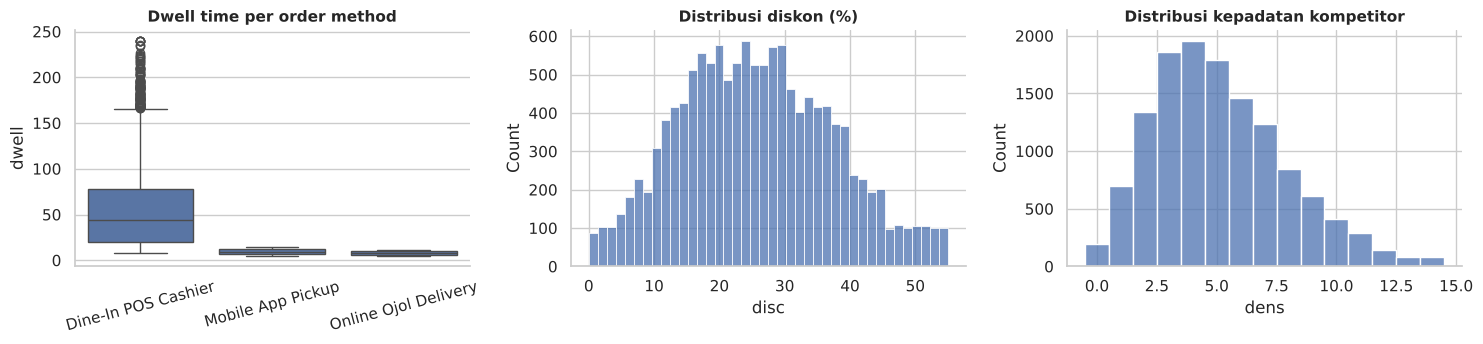

,kandidat,n,bukti,klasifikasi
0,Dwell > 60 mnt,983,Hanya Dine-In; non-dine-in selalu 5-14 mnt,"(2)/(4) Ekstrem valid secara bisnis, tetapi pola bimodal bersih = indikasi a..."
1,Revenue tertinggi (> P99),130,Bukan error: = harga x cups (identitas),(3) Sinyal bisnis (merek/format volume tinggi); diperiksa di Bag. 11
2,Diskon >= 50%,381,Maks 55%,(3) Sinyal bisnis: promo agresif; diuji di Bag. 07
3,Kepadatan kompetitor >= 10,1003,Maks 14,(2) Ekstrem valid; hanya di lokasi padat
4,price_comp > 1.2,468,Harga premium vs referensi,(2)/(3) Valid: merek premium (Fore)
5,dens = 0,195,Pembagian nol pada rev/dens bila rumus naif,(2) Valid; rumus sumber memakai dens+1


In [5]:
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
out = pd.DataFrame({'n_outlier_IQR': {c: iqr_out(d[c]) for c in ['dens','base_price','disc','cups','rating','dwell','net_price','rev','price_comp','dwell_spend','canni','sens','margin']}})
out['%'] = out.n_outlier_IQR / len(d) * 100
display(out)

print('Dwell time per metode pesan (inti temuan outlier):')
display(d.groupby('order').dwell.describe().round(1))
dw_hi = d[d.dwell > 60]
print(f'Dwell > 60 mnt: {len(dw_hi)} baris ({len(dw_hi)/len(d):.1%}); 100% Dine-In = {(dw_hi.order=="Dine-In POS Cashier").all()}; max = {d.dwell.max()} mnt (4 jam)')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.boxplot(data=d, x='order', y='dwell', ax=ax[0]); ax[0].set_title('Dwell time per order method'); ax[0].tick_params(axis='x', rotation=15); ax[0].set_xlabel('')
sns.histplot(d.disc, bins=40, ax=ax[1]); ax[1].set_title('Distribusi diskon (%)')
sns.histplot(d.dens, bins=15, discrete=True, ax=ax[2]); ax[2].set_title('Distribusi kepadatan kompetitor')
plt.tight_layout(); plt.show()

otab = pd.DataFrame([
 ('Dwell > 60 mnt', len(dw_hi), 'Hanya Dine-In; non-dine-in selalu 5-14 mnt', '(2)/(4) Ekstrem valid secara bisnis, tetapi pola bimodal bersih = indikasi artefak generasi data. Tidak dibuang; dwell hanya dianalisis dalam konteks Dine-In.'),
 ('Revenue tertinggi (> P99)', int((d.rev > d.rev.quantile(.99)).sum()), 'Bukan error: = harga x cups (identitas)', '(3) Sinyal bisnis (merek/format volume tinggi); diperiksa di Bag. 11'),
 ('Diskon >= 50%', int((d.disc >= 50).sum()), 'Maks 55%', '(3) Sinyal bisnis: promo agresif; diuji di Bag. 07'),
 ('Kepadatan kompetitor >= 10', int((d.dens >= 10).sum()), 'Maks 14', '(2) Ekstrem valid; hanya di lokasi padat'),
 ('price_comp > 1.2', int((d.price_comp > 1.2).sum()), 'Harga premium vs referensi', '(2)/(3) Valid: merek premium (Fore) '),
 ('dens = 0', int((d.dens == 0).sum()), 'Pembagian nol pada rev/dens bila rumus naif', '(2) Valid; rumus sumber memakai dens+1'),
], columns=['kandidat','n','bukti','klasifikasi'])
display(otab)

### 3.6 Confidence score audit
`confidence_score` **tidak diasumsikan** sebagai akurasi model. Kita periksa distribusinya dan hubungannya dengan variabel lain.

count   13,000.00
mean         0.97
std          0.02
min          0.90
25%          0.97
50%          0.98
75%          0.99
max          0.99
Nilai = 0.990 (batas atas): 27.0% baris -> distribusi tertumpuk/di-cap pada 0.99


,disc,price_comp,net_price,sens,margin,canni,dens,rating,cups,rev
Spearman dgn conf,0.63,-0.42,-0.42,0.45,-0.47,0.13,-0.16,0.18,0.23,-0.25


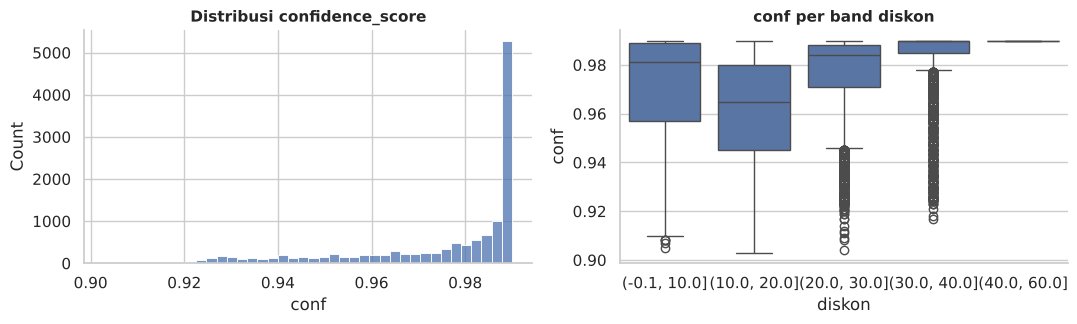

KESIMPULAN: skor ini berasosiasi kuat dengan diskon/sensitivitas harga (bukan dengan rating atau kualitas data). Ia tampak sebagai skor yang dihasilkan dari fitur lain,
bukan ukuran akurasi. Definisi tidak tersedia -> tidak dipakai untuk keputusan dan dikeluarkan dari model (risiko leakage/artefak).


In [6]:
print(d.conf.describe().round(4).to_string())
print(f'Nilai = 0.990 (batas atas): {(d.conf==0.99).mean():.1%} baris -> distribusi tertumpuk/di-cap pada 0.99')
cc = d[['conf','disc','price_comp','net_price','sens','margin','canni','dens','rating','cups','rev']].corr(method='spearman')['conf'].drop('conf').round(2)
display(cc.to_frame('Spearman dgn conf').T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(d.conf, bins=40, ax=ax[0]); ax[0].set_title('Distribusi confidence_score')
sns.boxplot(x=pd.cut(d.disc,[-.1,10,20,30,40,60]), y=d.conf, ax=ax[1]); ax[1].set_title('conf per band diskon'); ax[1].set_xlabel('diskon')
plt.tight_layout(); plt.show()
print('KESIMPULAN: skor ini berasosiasi kuat dengan diskon/sensitivitas harga (bukan dengan rating atau kualitas data). Ia tampak sebagai skor yang dihasilkan dari fitur lain,')
print('bukan ukuran akurasi. Definisi tidak tersedia -> tidak dipakai untuk keputusan dan dikeluarkan dari model (risiko leakage/artefak).')

### 3.7 Narrative field audit (`cot_retail_dynamics_rationale`)
Kolom narasi diuji sebagai **dokumen turunan**: apakah ia hanya menyusun ulang kolom lain (templat), dan apakah konsisten?

In [7]:
pat = {'base_price': (r"harga dasar Rp([\d,]+)", lambda x: float(x.replace(',', ''))),
       'disc': (r"diskon ([\d.]+)%", float), 'cups': (r"([\d,]+) cup/hari", lambda x: float(x.replace(',', ''))),
       'margin': (r"margin laba operasional ([\d.]+)%", float), 'canni': (r"kanibalisasi ([\d.]+)/10", float),
       'dens': (r"radius (\d+) gerai", float)}
res = {}
for k, (rx, fn) in pat.items():
    v = d.rationale.str.extract(rx)[0]
    parsed = v.dropna().map(fn).reindex(d.index)
    res[k] = {'parsed_%': parsed.notna().mean()*100, 'match_%': (np.abs(parsed - d[k]) < 0.051).mean()*100}
display(pd.DataFrame(res).T.round(2))
print(f'Panjang narasi: mean {d.rationale.str.len().mean():.0f}, std {d.rationale.str.len().std():.0f} karakter (nyaris seragam => templat)')
print('KESIMPULAN: narasi menyalin nilai kolom lain (match ~100%). Ia BUKAN sumber informasi independen. Digunakan hanya untuk validasi konsistensi; tidak masuk model.')

,parsed_%,match_%
base_price,100.00,100.00
disc,100.00,100.00
cups,100.00,100.00
margin,100.00,100.00
canni,100.00,100.00
dens,100.00,100.00


Panjang narasi: mean 967, std 20 karakter (nyaris seragam => templat)
KESIMPULAN: narasi menyalin nilai kolom lain (match ~100%). Ia BUKAN sumber informasi independen. Digunakan hanya untuk validasi konsistensi; tidak masuk model.


### 3.8 Data-quality summary & leakage ledger

In [8]:
summary = pd.DataFrame([
 ('Kelengkapan', 'Lulus', 'Tidak ada missing value'),
 ('Duplikasi', 'Lulus', 'ID unik; tidak ada baris duplikat'),
 ('Validitas rentang', 'Lulus', 'Tidak ada nilai mustahil (harga, diskon, rating, margin, indeks)'),
 ('Konsistensi label', 'Lulus', 'Tidak ada variasi penulisan/spasi pada kategori'),
 ('Variabel turunan', 'Perhatian', 'net_price, rev, rev_per_comp, dwell_spend, price_comp = turunan -> bukan informasi independen'),
 ('Outlier', 'Perhatian', 'Dwell Dine-In (hingga 240 mnt) = bimodal; tidak dibuang, dianalisis kondisional'),
 ('Confidence score', 'Perhatian', 'Berasosiasi dgn diskon; definisi tidak tersedia -> tidak dipakai'),
 ('Narasi', 'Perhatian', 'Templat yang menyalin kolom lain -> tidak dipakai sbg fitur'),
 ('Sifat data', 'Peringatan', 'Pola sangat bersih/deterministik (cap conf 0.99, kategori seimbang-rapi) -> kemungkinan SINTETIS; tidak ada dimensi waktu'),
], columns=['dimensi','status','temuan'])
display(summary)

leak = pd.DataFrame([
 ('daily_revenue_estimate_idr', 'Target Model 1', 'Derived = net_price x cups', 'Target (bukan prediktor)'),
 ('net_discounted_price_idr', 'Turunan base_price & disc', 'Derived', 'Dikeluarkan dari Model 1 & 2; diganti base_price + disc'),
 ('daily_cups_sold', 'Komponen identitas revenue', 'Raw outcome', 'Dikeluarkan dari Model 1 (mekanis); dianalisis sbg outcome sendiri'),
 ('revenue_per_competitor_density', 'rev/(dens+1)', 'Derived dari target', 'DIKELUARKAN (leakage langsung)'),
 ('dwell_time_to_spend_ratio', 'dwell/(net_price/1000)', 'Derived', 'DIKELUARKAN (duplikasi dwell & harga)'),
 ('price_competitiveness_ratio', '~ net_price / konstanta', 'Derived', 'DIKELUARKAN dari model; dipakai deskriptif'),
 ('cot_retail_dynamics_rationale', 'Salinan kolom lain', 'Narrative', 'DIKELUARKAN'),
 ('confidence_score', 'Tidak terdefinisi; terkait diskon', 'Meta', 'DIKELUARKAN; hanya diaudit'),
 ('cannibalization_risk_index', 'Komposit; bisa pasca-hasil', 'Composite', 'Dianalisis sbg outcome risiko; bukan prediktor margin'),
], columns=['variabel','lineage','kelas','keputusan modeling'])
display(leak)

,dimensi,status,temuan
0,Kelengkapan,Lulus,Tidak ada missing value
1,Duplikasi,Lulus,ID unik; tidak ada baris duplikat
2,Validitas rentang,Lulus,"Tidak ada nilai mustahil (harga, diskon, rating, margin, indeks)"
3,Konsistensi label,Lulus,Tidak ada variasi penulisan/spasi pada kategori
4,Variabel turunan,Perhatian,"net_price, rev, rev_per_comp, dwell_spend, price_comp = turunan -> bukan inf..."
5,Outlier,Perhatian,"Dwell Dine-In (hingga 240 mnt) = bimodal; tidak dibuang, dianalisis kondisional"
6,Confidence score,Perhatian,Berasosiasi dgn diskon; definisi tidak tersedia -> tidak dipakai
7,Narasi,Perhatian,Templat yang menyalin kolom lain -> tidak dipakai sbg fitur
8,Sifat data,Peringatan,"Pola sangat bersih/deterministik (cap conf 0.99, kategori seimbang-rapi) -> ..."


,variabel,lineage,kelas,keputusan modeling
0,daily_revenue_estimate_idr,Target Model 1,Derived = net_price x cups,Target (bukan prediktor)
1,net_discounted_price_idr,Turunan base_price & disc,Derived,Dikeluarkan dari Model 1 & 2; diganti base_price + disc
2,daily_cups_sold,Komponen identitas revenue,Raw outcome,Dikeluarkan dari Model 1 (mekanis); dianalisis sbg outcome sendiri
3,revenue_per_competitor_density,rev/(dens+1),Derived dari target,DIKELUARKAN (leakage langsung)
4,dwell_time_to_spend_ratio,dwell/(net_price/1000),Derived,DIKELUARKAN (duplikasi dwell & harga)
5,price_competitiveness_ratio,~ net_price / konstanta,Derived,DIKELUARKAN dari model; dipakai deskriptif
6,cot_retail_dynamics_rationale,Salinan kolom lain,Narrative,DIKELUARKAN
7,confidence_score,Tidak terdefinisi; terkait diskon,Meta,DIKELUARKAN; hanya diaudit
8,cannibalization_risk_index,Komposit; bisa pasca-hasil,Composite,Dianalisis sbg outcome risiko; bukan prediktor margin


# 04. Data Preparation & Feature Validation
Fitur rekayasa (semua transparan dan dapat diaudit):
- **Band diskon** (0-10 / 10-20 / 20-30 / 30-40 / 40+) + versi kuintil sebagai uji sensitivitas.
- **Band kepadatan kompetitor**, **kuartil price competitiveness**.
- **Profit proxy** = revenue x margin/100; **gross revenue** = base_price x cups; **discount cost** = gross - revenue.
- **Switch type**: pemetaan 5 pemicu ke 4 kelompok yang diminta brief.
- **Loyalty score** ordinal (Die-Hard=3, Value-Conscious=2, Promo-Chaser=1, At-Risk=0).

In [9]:
LOY = ['Die-Hard-Loyalist','Value-Conscious-Regular','Promo-Chaser-Opportunist','At-Risk-Churn-Switcher']
d['loyalty'] = pd.Categorical(d.loyalty, LOY, ordered=True)
d['loy_score'] = d.loyalty.map({LOY[0]:3, LOY[1]:2, LOY[2]:1, LOY[3]:0}).astype(int)
d['disc_band'] = pd.cut(d.disc, [-0.01,10,20,30,40,60], labels=['0-10','10-20','20-30','30-40','40+'])
d['disc_band_q'] = pd.qcut(d.disc, 5, duplicates='drop')
d['dens_band'] = pd.cut(d.dens, [-1,2,5,8,20], labels=['0-2 (jarang)','3-5','6-8','9+ (padat)'])
d['pc_band'] = pd.qcut(d.price_comp, 4, labels=['Q1 termurah','Q2','Q3','Q4 termahal'])
d['rev_m'] = d.rev/1e6
d['gross_rev'] = d.base_price*d.cups
d['disc_cost_m'] = (d.gross_rev - d.rev)/1e6
d['profit'] = d.rev*d.margin/100
d['profit_m'] = d.profit/1e6
d['profit_per_cup'] = d.net_price*d.margin/100
d['is_dinein'] = (d.order == 'Dine-In POS Cashier')
d['dwell_dinein'] = d.dwell.where(d.is_dinein)
SW = {'Cheaper-Competitor-Opening':'Price-driven','Voucher-Exhaustion-Price-Hike':'Promotion-driven','Taste-Inconsistency-Drop':'Experience-driven',
      'Lack-Of-Seating-WiFi':'Experience-driven','Long-Queue-Pickup-Delay':'Availability/Convenience-driven'}
d['switch_type'] = d.switch.map(SW)

# Validasi fitur
assert d.switch_type.notna().all()
print('Gross revenue vs revenue: diskon menghapus', f'{1-d.rev.sum()/d.gross_rev.sum():.1%}', 'dari revenue kotor (potensial) pada level agregat')
print('Margin ~ margin atas revenue; profit proxy total =', fidr(d.profit.sum()), '(per hari, jumlah seluruh observasi)')

AGG = dict(n=('cups','size'), cups=('cups','mean'), net_price=('net_price','mean'), disc=('disc','mean'), rev_m=('rev_m','mean'),
           margin=('margin','mean'), profit_m=('profit_m','mean'), sens=('sens','mean'), canni=('canni','mean'), dens=('dens','mean'))
def prof(by, data=None, extra=None):
    data = d if data is None else data
    a = dict(AGG); a.update(extra or {})
    return data.groupby(by, observed=True).agg(**a).round(2)

DIMS = {'Brand':'brand','City':'city','Store format':'fmt','Customer segment':'seg','Loyalty tier':'loyalty','Order method':'order',
        'Competitor density':'dens_band','Price competitiveness':'pc_band','Discount band':'disc_band'}
def sp(a, b, data=None):
    data = d if data is None else data
    r, p = stats.spearmanr(data[a], data[b]); return r, p
def binned(x, y, bins=20, ax=None, color=None, label=None, data=None):
    data = d if data is None else data
    g = data.groupby(pd.qcut(data[x], bins, duplicates='drop'), observed=True).agg(xm=(x,'mean'), ym=(y,'mean'), se=(y,'sem'))
    ax.errorbar(g.xm, g.ym, yerr=1.96*g.se, fmt='o-', ms=4, lw=1.2, capsize=2, color=color, label=label)
    return g
d.head(2)[['brand','disc','disc_band','dens_band','pc_band','profit_m','switch_type']]

Gross revenue vs revenue: diskon menghapus 26.2% dari revenue kotor (potensial) pada level agregat
Margin ~ margin atas revenue; profit proxy total = Rp30,850.69 jt (per hari, jumlah seluruh observasi)


,brand,disc,disc_band,dens_band,pc_band,profit_m,switch_type
0,Fore Coffee,31.00,30-40,0-2 (jarang),Q4 termahal,2.22,Price-driven
1,Fore Coffee,22.10,20-30,0-2 (jarang),Q4 termahal,4.28,Experience-driven


# 05. Exploratory Data Analysis
**Pertanyaan:** seperti apa profil KPI pasar dan dimensi mana yang membedakan kinerja? Tabel ringkas di bawah menjadi *peta* untuk bagian berikutnya.

,mean,median,std,p10,p90
Cups/hari,575.98,550.00,216.87,315.00,881.00
Net price (Rp),"15,170.14","15,400.00","4,993.15","8,174.70","21,482.10"
Revenue/hari (Rp jt),8.07,7.87,2.70,4.77,11.69
Margin (%),29.51,29.50,6.58,20.80,38.30
Diskon (%),25.69,25.10,11.77,10.80,41.50
Sensitivitas harga,5.51,5.47,1.69,3.28,7.69
Kompetitor 500m,5.13,5.00,2.78,2.00,9.00
Cannibalization idx,4.69,4.63,1.19,3.20,6.28
Rating,4.52,4.50,0.42,4.00,5.00
Profit proxy (Rp jt),2.37,2.27,0.95,1.23,3.66


Loyalitas: Die-Hard 13.7% | Value 44.8% | Promo-Chaser 34.9% | At-Risk 6.6%


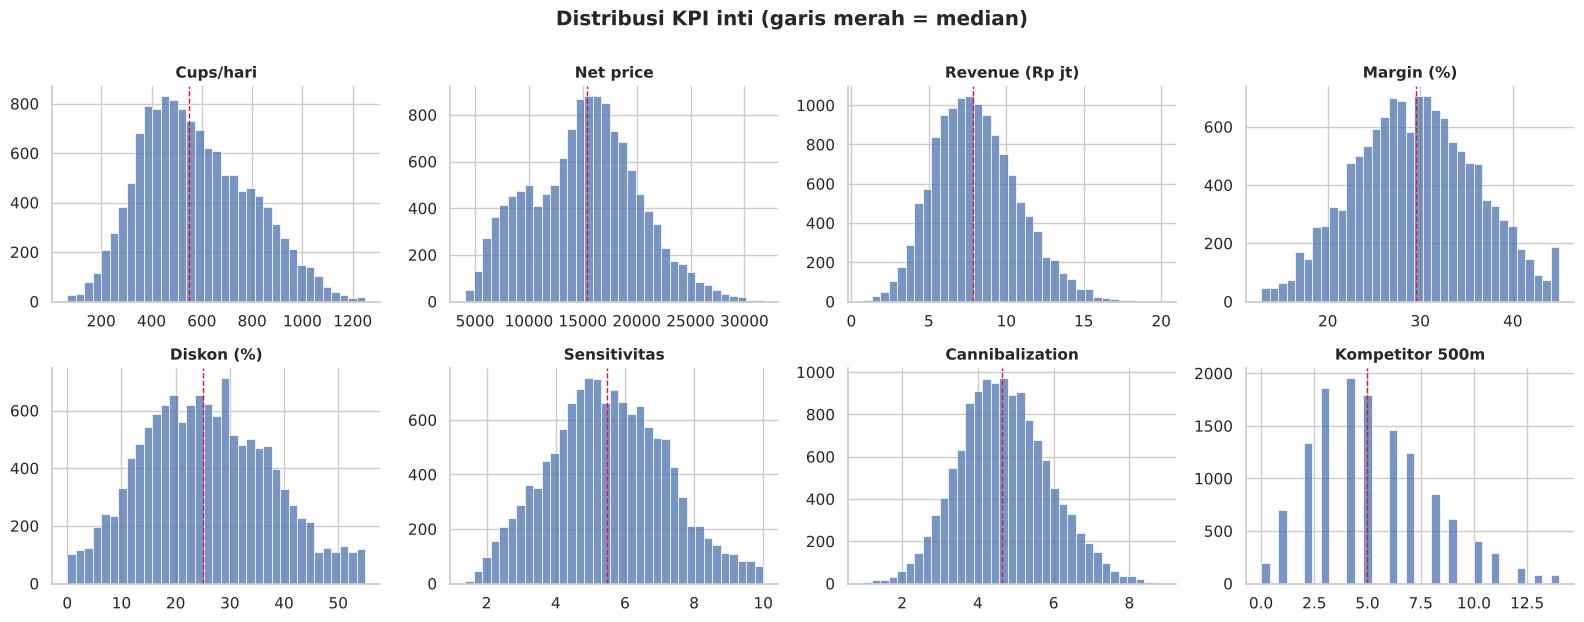

In [10]:
kpis = {'cups':'Cups/hari','net_price':'Net price (Rp)','rev_m':'Revenue/hari (Rp jt)','margin':'Margin (%)','disc':'Diskon (%)','sens':'Sensitivitas harga',
        'dens':'Kompetitor 500m','canni':'Cannibalization idx','rating':'Rating','profit_m':'Profit proxy (Rp jt)'}
kp = d[list(kpis)].agg(['mean','median','std', lambda s: s.quantile(.1), lambda s: s.quantile(.9)]).T
kp.columns = ['mean','median','std','p10','p90']; kp.index = kpis.values()
display(kp)
print(f'Loyalitas: Die-Hard {np.mean(d.loyalty==LOY[0]):.1%} | Value {np.mean(d.loyalty==LOY[1]):.1%} | Promo-Chaser {np.mean(d.loyalty==LOY[2]):.1%} | At-Risk {np.mean(d.loyalty==LOY[3]):.1%}')

fig, ax = plt.subplots(2, 4, figsize=(16, 6.2))
for a, (c, t) in zip(ax.flat, [('cups','Cups/hari'),('net_price','Net price'),('rev_m','Revenue (Rp jt)'),('margin','Margin (%)'),('disc','Diskon (%)'),('sens','Sensitivitas'),('canni','Cannibalization'),('dens','Kompetitor 500m')]):
    sns.histplot(d[c], bins=35, ax=a, color='#4C72B0'); a.axvline(d[c].median(), color='crimson', ls='--', lw=1); a.set_title(t); a.set_xlabel(''); a.set_ylabel('')
plt.suptitle('Distribusi KPI inti (garis merah = median)', y=1.0, fontweight='bold'); plt.tight_layout(); plt.show()

In [11]:
for title, col in DIMS.items():
    md_(f'**{title}**')
    display(prof(col).sort_values('profit_m', ascending=False) if col in ('brand','city','fmt','seg') else prof(col))

**Brand**

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
brand,,,,,,,,,,
Kopi Kenangan,3510,582.97,"16,997.04",23.04,9.85,30.77,3.03,5.04,4.59,5.20
Point Coffee,1709,439.42,"16,103.06",16.19,7.04,36.07,2.53,4.78,4.30,5.18
Fore Coffee,2420,409.08,"20,841.43",26.54,8.47,26.83,2.27,4.63,4.72,5.12
Kopi Janji Jiwa,1350,369.68,"16,048.04",18.77,5.90,35.87,2.11,4.98,4.39,5.07
Tomoro Coffee,4011,798.17,"9,456.74",33.88,7.44,25.09,1.89,6.96,5.02,5.07


**City**

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
city,,,,,,,,,,
Makassar,67,618.45,"16,705.73",25.14,9.85,29.17,2.86,5.27,4.33,3.87
Batam,32,622.50,"15,761.25",24.03,9.50,30.02,2.82,5.52,4.00,3.00
Malang,90,602.10,"15,676.57",26.12,8.86,28.79,2.51,5.46,4.06,3.24
Palembang,63,546.03,"15,934.19",25.82,8.46,29.53,2.47,5.62,4.10,3.30
Depok,564,574.68,"15,254.54",24.93,8.18,29.91,2.44,5.42,4.12,3.51
Semarang,535,586.81,"15,147.41",25.24,8.24,29.65,2.43,5.53,4.28,3.99
Bekasi,903,580.71,"15,187.85",25.93,8.20,29.47,2.41,5.50,4.18,3.61
Yogyakarta,391,581.32,"15,156.54",25.93,8.13,29.44,2.40,5.58,4.15,3.58
Jakarta Pusat,1724,580.15,"15,175.59",25.52,8.14,29.46,2.39,5.47,5.13,6.43


**Store format**

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
fmt,,,,,,,,,,
Office Tower Lobby,2553,687.70,"15,232.93",25.80,9.69,27.47,2.69,4.91,4.91,5.83
Standalone Shophouse / Ruko,4501,565.38,"15,125.40",25.74,7.89,31.47,2.51,5.76,4.87,4.56
Mall Kiosk,3613,618.50,"15,161.52",25.59,8.65,25.43,2.23,5.56,5.06,5.71
Drive-Thru Highway,832,447.67,"15,098.16",25.50,6.30,32.46,2.06,5.50,3.29,4.64
Cloud Kitchen / Delivery Only,1501,386.48,"15,258.15",25.74,5.43,35.31,1.94,5.68,3.65,4.49


... (8 outputs left out)

**Price competitiveness**

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
pc_band,,,,,,,,,,
Q1 termurah,3252,808.22,"8,618.13",36.69,6.89,24.16,1.67,7.26,5.14,5.03
Q2,3253,564.05,"13,744.36",26.46,7.69,30.28,2.27,5.77,4.74,5.19
Q3,3253,482.80,"16,869.66",21.91,8.15,32.00,2.56,5.02,4.53,5.17
Q4 termahal,3242,448.48,"21,467.69",17.70,9.56,31.61,3.00,4.00,4.35,5.12


**Discount band**

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
disc_band,,,,,,,,,,
0-10,1101,470.54,"18,975.87",5.94,8.94,38.57,3.38,3.71,3.82,5.07
10-20,3404,522.31,"18,088.97",15.49,9.05,33.56,2.97,4.45,4.27,5.18
20-30,3983,558.74,"15,426.45",25.15,8.14,29.86,2.37,5.43,4.67,5.15
30-40,2967,612.07,"13,374.09",34.84,7.62,25.69,1.92,6.34,5.08,5.12
40+,1545,744.47,"8,815.59",46.11,5.99,20.57,1.22,7.76,5.54,5.00


**Membaca peta EDA.** Perhatikan bahwa dimensi yang menaikkan *cups* (diskon tinggi, harga rendah) sering justru menurunkan *margin*. Revenue, volume, dan margin tidak bergerak searah, sehingga peringkat berdasarkan revenue saja menyesatkan. Bagian 06-12 menguji hal ini secara sistematis.

# 06. Brand Performance Analysis
**Pertanyaan:** merek mana yang punya ekonomi komersial unggul, dan apa pembedanya (volume, harga, diskon, loyalitas, eksposur kompetitor)? Peringkat **tidak** berdasar revenue saja.

,n,cups,net_price,base_price,disc,rev_m,margin,profit_m,profit_per_cup,rating,sens,dens,canni,diehard_pct,atrisk_promo_pct,price_switch_pct,rev_rank,margin_rank,profit_rank
brand,,,,,,,,,,,,,,,,,,,
Kopi Kenangan,3510,582.97,"16,997.04","22,101.42",23.04,9.85,30.77,3.03,"5,296.87",4.47,5.04,5.20,4.59,18.12,36.44,29.77,1,3,1
Point Coffee,1709,439.42,"16,103.06","19,232.88",16.19,7.04,36.07,2.53,"5,851.04",4.42,4.78,5.18,4.30,29.55,11.47,17.96,4,1,2
Fore Coffee,2420,409.08,"20,841.43","28,365.70",26.54,8.47,26.83,2.27,"5,686.91",4.62,4.63,5.12,4.72,12.31,42.89,64.26,2,4,3
Kopi Janji Jiwa,1350,369.68,"16,048.04","19,774.07",18.77,5.90,35.87,2.11,"5,805.67",4.42,4.98,5.07,4.39,24.96,24.89,18.81,5,2,4
Tomoro Coffee,4011,798.17,"9,456.74","14,247.82",33.88,7.44,25.09,1.89,"2,441.47",4.57,6.96,5.07,5.02,0.10,63.43,19.95,3,5,5


,margin_premium_vs_diskon (pp),disc,margin
brand,,,
Fore Coffee,-2.31,26.54,26.83
Kopi Janji Jiwa,3.39,18.77,35.87
Kopi Kenangan,0.12,23.04,30.77
Point Coffee,2.49,16.19,36.07
Tomoro Coffee,-0.91,33.88,25.09


Margin turun ~0.428 pp untuk setiap +1 pp diskon (OLS sederhana). Residual>0 = margin lebih baik dari yang diprediksi diskon.


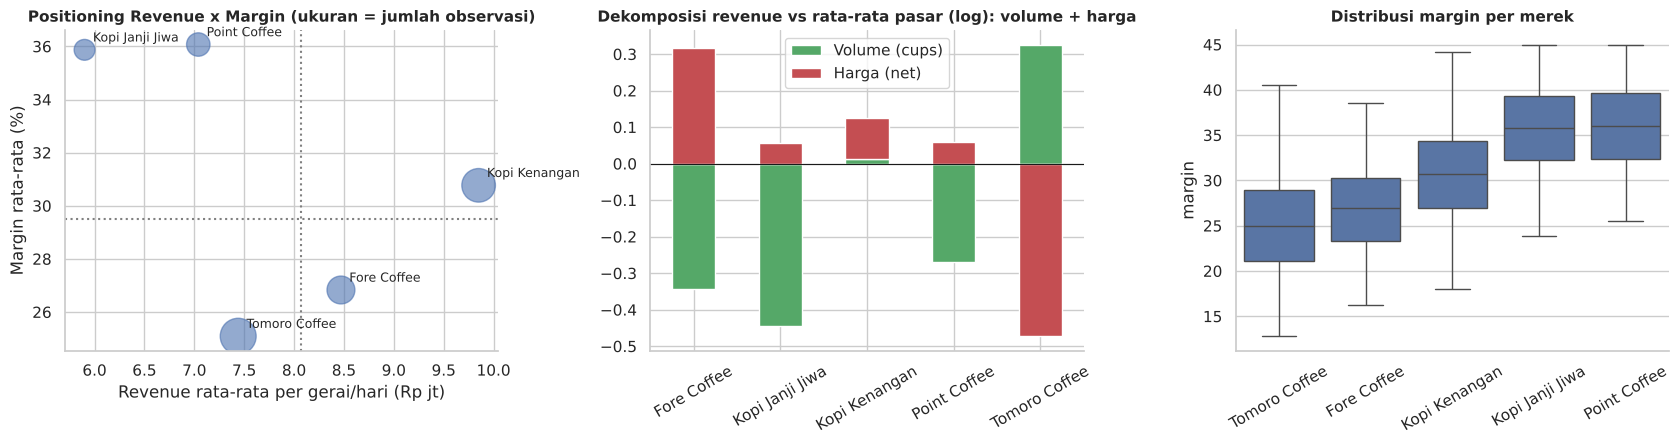

**Komposisi format per merek (% baris)** - menguji apakah perbedaan merek tercampur efek format

fmt,Cloud Kitchen / Delivery Only,Drive-Thru Highway,Mall Kiosk,Office Tower Lobby,Standalone Shophouse / Ruko
brand,,,,,
Fore Coffee,12.30,6.00,27.60,19.40,34.70
Kopi Janji Jiwa,10.10,5.90,28.10,20.20,35.60
Kopi Kenangan,12.10,6.20,28.10,20.60,33.00
Point Coffee,11.10,6.90,25.90,19.70,36.30
Tomoro Coffee,11.30,6.70,28.30,18.70,35.00


**Pemicu switching per merek (% baris)**

switch,Cheaper-Competitor-Opening,Lack-Of-Seating-WiFi,Long-Queue-Pickup-Delay,Taste-Inconsistency-Drop,Voucher-Exhaustion-Price-Hike
brand,,,,,
Fore Coffee,64.30,5.10,1.50,17.90,11.30
Kopi Janji Jiwa,18.80,37.30,0.00,32.10,11.80
Kopi Kenangan,29.80,15.30,15.70,29.30,10.00
Point Coffee,18.00,34.80,0.60,34.00,12.60
Tomoro Coffee,19.90,5.80,53.90,20.40,0.00


In [12]:
loyal_share = lambda t: (lambda s: (s.isin(t)).mean()*100)
bt = d.groupby('brand').agg(n=('cups','size'), cups=('cups','mean'), net_price=('net_price','mean'), base_price=('base_price','mean'), disc=('disc','mean'),
    rev_m=('rev_m','mean'), margin=('margin','mean'), profit_m=('profit_m','mean'), profit_per_cup=('profit_per_cup','mean'), rating=('rating','mean'), sens=('sens','mean'),
    dens=('dens','mean'), canni=('canni','mean'),
    diehard_pct=('loyalty', lambda s: (s==LOY[0]).mean()*100), atrisk_promo_pct=('loyalty', lambda s: s.isin(LOY[2:]).mean()*100),
    price_switch_pct=('switch_type', lambda s: (s=='Price-driven').mean()*100)).round(2)
bt['rev_rank'] = bt.rev_m.rank(ascending=False).astype(int); bt['margin_rank'] = bt.margin.rank(ascending=False).astype(int); bt['profit_rank'] = bt.profit_m.rank(ascending=False).astype(int)
display(bt.sort_values('profit_m', ascending=False))

# Margin brand di luar efek diskon (apakah merek berbeda karena diskon saja?)
m0 = smf.ols('margin ~ disc', d).fit(); d['margin_resid_disc'] = m0.resid
adj = d.groupby('brand').margin_resid_disc.mean().round(2).rename('margin_premium_vs_diskon (pp)')
display(adj.to_frame().join(bt[['disc','margin']]))
print(f'Margin turun ~{-m0.params["disc"]:.3f} pp untuk setiap +1 pp diskon (OLS sederhana). Residual>0 = margin lebih baik dari yang diprediksi diskon.')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
a = ax[0]; a.scatter(bt.rev_m, bt.margin, s=bt.n/6, alpha=.6)
for b, r in bt.iterrows(): a.annotate(b, (r.rev_m, r.margin), xytext=(6, 6), textcoords='offset points', fontsize=9)
a.axvline(d.rev_m.mean(), ls=':', c='grey'); a.axhline(d.margin.mean(), ls=':', c='grey')
a.set_xlabel('Revenue rata-rata per gerai/hari (Rp jt)'); a.set_ylabel('Margin rata-rata (%)'); a.set_title('Positioning Revenue x Margin (ukuran = jumlah observasi)')
idx = pd.DataFrame({'Volume (cups)': np.log(bt.cups/d.cups.mean()), 'Harga (net)': np.log(bt.net_price/d.net_price.mean())})
idx.plot(kind='bar', stacked=True, ax=ax[1], color=['#55A868','#C44E52']); ax[1].axhline(0, c='k', lw=.8)
ax[1].set_title('Dekomposisi revenue vs rata-rata pasar (log): volume + harga'); ax[1].tick_params(axis='x', rotation=30); ax[1].set_xlabel('')
sns.boxplot(data=d, x='brand', y='margin', order=bt.sort_values('margin').index, ax=ax[2]); ax[2].tick_params(axis='x', rotation=30); ax[2].set_title('Distribusi margin per merek'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

# Konfonding komposisi: apakah merek berbeda karena format/kota?
md_('**Komposisi format per merek (% baris)** - menguji apakah perbedaan merek tercampur efek format')
display((pd.crosstab(d.brand, d.fmt, normalize='index')*100).round(1))
md_('**Pemicu switching per merek (% baris)**')
display((pd.crosstab(d.brand, d.switch, normalize='index')*100).round(1))

**Interpretasi.** Dekomposisi memisahkan merek yang menang di *volume* (cups) dari yang menang di *harga*. Merek volume tinggi dengan harga rendah dan diskon dalam mencatat margin yang lebih rendah; merek dengan diskon rendah cenderung punya margin lebih tinggi meski volumenya kecil. Kolom *margin_premium_vs_diskon* memberi tahu apakah keunggulan margin merek hanya berasal dari diskon yang lebih kecil atau ada efek merek tersendiri.

# 07. Pricing & Promotion Economics
**Hipotesis H1:** *Apakah kenaikan diskon menghasilkan volume tambahan yang cukup untuk mengompensasi hilangnya unit economics?*

Rantai analisis: **Diskon -> Net price -> Volume -> Revenue -> Margin -> Profit proxy.** Semua temuan adalah *asosiasi*.

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens,gross_m,disc_cost_m,profit_per_cup,d_cups_%,d_rev_%,d_margin_pp,d_profit_%
disc_band,,,,,,,,,,,,,,,,,
0-10,1101,470.54,"18,975.87",5.94,8.94,38.57,3.38,3.71,3.82,5.07,9.53,0.59,"7,300.92",0.00,0.00,0.00,0.00
10-20,3404,522.31,"18,088.97",15.49,9.05,33.56,2.97,4.45,4.27,5.18,10.71,1.66,"6,050.54",11.00,1.23,-5.01,-12.13
20-30,3983,558.74,"15,426.45",25.15,8.14,29.86,2.37,5.43,4.67,5.15,10.87,2.74,"4,599.15",18.74,-8.95,-8.71,-29.88
30-40,2967,612.07,"13,374.09",34.84,7.62,25.69,1.92,6.34,5.08,5.12,11.70,4.08,"3,437.83",30.08,-14.77,-12.88,-43.20
40+,1545,744.47,"8,815.59",46.11,5.99,20.57,1.22,7.76,5.54,5.00,11.09,5.10,"1,832.58",58.22,-33.00,-18.00,-63.91


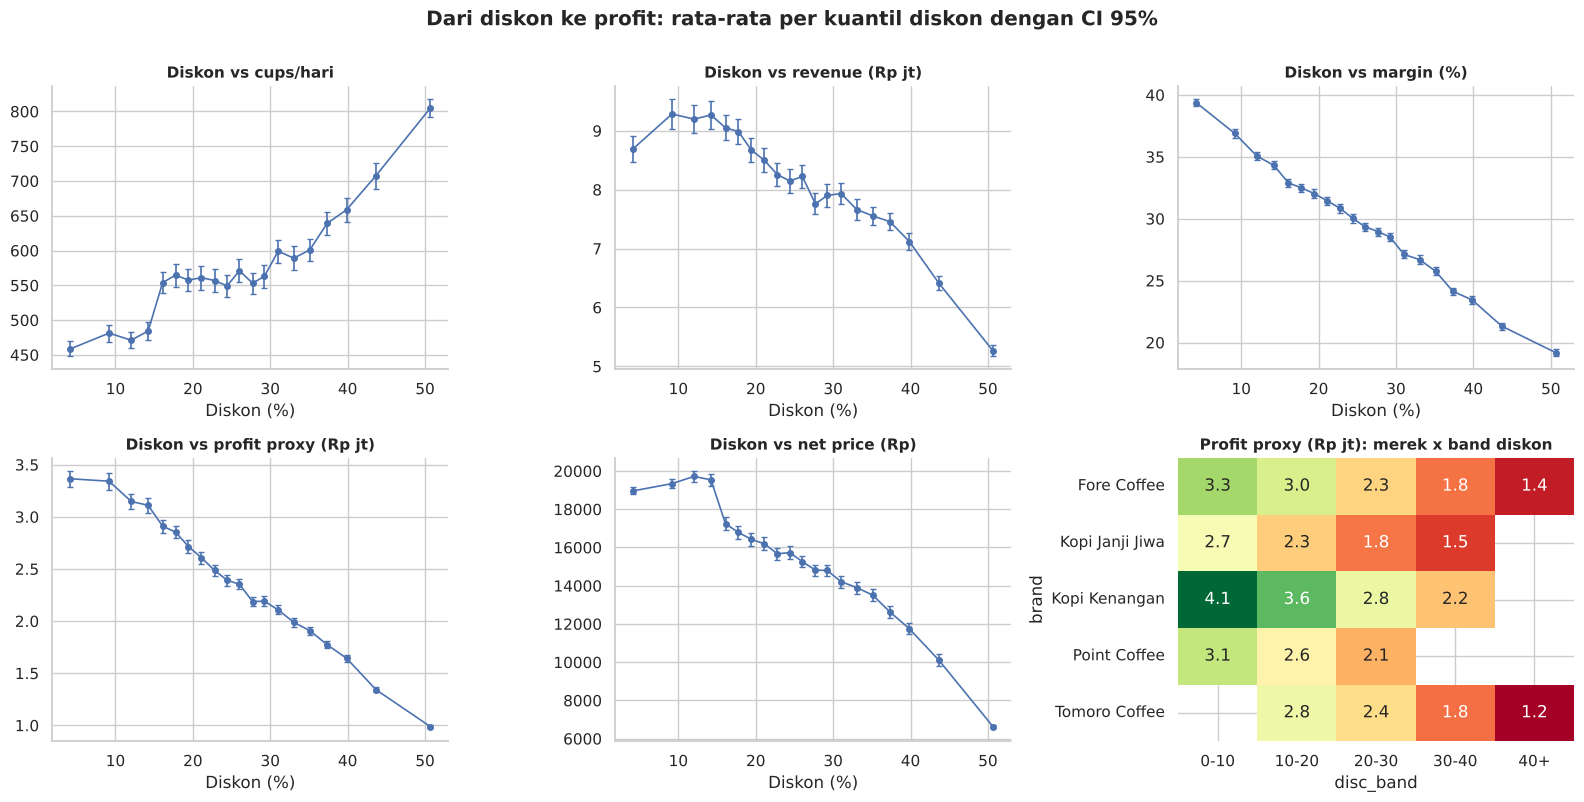

,Spearman vs diskon,p
outcome,,
cups,0.32,0.00
rev,-0.32,0.00
margin,-0.75,0.00
profit,-0.68,0.00


In [13]:
bd = prof('disc_band', extra=dict(gross_m=('gross_rev', lambda s: s.mean()/1e6), disc_cost_m=('disc_cost_m','mean'), profit_per_cup=('profit_per_cup','mean')))
base = bd.iloc[0]
bd['d_cups_%'] = (bd.cups/base.cups-1)*100; bd['d_rev_%'] = (bd.rev_m/base.rev_m-1)*100; bd['d_margin_pp'] = bd.margin-base.margin; bd['d_profit_%'] = (bd.profit_m/base.profit_m-1)*100
display(bd)

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (y, t) in zip(ax.flat, [('cups','Diskon vs cups/hari'),('rev_m','Diskon vs revenue (Rp jt)'),('margin','Diskon vs margin (%)'),('profit_m','Diskon vs profit proxy (Rp jt)'),('net_price','Diskon vs net price (Rp)')]):
    binned('disc', y, 20, a); a.set_title(t); a.set_xlabel('Diskon (%)'); a.set_ylabel('')
sns.heatmap(d.pivot_table(index='brand', columns='disc_band', values='profit_m', aggfunc='mean', observed=True), annot=True, fmt='.1f', cmap='RdYlGn', ax=ax[1,2], cbar=False)
ax[1,2].set_title('Profit proxy (Rp jt): merek x band diskon')
plt.suptitle('Dari diskon ke profit: rata-rata per kuantil diskon dengan CI 95%', y=1.0, fontweight='bold'); plt.tight_layout(); plt.show()

rows = []
for y in ['cups','rev','margin','profit']:
    r, p = sp('disc', y); rows.append((y, r, p))
display(pd.DataFrame(rows, columns=['outcome','Spearman vs diskon','p']).set_index('outcome'))

In [14]:
# Paradoks komposisi (Simpson): apakah hubungan diskon-cups bertahan DI DALAM merek/kota/format?
ols_c = smf.ols('np.log(cups) ~ disc + C(brand) + C(city) + C(fmt) + C(order) + dens', d).fit(cov_type='HC3')
ols_c0 = smf.ols('np.log(cups) ~ disc', d).fit(cov_type='HC3')
ci = ols_c.conf_int().loc['disc']
print(f'log(cups) ~ diskon, tanpa kontrol : +1 pp diskon ~ {100*(np.exp(ols_c0.params["disc"])-1):+.2f}% cups')
print(f'log(cups) ~ diskon, kontrol merek/kota/format/order/dens: +1 pp diskon ~ {100*(np.exp(ols_c.params["disc"])-1):+.2f}% cups (CI95 {100*(np.exp(ci[0])-1):+.2f}% .. {100*(np.exp(ci[1])-1):+.2f}%)')
dc = d.groupby('brand').apply(lambda g: pd.Series({'slope_cups_per_pp': np.polyfit(g.disc, g.cups, 1)[0], 'slope_margin_per_pp': np.polyfit(g.disc, g.margin, 1)[0], 'slope_rev_m_per_pp': np.polyfit(g.disc, g.rev_m, 1)[0], 'slope_profit_m_per_pp': np.polyfit(g.disc, g.profit_m, 1)[0]}))
md_('**Efek diskon di dalam setiap merek (kemiringan OLS per +1 pp diskon)**'); display(dc.round(3))

# Elastisitas harga (asosiasi, log-log), harga dasar sbg kontrol tak bisa dipakai bersama net price -> pakai net price
e0 = smf.ols('np.log(cups) ~ np.log(net_price)', d).fit(cov_type='HC3')
e1 = smf.ols('np.log(cups) ~ np.log(net_price) + C(brand) + C(city) + C(fmt) + C(order)', d).fit(cov_type='HC3')
for nm, e in [('tanpa kontrol', e0), ('kontrol merek/kota/format/order', e1)]:
    c = e.conf_int().loc['np.log(net_price)']; print(f'Elastisitas asosiatif volume thd net price ({nm}): {e.params["np.log(net_price)"]:.2f} (CI95 {c[0]:.2f}..{c[1]:.2f})')
print('Catatan: ini BUKAN elastisitas kausal; harga/diskon tidak ditetapkan secara acak dan merek dengan harga rendah berbeda dalam banyak hal.')

log(cups) ~ diskon, tanpa kontrol : +1 pp diskon ~ +1.10% cups
log(cups) ~ diskon, kontrol merek/kota/format/order/dens: +1 pp diskon ~ +0.03% cups (CI95 -0.00% .. +0.07%)


**Efek diskon di dalam setiap merek (kemiringan OLS per +1 pp diskon)**

,slope_cups_per_pp,slope_margin_per_pp,slope_rev_m_per_pp,slope_profit_m_per_pp
brand,,,,
Fore Coffee,0.26,-0.35,-0.11,-0.06
Kopi Janji Jiwa,-0.27,-0.32,-0.07,-0.04
Kopi Kenangan,-0.10,-0.34,-0.12,-0.07
Point Coffee,0.43,-0.34,-0.07,-0.05
Tomoro Coffee,0.75,-0.35,-0.12,-0.06


Elastisitas asosiatif volume thd net price (tanpa kontrol): -0.65 (CI95 -0.66..-0.63)
Elastisitas asosiatif volume thd net price (kontrol merek/kota/format/order): -0.22 (CI95 -0.23..-0.20)
Catatan: ini BUKAN elastisitas kausal; harga/diskon tidak ditetapkan secara acak dan merek dengan harga rendah berbeda dalam banyak hal.


### 7.2 Price competitiveness
Rasio <1 = harga bersih lebih murah dari referensi pasar (~Rp20 rb). Apakah lebih murah = lebih banyak volume dan tetap sehat secara margin?

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
pc_band,,,,,,,,,,
Q1 termurah,3252,808.22,"8,618.13",36.69,6.89,24.16,1.67,7.26,5.14,5.03
Q2,3253,564.05,"13,744.36",26.46,7.69,30.28,2.27,5.77,4.74,5.19
Q3,3253,482.80,"16,869.66",21.91,8.15,32.00,2.56,5.02,4.53,5.17
Q4 termahal,3242,448.48,"21,467.69",17.70,9.56,31.61,3.00,4.00,4.35,5.12


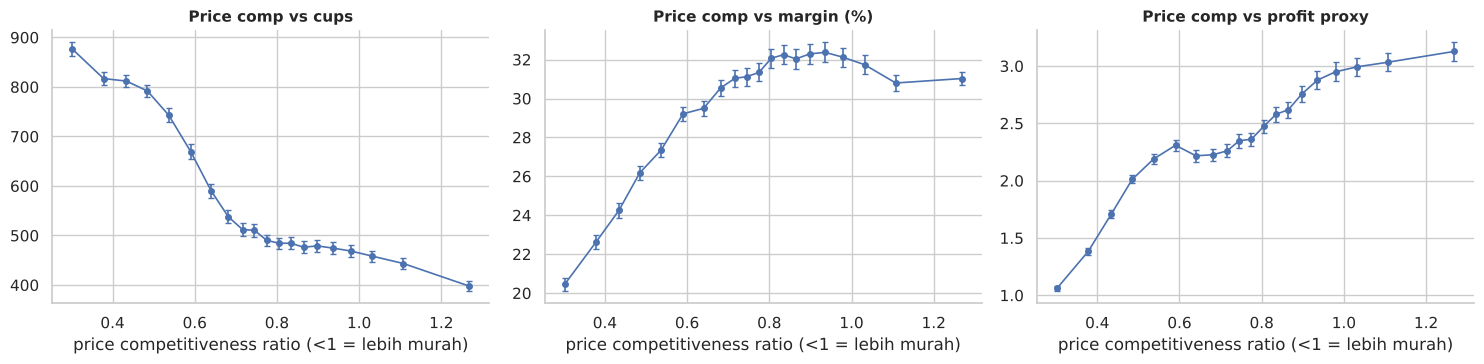

Spearman price_comp vs cups / rev / margin / profit: ['-0.60', '+0.37', '+0.42', '+0.53']
Within-brand Spearman(price_comp, margin):
brand
Fore Coffee       0.52
Kopi Janji Jiwa   0.41
Kopi Kenangan     0.47
Point Coffee      0.43
Tomoro Coffee     0.55


In [15]:
pcb = prof('pc_band'); display(pcb)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (y, t) in zip(ax, [('cups','Price comp vs cups'),('margin','Price comp vs margin (%)'),('profit_m','Price comp vs profit proxy')]):
    binned('price_comp', y, 20, a); a.set_title(t); a.set_xlabel('price competitiveness ratio (<1 = lebih murah)')
plt.tight_layout(); plt.show()
print('Spearman price_comp vs cups / rev / margin / profit:', [f'{sp("price_comp", y)[0]:+.2f}' for y in ['cups','rev','margin','profit']])
print('Within-brand Spearman(price_comp, margin):'); print(d.groupby('brand').apply(lambda g: stats.spearmanr(g.price_comp, g.margin)[0]).round(2).to_string())

### 7.3 Discount efficiency zones (diuji, bukan diasumsikan)
Profit proxy rata-rata per kelompok diskon 5 pp dengan CI 95%. **Zona efisien** = kelompok yang rata-rata profit-nya statistis tidak berbeda dari yang terbaik.

,n,profit_m,se,margin,cups,rev_m,zona_efisien
disc5,,,,,,,
0-5,358,3.11,0.04,40.82,415.65,7.68,False
5-10,716,3.51,0.04,37.58,497.73,9.55,True
10-15,1431,3.15,0.03,34.97,471.51,9.23,False
15-20,1966,2.85,0.02,32.56,557.93,8.94,False
20-25,1955,2.52,0.02,30.84,556.92,8.35,False
25-30,2035,2.24,0.01,28.99,560.62,7.95,False
30-35,1578,2.03,0.01,26.83,592.31,7.74,False
35-40,1398,1.80,0.01,24.47,632.18,7.48,False
40-45,808,1.41,0.01,21.69,683.89,6.62,False


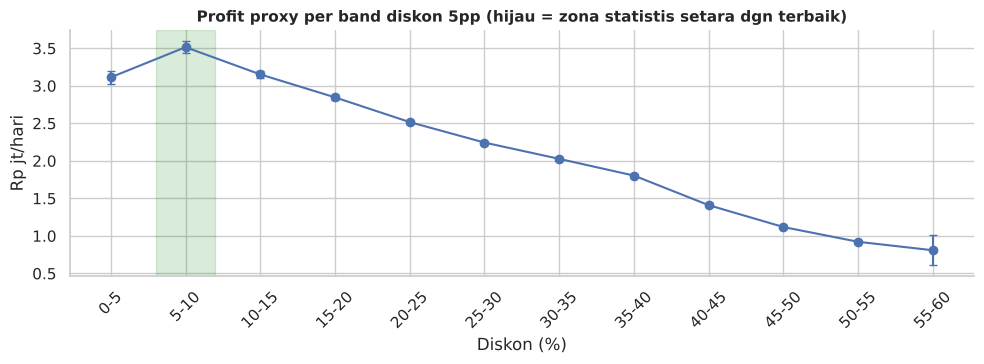

Band terbaik: 5-10 | Zona efisien (setara): ['5-10']


In [16]:
d['disc5'] = pd.cut(d.disc, np.arange(-0.01, 60, 5), labels=[f'{i}-{i+5}' for i in range(0, 60, 5)])
zdisc = d.groupby('disc5', observed=True).agg(n=('profit_m','size'), profit_m=('profit_m','mean'), se=('profit_m','sem'), margin=('margin','mean'), cups=('cups','mean'), rev_m=('rev_m','mean'))
best = zdisc.profit_m.idxmax(); lo = zdisc.loc[best,'profit_m'] - 1.96*zdisc.loc[best,'se']
zdisc['zona_efisien'] = (zdisc.profit_m + 1.96*zdisc.se >= lo) & (zdisc.n >= 30)
display(zdisc.round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.errorbar(range(len(zdisc)), zdisc.profit_m, yerr=1.96*zdisc.se, fmt='o-', capsize=3); ax.set_xticks(range(len(zdisc))); ax.set_xticklabels(zdisc.index, rotation=45)
for i, (ix, r) in enumerate(zdisc.iterrows()):
    if r.zona_efisien: ax.axvspan(i-.4, i+.4, alpha=.15, color='green')
ax.set_title('Profit proxy per band diskon 5pp (hijau = zona statistis setara dgn terbaik)'); ax.set_xlabel('Diskon (%)'); ax.set_ylabel('Rp jt/hari'); plt.tight_layout(); plt.show()
ez = list(zdisc.index[zdisc.zona_efisien]); print('Band terbaik:', best, '| Zona efisien (setara):', ez)

# 08. Competitive Landscape
**H2:** kepadatan kompetitor dapat berarti **saturasi** (kinerja gerai menurun) **atau** **demand kuat** (pasar dalam; volume naik). Kita uji keduanya: pola *dalam-kota* vs *antar-kota*.

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens,price_comp,diehard,sens_
dens_band,,,,,,,,,,,,,
0-2 (jarang),2233,565.87,"15,120.54",25.78,7.88,29.75,2.34,5.54,3.45,1.51,0.75,15.00,5.54
3-5,5600,564.34,"15,114.57",25.72,7.87,30.04,2.36,5.58,4.28,3.99,0.75,13.52,5.58
6-8,3550,583.13,"15,181.93",25.76,8.18,29.28,2.39,5.48,5.28,6.83,0.75,14.23,5.48
9+ (padat),1617,614.54,"15,405.23",25.35,8.78,27.83,2.45,5.32,6.52,10.33,0.76,11.32,5.32


,Spearman vs dens,p
metrik,,
cups,0.06,0.00
rev,0.10,0.00
margin,-0.08,0.00
price_comp,0.01,0.46
sens,-0.04,0.00
canni,0.79,0.00
loy_score,-0.13,0.00
disc,-0.01,0.41


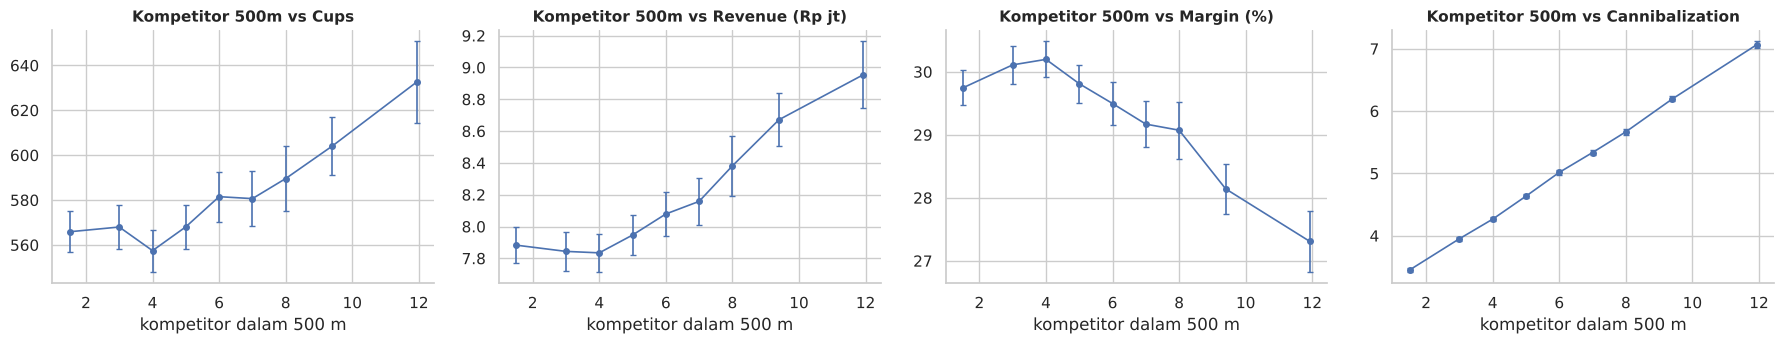

,coef_raw,p_raw,coef_kontrol,ci_low,ci_high,p_kontrol
outcome,,,,,,
np.log(cups),0.01,0.00,0.00,0.00,0.00,0.00
np.log(rev),0.01,0.00,0.01,0.00,0.01,0.00
margin,-0.23,0.00,0.01,-0.02,0.03,0.63
canni,0.35,0.00,0.34,0.34,0.34,0.00
disc,-0.04,0.25,-0.05,-0.12,0.02,0.19


Antar-kota (12 kota n>=100): Spearman dens vs rev_m = 0.08, vs cups = 0.09, vs margin = -0.37
Catatan: rev_per_comp = rev/(dens+1) menurun otomatis saat dens naik -> TIDAK dipakai sebagai bukti saturasi.


cups                                margin                       
dens_band                     0-2 (jarang)    3-5    6-8 9+ (padat) 0-2 (jarang)   3-5   6-8 9+ (padat)
fmt                                                                                                    
Cloud Kitchen / Delivery Only       376.20 391.60 385.60     375.20        35.40 35.20 35.40      35.70
Drive-Thru Highway                  441.40 446.40 455.60     442.00        32.80 32.20 33.00      31.60
Mall Kiosk                          616.50 619.20 621.80     613.80        25.10 25.50 25.40      25.50
Office Tower Lobby                  675.80 685.80 689.00     697.50        27.50 27.40 27.50      27.60
Standalone Shophouse / Ruko         566.00 566.30 568.10     543.50        31.50 31.50 31.30      31.70

In [17]:
db = prof('dens_band', extra=dict(price_comp=('price_comp','mean'), diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), sens_=('sens','mean')))
display(db)
rows = []
for y in ['cups','rev','margin','price_comp','sens','canni','loy_score','disc']:
    r, p = sp('dens', y); rows.append((y, r, p))
display(pd.DataFrame(rows, columns=['metrik','Spearman vs dens','p']).set_index('metrik').round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (y, t) in zip(ax, [('cups','Cups'),('rev_m','Revenue (Rp jt)'),('margin','Margin (%)'),('canni','Cannibalization')]):
    binned('dens', y, 14, a); a.set_title(f'Kompetitor 500m vs {t}'); a.set_xlabel('kompetitor dalam 500 m')
plt.tight_layout(); plt.show()

# Uji dua hipotesis: within-city (kontrol FE kota/merek/format) vs raw
res = []
for y in ['np.log(cups)', 'np.log(rev)', 'margin', 'canni', 'disc']:
    r0 = smf.ols(f'{y} ~ dens', d).fit(cov_type='HC3'); r1 = smf.ols(f'{y} ~ dens + C(brand) + C(city) + C(fmt) + C(order)', d).fit(cov_type='HC3')
    res.append((y, r0.params['dens'], r0.pvalues['dens'], r1.params['dens'], r1.conf_int().loc['dens'][0], r1.conf_int().loc['dens'][1], r1.pvalues['dens']))
display(pd.DataFrame(res, columns=['outcome','coef_raw','p_raw','coef_kontrol','ci_low','ci_high','p_kontrol']).set_index('outcome').round(4))

# Antar-kota vs dalam-kota
cc = d[~d.city.isin(['Batam','Palembang','Makassar','Malang'])].groupby('city').agg(dens=('dens','mean'), cups=('cups','mean'), rev_m=('rev_m','mean'), margin=('margin','mean'), n=('cups','size'))
print('Antar-kota (12 kota n>=100): Spearman dens vs rev_m = %.2f, vs cups = %.2f, vs margin = %.2f' % tuple(stats.spearmanr(cc.dens, cc[k])[0] for k in ['rev_m','cups','margin']))
print('Catatan: rev_per_comp = rev/(dens+1) menurun otomatis saat dens naik -> TIDAK dipakai sebagai bukti saturasi.')
display(prof(['fmt','dens_band']).unstack()[['cups','margin']].round(1))

**Interpretasi.** Jika kepadatan berasosiasi positif dengan cups/revenue setelah kontrol merek-kota-format, itu mendukung hipotesis *demand kuat*; jika berasosiasi negatif dengan margin/cannibalization naik, itu mendukung *tekanan saturasi*. Kedua efek dapat hadir bersamaan (volume lebih besar di lokasi ramai tetapi dengan tekanan margin/kanibalisasi), yang dibaca dari tabel koefisien di atas.

# 09. Customer Behavior & Loyalty
**Pertanyaan:** pelanggan mana yang bernilai, mengapa bernilai, dan seberapa sulit dipertahankan?

,n,cups,net_price,disc,rev_m,margin,profit_m,sens,dwell_dinein,rating,diehard,atrisk_promo,dine_in_pct
seg,,,,,,,,,,,,,
Office Corporate Workers,4660,601.05,"15,193.17",25.77,8.42,28.98,2.43,4.37,33.00,4.52,13.84,42.10,21.00
College Students & Gen Z,4111,577.43,"15,136.30",25.64,8.07,29.57,2.39,6.67,103.00,4.52,13.91,41.28,22.00
Transit Commuters,955,557.81,"15,177.84",25.59,7.90,29.97,2.36,5.66,45.50,4.52,12.46,40.10,21.00
Residential Families,1969,574.91,"15,174.52",25.58,8.07,28.85,2.33,5.16,43.00,4.51,12.60,41.70,22.00
Delivery Couriers / Ojol,1305,496.77,"15,182.29",25.85,6.96,31.88,2.20,6.38,45.00,4.53,15.02,40.61,19.00


,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens,rating
loyalty,,,,,,,,,,,
Die-Hard-Loyalist,1780,469.40,"19,518.14",9.84,9.09,36.49,3.23,3.89,3.95,5.01,4.71
Value-Conscious-Regular,5827,551.66,"16,117.14",21.83,8.41,31.21,2.57,5.13,4.40,4.78,4.51
Promo-Chaser-Opportunist,4539,656.80,"11,826.95",38.65,7.06,23.96,1.68,6.82,5.23,5.08,4.54
At-Risk-Churn-Switcher,854,534.42,"17,415.04",16.28,8.97,32.83,2.90,4.54,5.29,7.98,4.00


,n,cups,net_price,disc,rev_m,margin,profit_m,sens,canni,dens
order,,,,,,,,,,
Dine-In POS Cashier,2760,574.10,"15,194.98",25.54,8.07,29.58,2.38,5.49,4.69,5.14
Mobile App Pickup,5908,577.12,"15,263.72",25.60,8.14,29.49,2.39,5.49,4.71,5.18
Online Ojol Delivery,4332,575.61,"15,026.70",25.93,7.98,29.49,2.35,5.56,4.66,5.05


**Segmen x Order method (% baris)**

order,Dine-In POS Cashier,Mobile App Pickup,Online Ojol Delivery
seg,,,
College Students & Gen Z,21.50,44.80,33.70
Delivery Couriers / Ojol,19.40,45.70,34.90
Office Corporate Workers,21.40,45.30,33.40
Residential Families,21.60,46.70,31.70
Transit Commuters,21.20,46.30,32.60


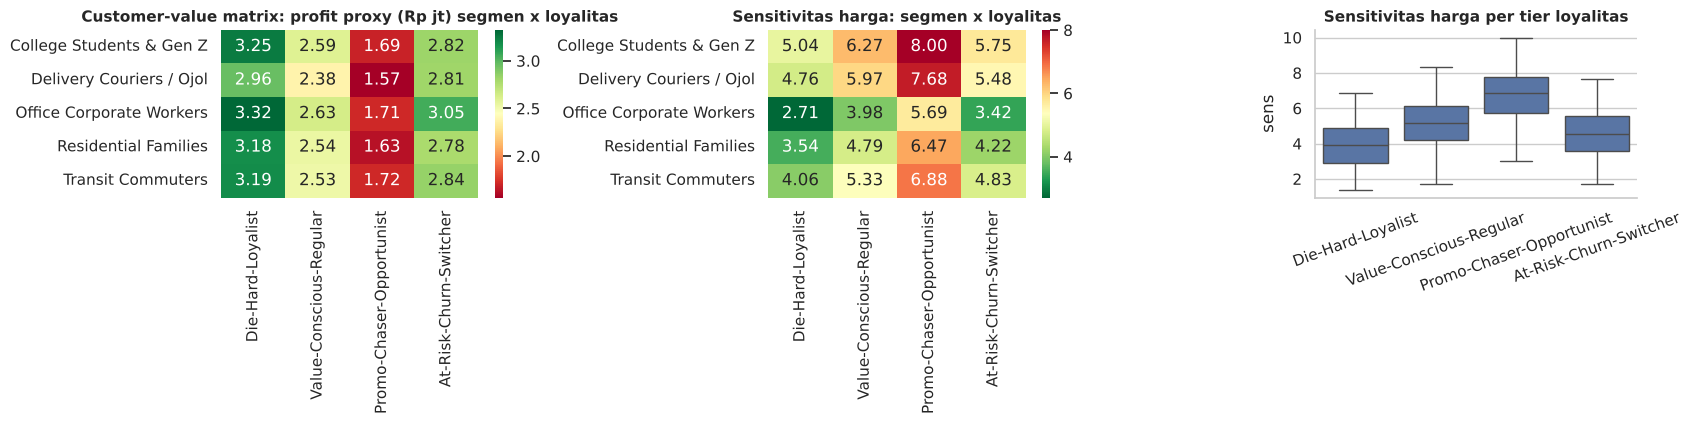

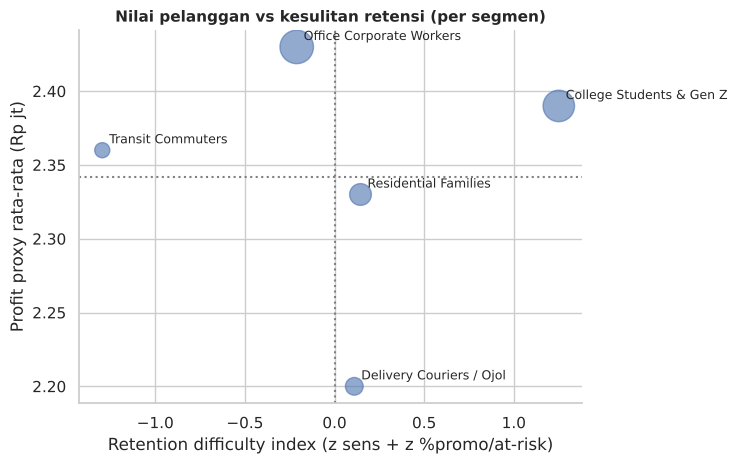

Interaksi sens x loyalitas pada margin (kontrol diskon): R2=0.597; koefisien sens utama=0.879
Korelasi Spearman sens vs diskon = 0.68 | sens vs margin = -0.45 | sens vs loy_score = -0.45


In [18]:
cs = d.groupby('seg').agg(n=('cups','size'), cups=('cups','mean'), net_price=('net_price','mean'), disc=('disc','mean'), rev_m=('rev_m','mean'), margin=('margin','mean'), profit_m=('profit_m','mean'),
        sens=('sens','mean'), dwell_dinein=('dwell_dinein','median'), rating=('rating','mean'), diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), atrisk_promo=('loyalty', lambda s: s.isin(LOY[2:]).mean()*100),
        dine_in_pct=('is_dinein','mean')).round(2)
cs['dine_in_pct'] *= 100
display(cs.sort_values('profit_m', ascending=False))
ls = prof('loyalty', extra=dict(rating=('rating','mean'))); display(ls)
display(prof('order'))
md_('**Segmen x Order method (% baris)**'); display((pd.crosstab(d.seg, d.order, normalize='index')*100).round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.heatmap(d.pivot_table(index='seg', columns='loyalty', values='profit_m', aggfunc='mean', observed=True), annot=True, fmt='.2f', cmap='RdYlGn', ax=ax[0]); ax[0].set_title('Customer-value matrix: profit proxy (Rp jt) segmen x loyalitas'); ax[0].set_ylabel(''); ax[0].set_xlabel('')
sns.heatmap(d.pivot_table(index='seg', columns='loyalty', values='sens', aggfunc='mean', observed=True), annot=True, fmt='.2f', cmap='RdYlGn_r', ax=ax[1]); ax[1].set_title('Sensitivitas harga: segmen x loyalitas'); ax[1].set_ylabel(''); ax[1].set_xlabel('')
sns.boxplot(data=d, x='loyalty', y='sens', order=LOY, ax=ax[2]); ax[2].set_title('Sensitivitas harga per tier loyalitas'); ax[2].tick_params(axis='x', rotation=20); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

# Nilai vs kesulitan retensi (per segmen)
cs['retention_difficulty'] = (cs.sens - cs.sens.mean())/cs.sens.std() + (cs.atrisk_promo - cs.atrisk_promo.mean())/cs.atrisk_promo.std()
fig, ax = plt.subplots(figsize=(7.5, 4.8)); ax.scatter(cs.retention_difficulty, cs.profit_m, s=cs.n/8, alpha=.6)
for s_, r in cs.iterrows(): ax.annotate(s_, (r.retention_difficulty, r.profit_m), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.axvline(0, ls=':', c='grey'); ax.axhline(cs.profit_m.mean(), ls=':', c='grey')
ax.set_xlabel('Retention difficulty index (z sens + z %promo/at-risk)'); ax.set_ylabel('Profit proxy rata-rata (Rp jt)'); ax.set_title('Nilai pelanggan vs kesulitan retensi (per segmen)'); plt.tight_layout(); plt.show()

# Interaksi loyalitas x sensitivitas harga terhadap margin
m_int = smf.ols('margin ~ sens * C(loyalty) + disc', d).fit(cov_type='HC3')
print(f'Interaksi sens x loyalitas pada margin (kontrol diskon): R2={m_int.rsquared:.3f}; koefisien sens utama={m_int.params["sens"]:.3f}')
print('Korelasi Spearman sens vs diskon =', round(sp('sens','disc')[0],2), '| sens vs margin =', round(sp('sens','margin')[0],2), '| sens vs loy_score =', round(sp('sens','loy_score')[0],2))

### 9.2 Switching & churn drivers
Pemicu dikelompokkan: **price-driven** (kompetitor lebih murah), **promotion-driven** (voucher habis/kenaikan harga), **experience-driven** (rasa tidak konsisten; kurang tempat duduk/WiFi), **availability/convenience-driven** (antrean/pickup lambat).

**Distribusi pemicu switching**

,% (pemicu),% (kelompok)
switch,,
Cheaper-Competitor-Opening,30.50,NaN
Taste-Inconsistency-Drop,25.30,NaN
Long-Queue-Pickup-Delay,21.20,NaN
Lack-Of-Seating-WiFi,15.30,NaN
Voucher-Exhaustion-Price-Hike,7.70,NaN
Experience-driven,NaN,40.60
Price-driven,NaN,30.50
Availability/Convenience-driven,NaN,21.20
Promotion-driven,NaN,7.70


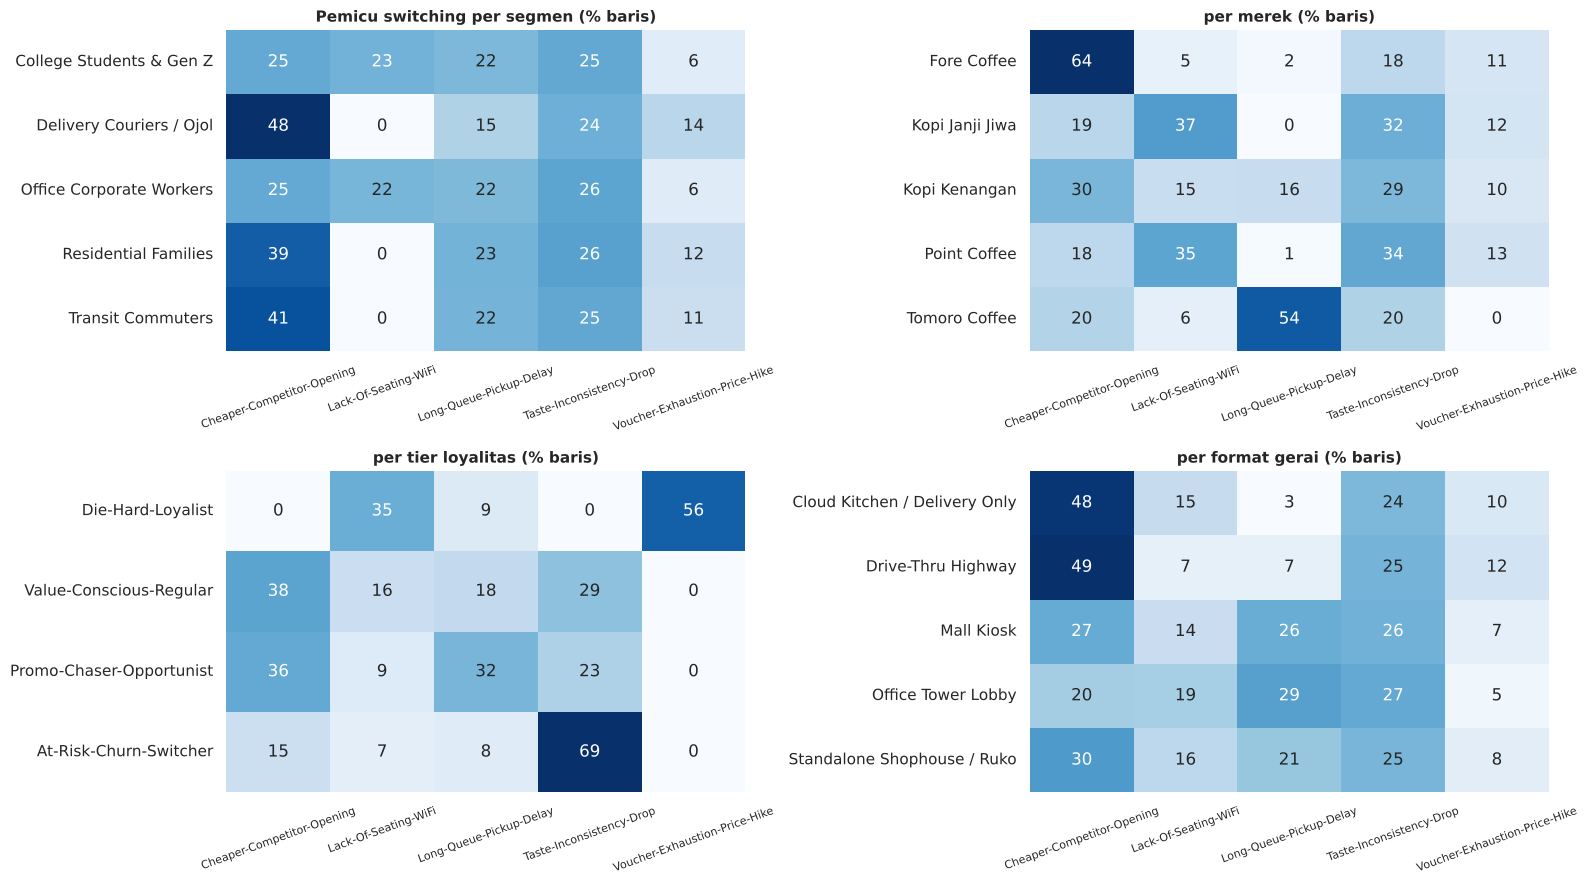

,Cramers_V,p
faktor,,
loyalty,0.49,0.00
brand,0.35,0.00
disc_band,0.27,0.00
seg,0.17,0.00
fmt,0.13,0.00
order,0.11,0.00
dens_band,0.06,0.00
city,0.04,0.14


**Profil numerik per pemicu**

,n,disc,sens,dens,price_comp,margin,cups
switch,,,,,,,
Cheaper-Competitor-Opening,3961,28.77,5.54,4.99,0.81,28.50,474.35
Lack-Of-Seating-WiFi,1989,21.23,5.07,5.05,0.79,32.59,510.17
Long-Queue-Pickup-Delay,2758,31.47,6.54,5.16,0.54,25.10,834.42
Taste-Inconsistency-Drop,3292,24.51,5.40,5.37,0.76,30.55,562.87
Voucher-Exhaustion-Price-Hike,1000,10.35,3.83,4.90,1.01,36.12,439.75


**Pemicu per band kepadatan & band diskon (% baris)**

switch,Cheaper-Competitor-Opening,Lack-Of-Seating-WiFi,Long-Queue-Pickup-Delay,Taste-Inconsistency-Drop,Voucher-Exhaustion-Price-Hike
dens_band,,,,,
0-2 (jarang),29.20,17.10,20.80,24.50,8.50
3-5,32.30,14.80,20.90,24.20,7.90
6-8,31.30,15.40,22.40,23.10,7.80
9+ (padat),24.20,14.20,20.50,35.50,5.60


switch,Cheaper-Competitor-Opening,Lack-Of-Seating-WiFi,Long-Queue-Pickup-Delay,Taste-Inconsistency-Drop,Voucher-Exhaustion-Price-Hike
disc_band,,,,,
0-10,0.00,28.00,6.60,32.80,32.60
10-20,22.60,18.50,13.60,26.40,18.80
20-30,39.20,16.20,19.10,25.50,0.00
30-40,40.60,10.70,25.50,23.10,0.00
40+,27.40,5.60,45.60,21.40,0.00


In [19]:
md_('**Distribusi pemicu switching**')
sd = pd.concat([d.switch.value_counts(normalize=True).mul(100).rename('% (pemicu)'), d.switch.map(SW).value_counts(normalize=True).mul(100).rename('% (kelompok)')], axis=1); display(sd.round(1))
def ct(col, tgt='switch'): return (pd.crosstab(d[col], d[tgt], normalize='index')*100).round(1)
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for a, (col, t) in zip(ax.flat, [('seg','Pemicu switching per segmen'),('brand','per merek'),('loyalty','per tier loyalitas'),('fmt','per format gerai')]):
    sns.heatmap(ct(col), annot=True, fmt='.0f', cmap='Blues', ax=a, cbar=False); a.set_title(t + ' (% baris)'); a.set_ylabel(''); a.set_xlabel(''); a.tick_params(axis='x', rotation=20, labelsize=8)
plt.tight_layout(); plt.show()

# Signifikansi & kekuatan asosiasi (Cramer's V)
def cramers(a, b):
    t = pd.crosstab(a, b); chi2, p, dof, _ = stats.chi2_contingency(t); n = t.values.sum(); return np.sqrt(chi2/(n*(min(t.shape)-1))), p
rows = [(c, *cramers(d[c], d.switch)) for c in ['seg','brand','loyalty','fmt','order','dens_band','disc_band','city']]
display(pd.DataFrame(rows, columns=['faktor','Cramers_V','p']).set_index('faktor').round(4).sort_values('Cramers_V', ascending=False))
md_('**Profil numerik per pemicu**'); display(d.groupby('switch').agg(n=('cups','size'), disc=('disc','mean'), sens=('sens','mean'), dens=('dens','mean'), price_comp=('price_comp','mean'), margin=('margin','mean'), cups=('cups','mean')).round(2))
md_('**Pemicu per band kepadatan & band diskon (% baris)**'); display(ct('dens_band')); display(ct('disc_band'))

# 10. Store Format & Geographic Economics
**Pertanyaan utama:** format mana menghasilkan ekonomi *risk-adjusted* terbaik? (bukan sekadar revenue kotor)

,n,cups,net_price,disc,rev_m,margin,margin_p10,low_margin_pct,profit_m,profit_sd,dwell_dinein,dens,canni,sens,profit_cv,risk_adj_profit,margin_resid_after_disc_brand
fmt,,,,,,,,,,,,,,,,,
Standalone Shophouse / Ruko,4501,565.38,"15,125.40",25.74,7.89,31.47,23.90,4.31,2.51,0.94,50.00,4.56,4.87,5.76,0.37,2.67,1.95
Office Tower Lobby,2553,687.70,"15,232.93",25.80,9.69,27.47,19.90,18.64,2.69,1.01,38.00,5.83,4.91,4.91,0.38,2.66,-2.05
Drive-Thru Highway,832,447.67,"15,098.16",25.50,6.30,32.46,25.50,2.64,2.06,0.81,47.00,4.64,3.29,5.50,0.39,2.54,2.88
Mall Kiosk,3613,618.50,"15,161.52",25.59,8.65,25.43,17.80,27.82,2.23,0.88,46.00,5.71,5.06,5.56,0.39,2.53,-4.09
Cloud Kitchen / Delivery Only,1501,386.48,"15,258.15",25.74,5.43,35.31,27.90,0.00,1.94,0.78,43.00,4.49,3.65,5.68,0.40,2.49,5.90


**Segmen per format (% baris)**

seg,College Students & Gen Z,Delivery Couriers / Ojol,Office Corporate Workers,Residential Families,Transit Commuters
fmt,,,,,
Cloud Kitchen / Delivery Only,23.30,36.40,34.20,3.70,2.40
Drive-Thru Highway,14.30,9.90,19.40,25.80,30.60
Mall Kiosk,35.90,5.40,29.00,24.80,4.90
Office Tower Lobby,14.90,4.40,70.80,2.00,7.90
Standalone Shophouse / Ruko,43.60,8.20,25.10,16.70,6.40


**Order method per format (% baris)**

order,Dine-In POS Cashier,Mobile App Pickup,Online Ojol Delivery
fmt,,,
Cloud Kitchen / Delivery Only,21.40,45.20,33.40
Drive-Thru Highway,20.20,42.50,37.30
Mall Kiosk,21.30,46.30,32.40
Office Tower Lobby,21.60,44.80,33.60
Standalone Shophouse / Ruko,21.10,45.70,33.20


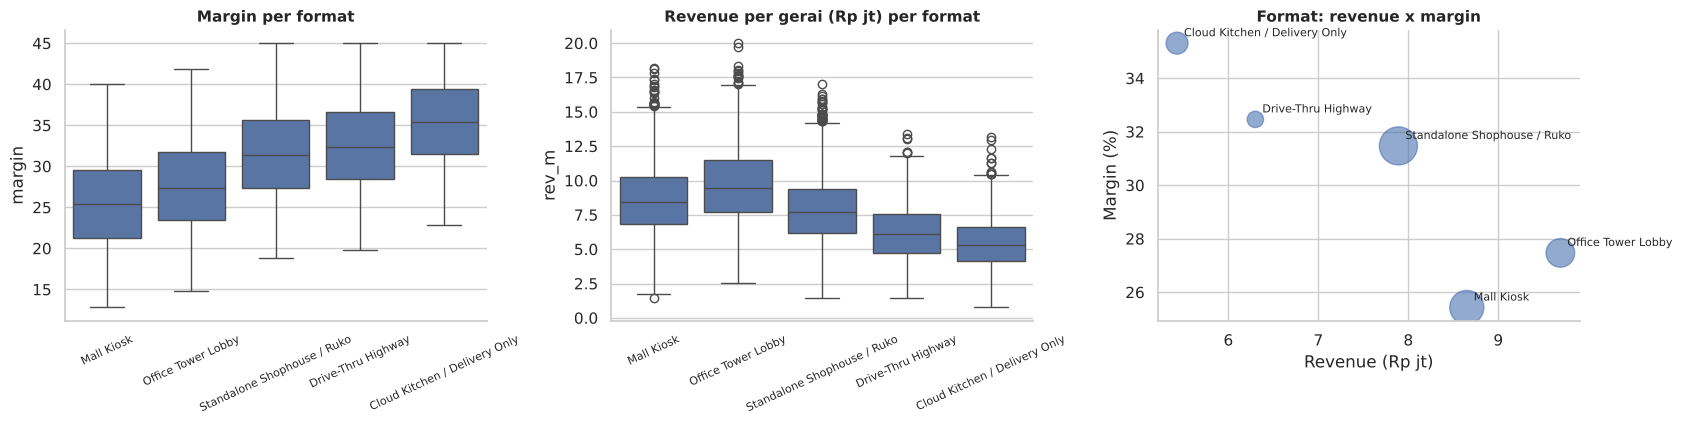

In [20]:
fa = d.groupby('fmt').agg(n=('cups','size'), cups=('cups','mean'), net_price=('net_price','mean'), disc=('disc','mean'), rev_m=('rev_m','mean'), margin=('margin','mean'),
        margin_p10=('margin', lambda s: s.quantile(.1)), low_margin_pct=('margin', lambda s: (s<22).mean()*100), profit_m=('profit_m','mean'), profit_sd=('profit_m','std'),
        dwell_dinein=('dwell_dinein','median'), dens=('dens','mean'), canni=('canni','mean'), sens=('sens','mean')).round(2)
fa['profit_cv'] = (fa.profit_sd/fa.profit_m).round(2); fa['risk_adj_profit'] = (fa.profit_m/fa.profit_sd).round(2)
d['margin_resid_brand'] = smf.ols('margin ~ disc + C(brand)', d).fit().resid
fa['margin_resid_after_disc_brand'] = d.groupby('fmt').margin_resid_brand.mean().round(2)
display(fa.sort_values('risk_adj_profit', ascending=False))
md_('**Segmen per format (% baris)**'); display((pd.crosstab(d.fmt, d.seg, normalize='index')*100).round(1))
md_('**Order method per format (% baris)**'); display((pd.crosstab(d.fmt, d.order, normalize='index')*100).round(1))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.boxplot(data=d, x='fmt', y='margin', ax=ax[0], order=fa.sort_values('margin').index); ax[0].set_title('Margin per format'); ax[0].tick_params(axis='x', rotation=25, labelsize=8); ax[0].set_xlabel('')
sns.boxplot(data=d, x='fmt', y='rev_m', ax=ax[1], order=fa.sort_values('margin').index); ax[1].set_title('Revenue per gerai (Rp jt) per format'); ax[1].tick_params(axis='x', rotation=25, labelsize=8); ax[1].set_xlabel('')
ax[2].scatter(fa.rev_m, fa.margin, s=fa.n/6, alpha=.6)
for f_, r in fa.iterrows(): ax[2].annotate(f_, (r.rev_m, r.margin), xytext=(5, 5), textcoords='offset points', fontsize=8)
ax[2].set_xlabel('Revenue (Rp jt)'); ax[2].set_ylabel('Margin (%)'); ax[2].set_title('Format: revenue x margin')
plt.tight_layout(); plt.show()

### 10.2 Geographic market analysis & Market Attractiveness Framework
Konsep: **Attractiveness = Commercial + Customer + Margin - Competition risk - Cannibalization risk - Discount dependence.**  
Semua komponen distandardisasi (z-score antar-kota). **Bobot dasar sama (1/6 tiap komponen)** karena tidak ada dasar empiris untuk membedakan; kemudian diuji dengan **5.000 undian bobot acak (Dirichlet)** untuk melihat stabilitas peringkat. Kota dengan n<100 ditandai *sampel kecil* dan tidak diberi peringkat.

,n,rev_m,cups,margin,profit_m,dens,price_comp,diehard,sens,canni,disc,rating,small_n
city,,,,,,,,,,,,,
Makassar,67,9.85,618.45,29.17,2.86,3.87,0.75,8.96,5.27,4.33,25.14,4.64,True
Batam,32,9.50,622.50,30.02,2.82,3.00,0.76,15.62,5.52,4.00,24.03,4.53,True
Malang,90,8.86,602.10,28.79,2.51,3.24,0.74,6.67,5.46,4.06,26.12,4.57,True
Palembang,63,8.46,546.03,29.53,2.47,3.30,0.74,9.52,5.62,4.10,25.82,4.56,True
Depok,564,8.18,574.68,29.91,2.44,3.51,0.76,14.54,5.42,4.12,24.93,4.52,False
Semarang,535,8.24,586.81,29.65,2.43,3.99,0.75,13.46,5.53,4.28,25.24,4.51,False
Bekasi,903,8.20,580.71,29.47,2.41,3.61,0.75,12.96,5.50,4.18,25.93,4.51,False
Yogyakarta,391,8.13,581.32,29.44,2.40,3.58,0.75,10.23,5.58,4.15,25.93,4.56,False
Jakarta Pusat,1724,8.14,580.15,29.46,2.39,6.43,0.75,15.31,5.47,5.13,25.52,4.52,False


,n,score,rank_equal,rank_median,rank_p5,rank_p95,top3_freq_%,Commercial,Customer,Margin,CompetitionRisk,CannibalizationRisk,DiscountDependence
city,,,,,,,,,,,,,
Depok,564,1.37,1,1.00,1.00,1.00,100.00,1.04,1.43,2.18,-0.80,-0.84,-1.94
Semarang,535,0.68,2,2.00,2.00,4.00,92.32,1.60,-0.24,0.63,-0.45,-0.49,-1.15
Tangerang Selatan,1136,0.38,3,3.00,2.00,7.00,60.94,-1.17,0.30,0.98,-0.62,-0.67,-0.84
Bekasi,903,0.25,4,5.00,3.00,7.00,33.66,1.23,-0.10,-0.45,-0.73,-0.71,0.62
Bandung,1391,0.19,5,5.00,4.00,6.00,0.56,-0.61,0.12,0.15,-0.62,-0.62,-0.25
Jakarta Pusat,1724,-0.16,6,7.00,3.00,10.00,8.02,0.67,1.17,-0.51,1.37,1.36,-0.43
Bali Badung,271,-0.17,7,7.00,4.00,11.00,4.30,-1.35,0.40,0.09,-0.89,-0.71,1.75
Yogyakarta,391,-0.20,8,7.00,4.00,12.00,0.20,0.58,-2.08,-0.63,-0.75,-0.78,0.62
Medan,689,-0.22,9,8.00,7.00,10.00,0.00,-0.52,-0.40,-1.10,-0.51,-0.56,0.37


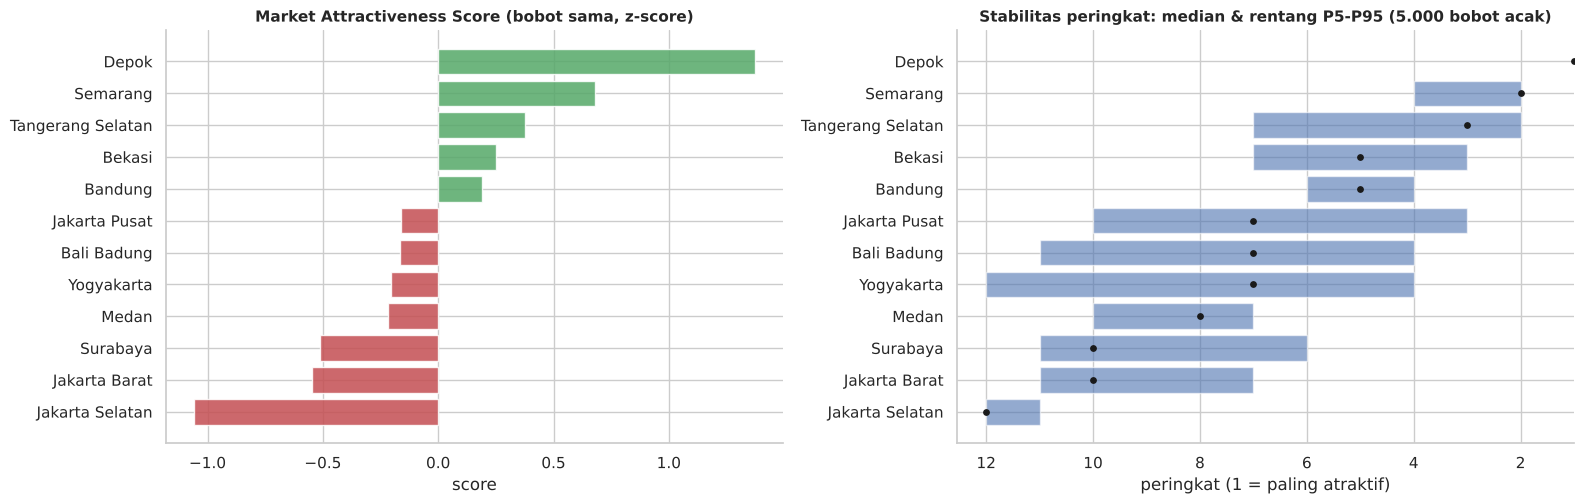

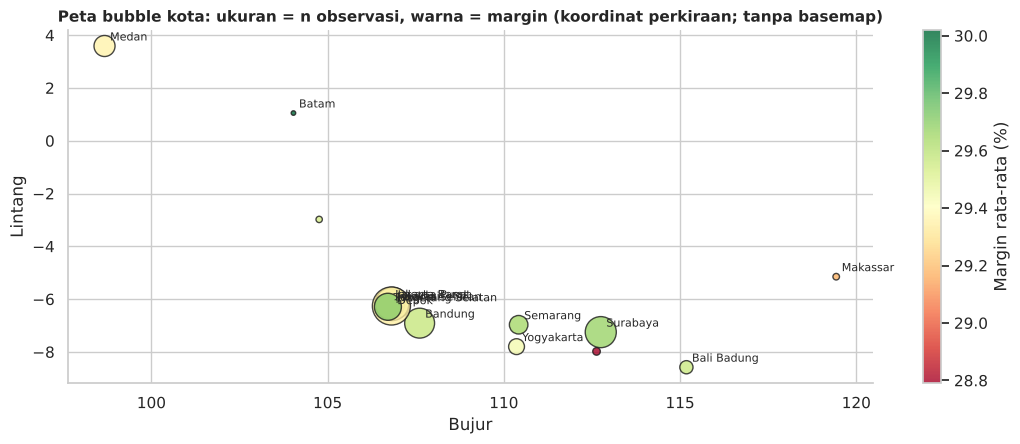

In [21]:
ca = d.groupby('city').agg(n=('cups','size'), rev_m=('rev_m','mean'), cups=('cups','mean'), margin=('margin','mean'), profit_m=('profit_m','mean'), dens=('dens','mean'), price_comp=('price_comp','mean'),
        diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), sens=('sens','mean'), canni=('canni','mean'), disc=('disc','mean'), rating=('rating','mean')).round(2)
ca['small_n'] = ca.n < 100
display(ca.sort_values('profit_m', ascending=False))

K = ca[~ca.small_n].copy(); z = lambda s: (s - s.mean())/s.std()
comp = pd.DataFrame({'Commercial': z(K.rev_m), 'Customer': (z(K.diehard) - z(K.sens))/2, 'Margin': z(K.margin), 'CompetitionRisk': z(K.dens), 'CannibalizationRisk': z(K.canni), 'DiscountDependence': z(K.disc)})
sign = np.array([1, 1, 1, -1, -1, -1]); W0 = np.ones(6)/6
K['score'] = comp.values @ (W0*sign); K['rank_equal'] = K.score.rank(ascending=False).astype(int)
Ws = rng.dirichlet(np.ones(6), 5000); S = comp.values @ (Ws*sign).T
R = pd.DataFrame(S, index=K.index).rank(ascending=False)
K['rank_median'] = R.median(axis=1); K['rank_p5'] = R.quantile(.05, axis=1); K['rank_p95'] = R.quantile(.95, axis=1); K['top3_freq_%'] = (R <= 3).mean(axis=1)*100
display(pd.concat([K[['n','score','rank_equal','rank_median','rank_p5','rank_p95','top3_freq_%']], comp.round(2)], axis=1).sort_values('rank_equal').round(2))

fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
ks = K.sort_values('score'); ax[0].barh(ks.index, ks.score, color=np.where(ks.score>0, '#55A868', '#C44E52'), alpha=.85)
ax[0].set_title('Market Attractiveness Score (bobot sama, z-score)'); ax[0].set_xlabel('score')
ax[1].barh(ks.index, ks.rank_p95-ks.rank_p5, left=ks.rank_p5, color='#4C72B0', alpha=.6); ax[1].scatter(ks.rank_median, ks.index, c='k', s=15, zorder=3)
ax[1].set_title('Stabilitas peringkat: median & rentang P5-P95 (5.000 bobot acak)'); ax[1].set_xlabel('peringkat (1 = paling atraktif)'); ax[1].invert_xaxis()
plt.tight_layout(); plt.show()

# Geographic view (koordinat perkiraan analis - bukan bagian dataset)
XY = {'Jakarta Selatan':(-6.26,106.81),'Jakarta Pusat':(-6.18,106.83),'Jakarta Barat':(-6.17,106.76),'Tangerang Selatan':(-6.29,106.71),'Bekasi':(-6.24,106.99),'Depok':(-6.40,106.82),'Bandung':(-6.91,107.61),
      'Surabaya':(-7.25,112.75),'Semarang':(-6.97,110.42),'Yogyakarta':(-7.80,110.36),'Malang':(-7.98,112.63),'Bali Badung':(-8.58,115.18),'Medan':(3.59,98.67),'Batam':(1.05,104.03),'Palembang':(-2.98,104.76),'Makassar':(-5.15,119.43)}
fig, ax = plt.subplots(figsize=(11, 4.6)); g = ca.copy(); g['lat'] = [XY[c][0] for c in g.index]; g['lon'] = [XY[c][1] for c in g.index]
sc = ax.scatter(g.lon, g.lat, s=g.n/3, c=g.margin, cmap='RdYlGn', edgecolor='k', alpha=.8); plt.colorbar(sc, label='Margin rata-rata (%)')
for c, r in g.iterrows():
    if r.n >= 300 or c in ('Medan','Bali Badung','Makassar','Batam'): ax.annotate(c, (r.lon, r.lat), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_title('Peta bubble kota: ukuran = n observasi, warna = margin (koordinat perkiraan; tanpa basemap)'); ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang'); plt.tight_layout(); plt.show()

### 10.3 Uji materialitas: apakah perbedaan antar-kota benar-benar berarti?
Skor atraktivitas memakai z-score, yang **memperbesar** selisih sekecil apa pun. Sebelum menafsirkan peringkat, kita ukur berapa banyak variasi kinerja yang benar-benar dijelaskan oleh kota (eta-kuadrat) dibanding dimensi lain.

In [22]:
eta = pd.DataFrame({g: {y: smf.ols(f'{y} ~ C({g})', d).fit().rsquared for y in ['rev_m','cups','margin','profit_m','disc']} for g in ['city','brand','fmt','loyalty','seg']}).T
eta.columns = ['revenue','cups','margin','profit_proxy','diskon']; display((eta*100).round(2).rename_axis('dimensi (% variasi dijelaskan)'))
Kc = ca[~ca.small_n]; rel = pd.DataFrame({'min': Kc[['rev_m','margin','profit_m']].min(), 'max': Kc[['rev_m','margin','profit_m']].max()}); rel['rentang_relatif_%'] = (rel['max']/rel['min']-1)*100; display(rel.round(2))
dense_c = ca.dens.sort_values(ascending=False).head(4).index.tolist()
print('Kota dengan kepadatan kompetitor tertinggi:', dense_c, '| rata-rata dens:', ca.loc[dense_c,'dens'].mean().round(2), 'vs kota lain:', ca.drop(dense_c).dens.mean().round(2))
print(f'Kota hanya menjelaskan {eta.loc["city","profit_proxy"]*100:.2f}% variasi profit proxy vs format {eta.loc["fmt","profit_proxy"]*100:.1f}% dan brand {eta.loc["brand","profit_proxy"]*100:.1f}%.')
print('KESIMPULAN: perbedaan antar-kota kecil secara ekonomi. Peringkat atraktivitas kota hanya indikatif; satu-satunya pembeda geografis yang jelas adalah kepadatan kompetitor (kluster kota Jakarta + Surabaya).')

,revenue,cups,margin,profit_proxy,diskon
dimensi (% variasi dijelaskan),,,,,
city,0.48,0.09,0.06,0.33,0.07
brand,22.44,58.05,40.72,22.42,28.58
fmt,22.25,17.42,25.89,6.78,0.01
loyalty,8.28,8.96,44.87,34.12,76.20
seg,2.33,1.87,1.73,0.53,0.01


,min,max,rentang_relatif_%
rev_m,7.92,8.24,4.04
margin,29.34,29.91,1.94
profit_m,2.33,2.44,4.72


Kota dengan kepadatan kompetitor tertinggi: ['Jakarta Pusat', 'Jakarta Selatan', 'Surabaya', 'Jakarta Barat'] | rata-rata dens: 6.4 vs kota lain: 3.58
Kota hanya menjelaskan 0.33% variasi profit proxy vs format 6.8% dan brand 22.4%.
KESIMPULAN: perbedaan antar-kota kecil secara ekonomi. Peringkat atraktivitas kota hanya indikatif; satu-satunya pembeda geografis yang jelas adalah kepadatan kompetitor (kluster kota Jakarta + Surabaya).


# 11. Revenue Quality & Profitability
## 11.1 Revenue Quality - metodologi terdefinisi dan divalidasi
**Definisi.** *Quality score* = rata-rata peringkat persentil dari enam komponen: margin (+), diskon (-), skor loyalitas (+), sensitivitas harga (-), kepadatan kompetitor (-), cannibalization (-). Bobot sama; tertil atas = **High-quality**, tertil bawah = **Low-quality**.  
**Validasi:** (a) kesesuaian dengan definisi alternatif berbasis aturan; (b) hubungan dengan variabel yang **tidak** menjadi komponen (rating, profit proxy, cups); (c) stabilitas lintas merek.

In [23]:
pr = lambda s: s.rank(pct=True)
comps = pd.DataFrame({'margin': pr(d.margin), 'disc': 1-pr(d.disc), 'loyalty': pr(d.loy_score), 'sens': 1-pr(d.sens), 'dens': 1-pr(d.dens), 'canni': 1-pr(d.canni)})
display(comps.corr(method='spearman').round(2))
d['rq_score'] = comps.mean(axis=1)
d['rq_class'] = pd.qcut(d.rq_score, [0, 1/3, 2/3, 1], labels=['Low-quality','Mid','High-quality'])
# alternatif aturan
d['rq_rule'] = np.select([(d.margin >= d.margin.median()) & (d.disc <= 30) & d.loyalty.isin(LOY[:2]) & (d.sens <= d.sens.median()), (d.margin < d.margin.quantile(.33)) & (d.disc > 30)], ['High-quality','Low-quality'], 'Mid')
agree = (pd.crosstab(d.rq_class, d.rq_rule, normalize='index')*100).round(1)
print('Kesesuaian definisi skor (baris) vs aturan (kolom), % baris:'); display(agree)
tau = stats.spearmanr(d.rq_score, d.rq_rule.map({'Low-quality':0,'Mid':1,'High-quality':2}))[0]; print(f'Spearman skor vs aturan = {tau:.2f}')

rq = d.groupby('rq_class', observed=True).agg(n=('cups','size'), rev_m=('rev_m','mean'), rev_share=('rev', lambda s: s.sum()/d.rev.sum()*100), profit_share=('profit', lambda s: s.sum()/d.profit.sum()*100),
        margin=('margin','mean'), disc=('disc','mean'), cups=('cups','mean'), net_price=('net_price','mean'), rating=('rating','mean'), sens=('sens','mean'), dens=('dens','mean'), canni=('canni','mean'), diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100)).round(2)
display(rq)
md_('**Validasi di luar komponen** - rating & cups tidak dipakai dalam skor:'); print('Spearman skor vs rating =', round(sp('rq_score','rating')[0],3), '| vs cups =', round(sp('rq_score','cups')[0],3), '| vs profit =', round(sp('rq_score','profit')[0],3))
md_('**Komposisi kualitas revenue per merek & format (% revenue)**')
tmp = d.pivot_table(index='brand', columns='rq_class', values='rev', aggfunc='sum', observed=True); display((tmp.div(tmp.sum(axis=1), axis=0)*100).round(1))
tmp = d.pivot_table(index='fmt', columns='rq_class', values='rev', aggfunc='sum', observed=True); display((tmp.div(tmp.sum(axis=1), axis=0)*100).round(1))

,margin,disc,loyalty,sens,dens,canni
margin,1.00,0.75,0.52,0.45,0.08,0.47
disc,0.75,1.00,0.67,0.68,-0.01,0.41
loyalty,0.52,0.67,1.00,0.45,0.13,0.41
sens,0.45,0.68,0.45,1.00,-0.04,0.26
dens,0.08,-0.01,0.13,-0.04,1.00,0.79
canni,0.47,0.41,0.41,0.26,0.79,1.00


Kesesuaian definisi skor (baris) vs aturan (kolom), % baris:


rq_rule,High-quality,Low-quality,Mid
rq_class,,,
Low-quality,0.10,63.80,36.10
Mid,14.50,8.50,77.00
High-quality,68.40,0.00,31.60


Spearman skor vs aturan = 0.80


,n,rev_m,rev_share,profit_share,margin,disc,cups,net_price,rating,sens,dens,canni,diehard
rq_class,,,,,,,,,,,,,
Low-quality,4334,7.47,30.86,24.97,23.66,36.80,686.48,"11,874.08",4.52,6.82,6.47,5.71,0.00
Mid,4333,8.24,34.03,34.00,29.79,25.18,561.83,"15,472.60",4.50,5.43,5.17,4.69,3.09
High-quality,4333,8.50,35.11,41.03,35.07,15.10,479.59,"18,164.50",4.53,4.29,3.75,3.67,37.99


**Validasi di luar komponen** - rating & cups tidak dipakai dalam skor:

Spearman skor vs rating = 0.002 | vs cups = -0.42 | vs profit = 0.536


**Komposisi kualitas revenue per merek & format (% revenue)**

rq_class,Low-quality,Mid,High-quality
brand,,,
Fore Coffee,30.30,36.00,33.70
Kopi Janji Jiwa,10.90,33.00,56.10
Kopi Kenangan,22.80,35.00,42.20
Point Coffee,5.80,32.20,62.00
Tomoro Coffee,56.00,32.50,11.40


rq_class,Low-quality,Mid,High-quality
fmt,,,
Cloud Kitchen / Delivery Only,14.50,31.50,54.00
Drive-Thru Highway,15.50,33.30,51.20
Mall Kiosk,40.20,33.60,26.20
Office Tower Lobby,32.30,34.90,32.80
Standalone Shophouse / Ruko,27.70,34.50,37.90


## 11.2 Profitability matrix (Hidden Gem / Star / Underperformer / Volume Trap)
Ambang: **median revenue** dan **median margin** observasi. Sensitivitas ambang diuji di Bagian 13.

,n,n_share,rev_share,profit_share,cups,net_price,disc,margin,rev_m,sens,canni,dens,diehard,atrisk_promo
quad,,,,,,,,,,,,,,
Star,3060,23.54,30.30,35.01,593.40,"18,123.12",16.05,34.07,10.39,4.49,4.37,5.08,31.14,16.60
Hidden Gem,3459,26.61,19.02,22.88,390.76,"15,646.48",20.62,35.56,5.77,5.24,4.09,4.76,19.17,22.67
Volume Trap,3440,26.46,33.07,28.22,694.36,"15,633.57",28.01,24.95,10.09,5.42,5.10,5.65,4.48,46.02
Underperformer,3041,23.39,17.61,13.89,635.21,"11,132.67",38.55,23.21,6.08,6.96,5.23,5.00,0.33,82.80


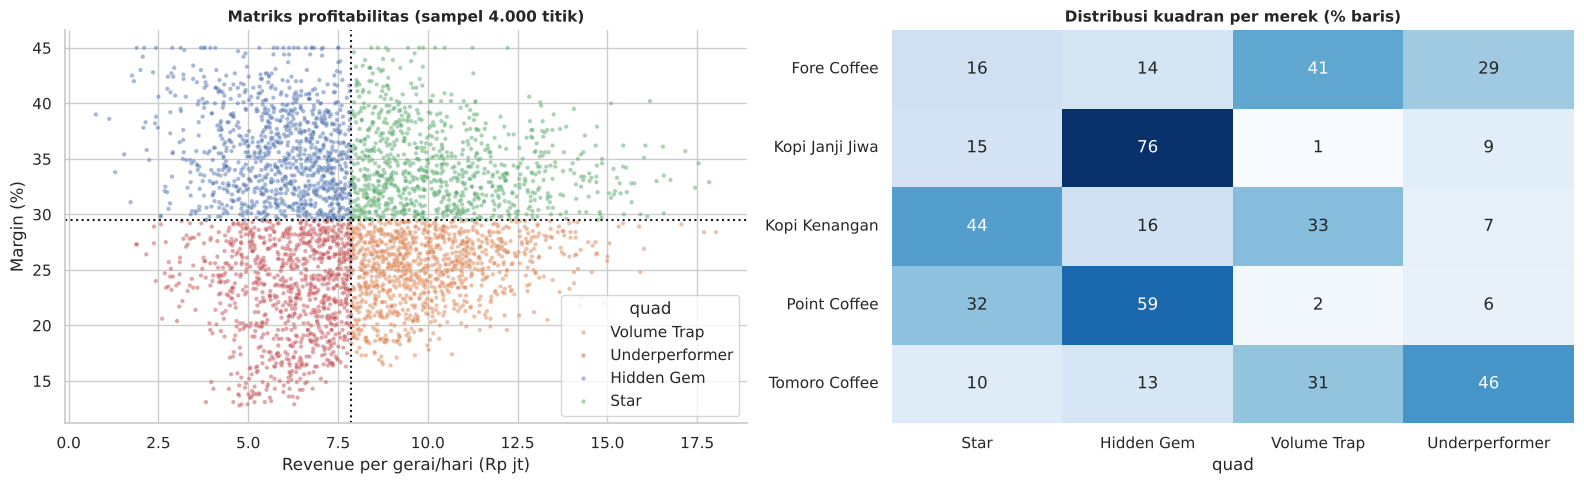

**Format & kota per kuadran (% baris)**

quad,Star,Hidden Gem,Volume Trap,Underperformer
fmt,,,,
Cloud Kitchen / Delivery Only,10.10,74.20,0.10,15.70
Drive-Thru Highway,19.40,50.00,2.30,28.40
Mall Kiosk,14.40,11.40,45.30,29.00
Office Tower Lobby,25.30,10.50,48.00,16.10
Standalone Shophouse / Ruko,35.20,27.70,12.40,24.70


**Volume Trap vs Star** - high revenue tetapi margin di bawah median: apa bedanya?

,Volume Trap,Star,selisih
cups,694.36,593.40,100.96
net_price,"15,633.57","18,123.12","-2,489.56"
disc,28.01,16.05,11.96
margin,24.95,34.07,-9.12
sens,5.42,4.49,0.94
canni,5.10,4.37,0.72
dens,5.65,5.08,0.56
rating,4.56,4.48,0.08


In [24]:
rm, mm = d.rev.median(), d.margin.median()
d['quad'] = np.select([(d.margin>=mm)&(d.rev>=rm), (d.margin>=mm)&(d.rev<rm), (d.margin<mm)&(d.rev>=rm)], ['Star','Hidden Gem','Volume Trap'], 'Underperformer')
qa = d.groupby('quad').agg(n=('cups','size'), n_share=('cups', lambda s: len(s)/len(d)*100), rev_share=('rev', lambda s: s.sum()/d.rev.sum()*100), profit_share=('profit', lambda s: s.sum()/d.profit.sum()*100),
        cups=('cups','mean'), net_price=('net_price','mean'), disc=('disc','mean'), margin=('margin','mean'), rev_m=('rev_m','mean'), sens=('sens','mean'), canni=('canni','mean'), dens=('dens','mean'),
        diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), atrisk_promo=('loyalty', lambda s: s.isin(LOY[2:]).mean()*100)).round(2)
display(qa.loc[['Star','Hidden Gem','Volume Trap','Underperformer']])
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
pal = {'Star':'#55A868','Hidden Gem':'#4C72B0','Volume Trap':'#DD8452','Underperformer':'#C44E52'}
sns.scatterplot(data=d.sample(4000, random_state=SEED), x='rev_m', y='margin', hue='quad', palette=pal, s=10, alpha=.5, ax=ax[0]); ax[0].axvline(rm/1e6, c='k', ls=':'); ax[0].axhline(mm, c='k', ls=':')
ax[0].set_title('Matriks profitabilitas (sampel 4.000 titik)'); ax[0].set_xlabel('Revenue per gerai/hari (Rp jt)'); ax[0].set_ylabel('Margin (%)')
qb = (pd.crosstab(d.brand, d.quad, normalize='index')*100)[['Star','Hidden Gem','Volume Trap','Underperformer']]; sns.heatmap(qb, annot=True, fmt='.0f', cmap='Blues', ax=ax[1], cbar=False); ax[1].set_title('Distribusi kuadran per merek (% baris)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()
md_('**Format & kota per kuadran (% baris)**'); display((pd.crosstab(d.fmt, d.quad, normalize='index')*100).round(1)[['Star','Hidden Gem','Volume Trap','Underperformer']])
vt = d[d.quad=='Volume Trap']; st = d[d.quad=='Star']
md_('**Volume Trap vs Star** - high revenue tetapi margin di bawah median: apa bedanya?')
display(pd.DataFrame({'Volume Trap': vt[['cups','net_price','disc','margin','sens','canni','dens','rating']].mean(), 'Star': st[['cups','net_price','disc','margin','sens','canni','dens','rating']].mean()}).assign(selisih=lambda x: x['Volume Trap']-x['Star']).round(2))

# 12. Cannibalization & Competitive Risk
**Pertanyaan:** di mana pasar bernilai tinggi tetapi eksposur kanibalisasi juga tinggi (penting untuk keputusan ekspansi)?

Spearman cannibalization vs:  {'rev': np.float64(0.07), 'margin': np.float64(-0.47), 'profit': np.float64(-0.19), 'dens': np.float64(0.79), 'disc': np.float64(0.41), 'sens': np.float64(0.26), 'cups': np.float64(0.31)}


**Cannibalization per brand**

,n,canni,dens,margin,rev_m,profit_m
brand,,,,,,
Tomoro Coffee,4011,5.02,5.07,25.09,7.44,1.89
Fore Coffee,2420,4.72,5.12,26.83,8.47,2.27
Kopi Kenangan,3510,4.59,5.20,30.77,9.85,3.03
Kopi Janji Jiwa,1350,4.39,5.07,35.87,5.90,2.11
Point Coffee,1709,4.30,5.18,36.07,7.04,2.53


**Cannibalization per fmt**

,n,canni,dens,margin,rev_m,profit_m
fmt,,,,,,
Mall Kiosk,3613,5.06,5.71,25.43,8.65,2.23
Office Tower Lobby,2553,4.91,5.83,27.47,9.69,2.69
Standalone Shophouse / Ruko,4501,4.87,4.56,31.47,7.89,2.51
Cloud Kitchen / Delivery Only,1501,3.65,4.49,35.31,5.43,1.94
Drive-Thru Highway,832,3.29,4.64,32.46,6.30,2.06


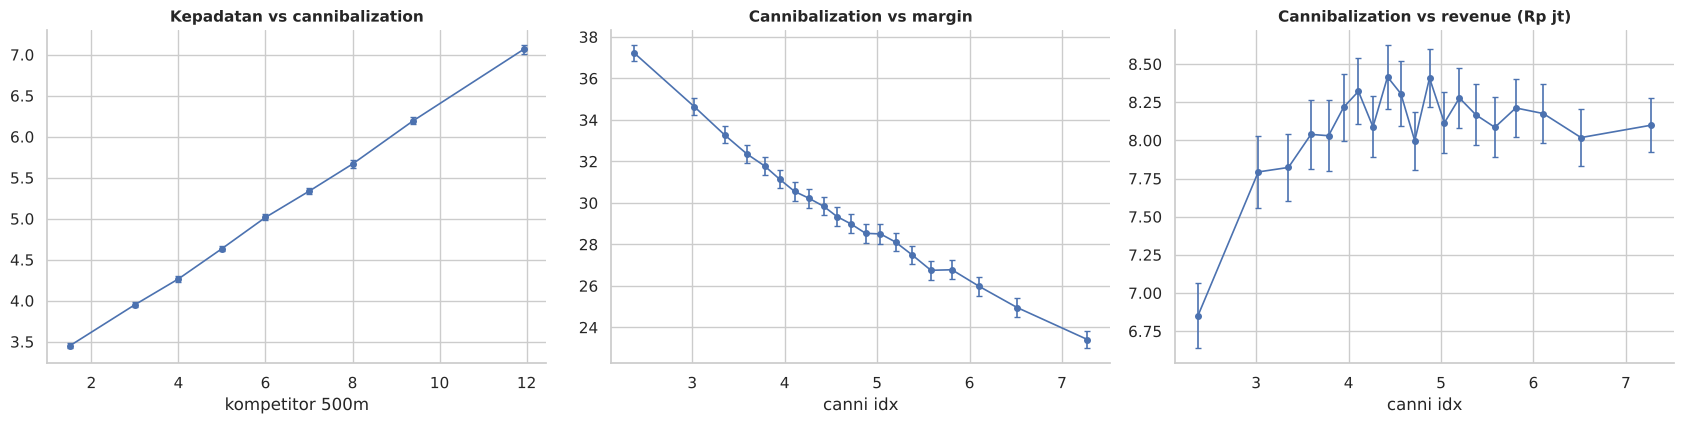

canni ~ dens + disc + merek + format + order: R2 = 1.0 | +1 kompetitor = 0.343 | +10pp diskon = 0.431


,n,rev_m,margin,canni,dens,profit_m,segment
city,,,,,,,
Semarang,535,8.24,29.65,4.28,3.99,2.43,High-value / High-cannibalization (RISIKO EKSPANSI)
Jakarta Pusat,1724,8.14,29.46,5.13,6.43,2.39,High-value / High-cannibalization (RISIKO EKSPANSI)
Jakarta Barat,1388,8.07,29.40,5.10,6.34,2.37,High-value / High-cannibalization (RISIKO EKSPANSI)
Bekasi,903,8.20,29.47,4.18,3.61,2.41,High-value / Low-cannibalization (PRIORITAS EKSPANSI)
Depok,564,8.18,29.91,4.12,3.51,2.44,High-value / Low-cannibalization (PRIORITAS EKSPANSI)
Yogyakarta,391,8.13,29.44,4.15,3.58,2.40,High-value / Low-cannibalization (PRIORITAS EKSPANSI)
Medan,689,8.01,29.36,4.25,3.90,2.34,Low-value / High-cannibalization (HINDARI)
Surabaya,1502,8.01,29.67,5.12,6.39,2.36,Low-value / High-cannibalization (HINDARI)
Jakarta Selatan,2254,7.96,29.34,5.14,6.42,2.33,Low-value / High-cannibalization (HINDARI)


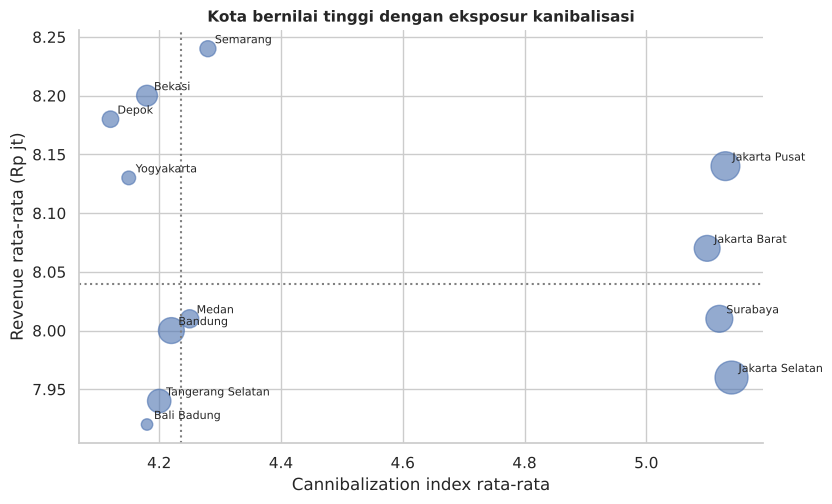

In [25]:
print('Spearman cannibalization vs: ', {y: round(sp('canni', y)[0], 2) for y in ['rev','margin','profit','dens','disc','sens','cups']})
for col in ['brand','fmt']: md_(f'**Cannibalization per {col}**'); display(prof(col)[['n','canni','dens','margin','rev_m','profit_m']].sort_values('canni', ascending=False))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
binned('dens','canni',14,ax[0]); ax[0].set_title('Kepadatan vs cannibalization'); ax[0].set_xlabel('kompetitor 500m')
binned('canni','margin',20,ax[1]); ax[1].set_title('Cannibalization vs margin'); ax[1].set_xlabel('canni idx')
binned('canni','rev_m',20,ax[2]); ax[2].set_title('Cannibalization vs revenue (Rp jt)'); ax[2].set_xlabel('canni idx')
plt.tight_layout(); plt.show()
mc = smf.ols('canni ~ dens + disc + C(brand) + C(fmt) + C(order)', d).fit(cov_type='HC3'); print('canni ~ dens + disc + merek + format + order: R2 =', round(mc.rsquared, 3), '| +1 kompetitor =', round(mc.params['dens'],3), '| +10pp diskon =', round(10*mc.params['disc'],3))

K2 = ca[~ca.small_n].copy(); mr, mc_ = K2.rev_m.median(), K2.canni.median()
K2['segment'] = np.select([(K2.rev_m>=mr)&(K2.canni>=mc_), (K2.rev_m>=mr)&(K2.canni<mc_), (K2.rev_m<mr)&(K2.canni>=mc_)], ['High-value / High-cannibalization (RISIKO EKSPANSI)','High-value / Low-cannibalization (PRIORITAS EKSPANSI)','Low-value / High-cannibalization (HINDARI)'], 'Low-value / Low-cannibalization (MONITOR)')
display(K2[['n','rev_m','margin','canni','dens','profit_m','segment']].sort_values(['segment','rev_m'], ascending=[True, False]))
fig, ax = plt.subplots(figsize=(8.5, 5.2)); ax.scatter(K2.canni, K2.rev_m, s=K2.n/4, alpha=.6)
for c, r in K2.iterrows(): ax.annotate(c, (r.canni, r.rev_m), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.axvline(mc_, ls=':', c='grey'); ax.axhline(mr, ls=':', c='grey'); ax.set_xlabel('Cannibalization index rata-rata'); ax.set_ylabel('Revenue rata-rata (Rp jt)'); ax.set_title('Kota bernilai tinggi dengan eksposur kanibalisasi')
plt.tight_layout(); plt.show()

# 13. Statistical Analysis
## 13.1 Korelasi
Spearman (utama; distribusi tidak normal/ordinal) dan Pearson (pembanding). Korelasi **bukan** kausalitas; pasangan turunan-mekanis otomatis berkorelasi tinggi dan harus dibaca demikian.

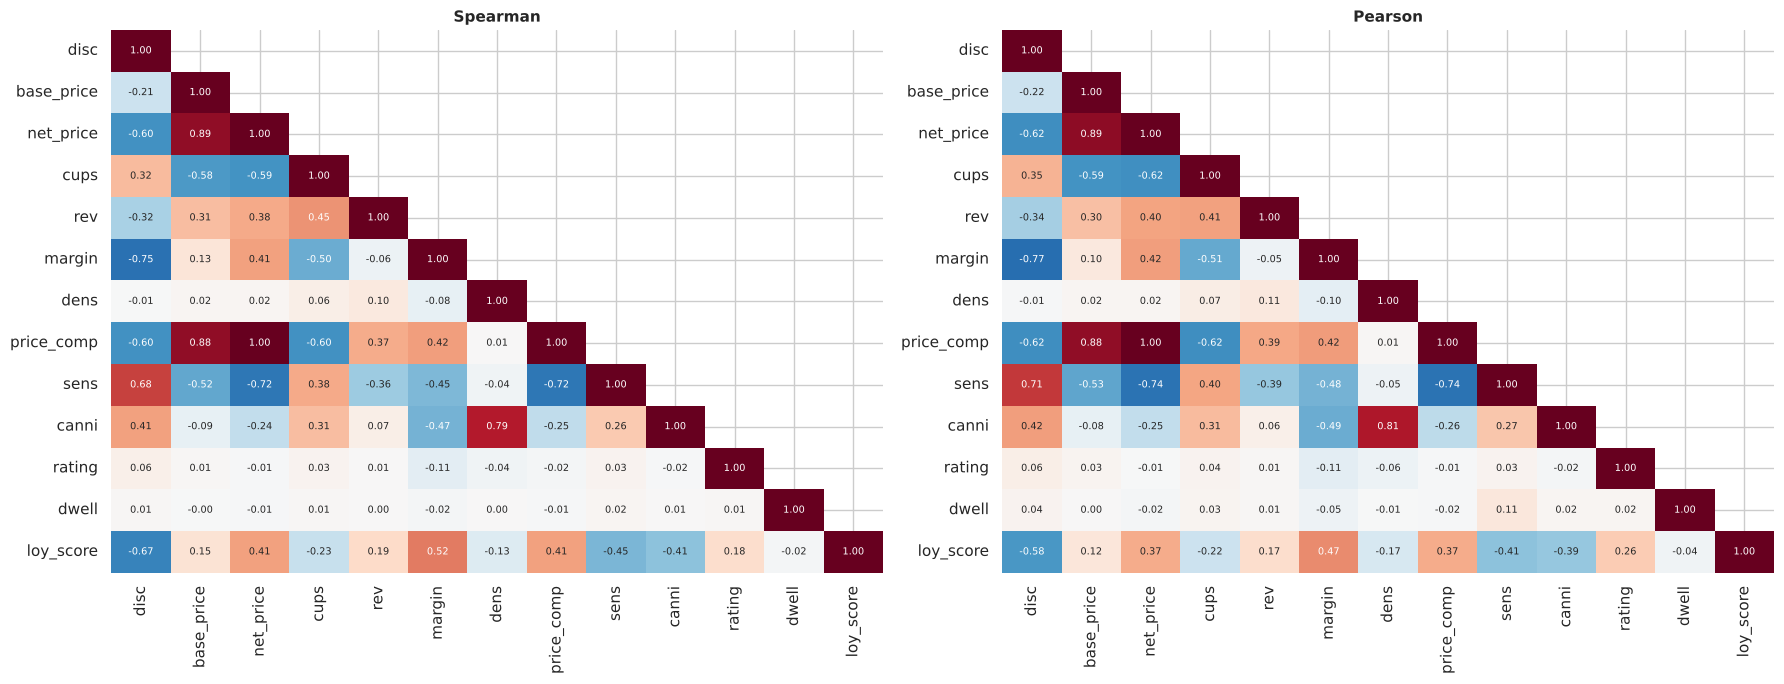

Selisih Spearman vs Pearson terbesar (indikasi non-linearitas/outlier):
dwell      sens     0.10
loy_score  disc     0.08
           rating   0.08
           margin   0.05
           sens     0.04
Dwell: korelasi dibaca hati-hati; variansi dwell hanya berasal dari Dine-In.


In [26]:
cn = ['disc','base_price','net_price','cups','rev','margin','dens','price_comp','sens','canni','rating','dwell','loy_score']
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, m in zip(ax, ['spearman','pearson']):
    c = d[cn].corr(method=m); sns.heatmap(c, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, mask=np.triu(np.ones_like(c, bool), 1), ax=a, cbar=False, annot_kws={'size': 7}); a.set_title(m.capitalize())
plt.tight_layout(); plt.show()
dif = (d[cn].corr('spearman') - d[cn].corr('pearson')).abs().where(np.tril(np.ones((len(cn),)*2, bool), -1)).stack().sort_values(ascending=False).head(5)
print('Selisih Spearman vs Pearson terbesar (indikasi non-linearitas/outlier):'); print(dif.round(2).to_string())
print('Dwell: korelasi dibaca hati-hati; variansi dwell hanya berasal dari Dine-In.')

## 13.2 Model 1 - Revenue drivers
**Target:** `log(daily_revenue_estimate_idr)`. Karena revenue = net_price x cups, memasukkan **cups** dan **net price** membuat model *mekanis* (R2 = 1). Maka:
- **Model 1A (utama):** tanpa cups, net price, price_comp, rev_per_comp, dwell_spend -> pendorong *struktural* revenue.
- **Model 1B (diagnostik):** menambah `log(cups)` hanya untuk menunjukkan bahwa R2 melonjak mekanis (bukan temuan).

Identitas log(rev) ~ log(net_price)+log(cups): R2 = 1.000000, koef = [1. 1.]  -> pendorong revenue = harga x volume (tautologi)


**VIF (10 tertinggi)** - multikolinearitas:

C(city)[T.Jakarta Selatan]         7.90
C(brand)[T.Tomoro Coffee]          7.70
C(city)[T.Jakarta Pusat]           6.60
C(city)[T.Surabaya]                6.00
C(city)[T.Jakarta Barat]           5.60
C(city)[T.Bandung]                 5.50
C(order)[T.Online Ojol Delivery]   4.80
C(city)[T.Tangerang Selatan]       4.80
C(order)[T.Mobile App Pickup]      4.60
np.log(base_price)                 4.40



Model 1A: R2 = 0.655, adj R2 = 0.654, n = 13,000 | Model 1B (+log cups, mekanis): R2 = 0.998
Breusch-Pagan p = 4.96e-193 -> SE robust HC3 dipakai


,coef,ci_low,ci_high,p,efek_%,efek_ci_low_%,efek_ci_high_%,efek_+1SD
C(brand)[T.Kopi Janji Jiwa],-0.29,-0.32,-0.26,0.00,-25.01,-27.18,-22.77,NaN
C(brand)[T.Kopi Kenangan],0.26,0.24,0.27,0.00,29.33,27.37,31.32,NaN
C(brand)[T.Point Coffee],-0.10,-0.13,-0.08,0.00,-9.75,-11.84,-7.62,NaN
C(brand)[T.Tomoro Coffee],0.38,0.36,0.40,0.00,45.97,43.12,48.87,NaN
C(fmt)[T.Drive-Thru Highway],0.16,0.13,0.18,0.00,17.07,14.24,19.97,NaN
C(fmt)[T.Mall Kiosk],0.49,0.47,0.50,0.00,62.61,59.76,65.51,NaN
C(fmt)[T.Office Tower Lobby],0.61,0.59,0.62,0.00,83.45,80.19,86.76,NaN
C(fmt)[T.Standalone Shophouse / Ruko],0.40,0.39,0.42,0.00,49.65,47.05,52.29,NaN
C(order)[T.Mobile App Pickup],-0.00,-0.02,0.02,0.87,-0.14,-1.83,1.57,NaN
C(order)[T.Online Ojol Delivery],-0.01,-0.03,0.01,0.48,-0.67,-2.49,1.19,NaN


,delta_R2 saat blok dikeluarkan
format,0.22
brand,0.15
diskon,0.14
base_price,0.04
city,0.00
kompetitor,0.00
segment,0.00
amenities,0.00
order,0.00
rating,0.00


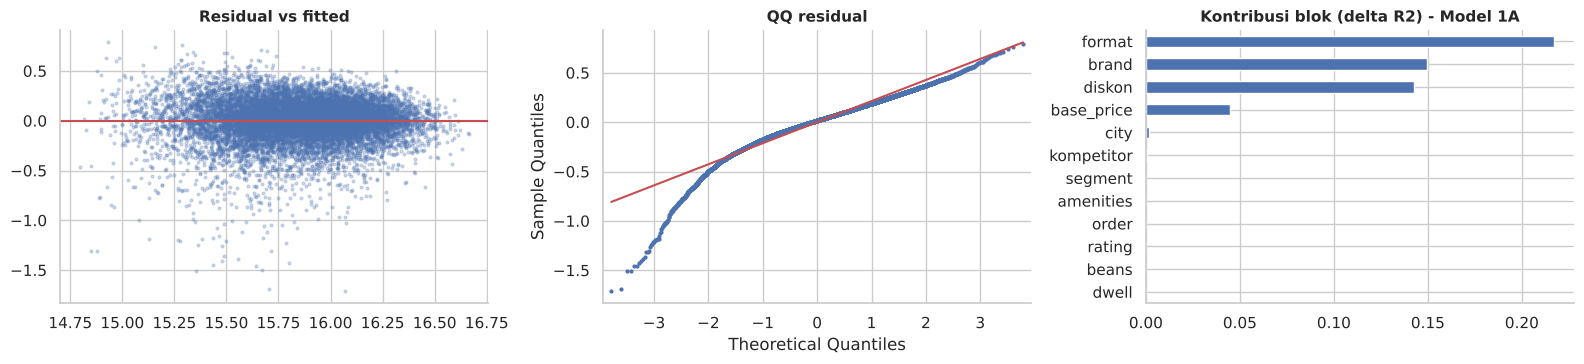

In [27]:
# Identitas mekanis
idm = smf.ols('np.log(rev) ~ np.log(net_price) + np.log(cups)', d).fit(); print(f'Identitas log(rev) ~ log(net_price)+log(cups): R2 = {idm.rsquared:.6f}, koef = {idm.params.values[1:].round(4)}  -> pendorong revenue = harga x volume (tautologi)')

f1 = 'np.log(rev) ~ np.log(base_price) + disc + dens + rating + np.log(dwell) + C(brand) + C(city) + C(fmt) + C(order) + C(seg) + C(beans) + C(amenities)'
y, X = dmatrices(f1, d, return_type='dataframe')
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:]).sort_values(ascending=False)
md_('**VIF (10 tertinggi)** - multikolinearitas:'); print(vif.head(10).round(1).to_string())
m1 = smf.ols(f1, d).fit(cov_type='HC3'); m1_ols = smf.ols(f1, d).fit()
m1b = smf.ols(f1 + ' + np.log(cups)', d).fit()
print(f'\nModel 1A: R2 = {m1.rsquared:.3f}, adj R2 = {m1.rsquared_adj:.3f}, n = {int(m1.nobs):,} | Model 1B (+log cups, mekanis): R2 = {m1b.rsquared:.3f}')
bp = het_breuschpagan(m1_ols.resid, m1_ols.model.exog); print(f'Breusch-Pagan p = {bp[1]:.3g} -> SE robust HC3 dipakai')

def tidy(m, drop='C(city)', pct=True, sds=None):
    ci = m.conf_int(); t = pd.DataFrame({'coef': m.params, 'ci_low': ci[0], 'ci_high': ci[1], 'p': m.pvalues})
    t = t[~t.index.str.contains(re.escape(drop)) & (t.index != 'Intercept')]
    if pct: t['efek_%'] = (np.exp(t.coef)-1)*100; t['efek_ci_low_%'] = (np.exp(t.ci_low)-1)*100; t['efek_ci_high_%'] = (np.exp(t.ci_high)-1)*100
    if sds:
        t['efek_+1SD'] = [t.coef[i]*sds[i] if i in sds else np.nan for i in t.index]
    return t
sd1 = {'disc': d.disc.std(), 'dens': d.dens.std(), 'rating': d.rating.std(), 'np.log(base_price)': np.log(d.base_price).std(), 'np.log(dwell)': np.log(d.dwell).std()}
t1 = tidy(m1, sds=sd1); display(t1.round(4))

def block_r2(f, blocks, full):
    out = {}
    for nm, term in blocks.items():
        f_ = f.replace(' + ' + term, '').replace(term + ' + ', ''); out[nm] = full.rsquared - smf.ols(f_, d).fit().rsquared
    return pd.Series(out, name='delta_R2 saat blok dikeluarkan').sort_values(ascending=False)
blocks1 = {'brand':'C(brand)','city':'C(city)','format':'C(fmt)','order':'C(order)','segment':'C(seg)','beans':'C(beans)','amenities':'C(amenities)','base_price':'np.log(base_price)','diskon':'disc','kompetitor':'dens','rating':'rating','dwell':'np.log(dwell)'}
b1 = block_r2(f1, blocks1, m1_ols); display(b1.round(4).to_frame())
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); ax[0].scatter(m1_ols.fittedvalues, m1_ols.resid, s=4, alpha=.25); ax[0].axhline(0, c='r'); ax[0].set_title('Residual vs fitted'); sm.qqplot(m1_ols.resid, line='s', ax=ax[1], markersize=2); ax[1].set_title('QQ residual')
b1.plot(kind='barh', ax=ax[2]).invert_yaxis(); ax[2].set_title('Kontribusi blok (delta R2) - Model 1A'); plt.tight_layout(); plt.show()

## 13.3 Model 2 - Margin drivers
**Target:** `outlet_operating_margin_estimate_pct`. **Spesifikasi A (utama):** `disc + log(base_price)` (net price adalah fungsi keduanya sehingga tidak dimasukkan bersamaan). **B:** memakai `net_price` + `disc` untuk menunjukkan masalah kolinearitas. **C:** tanpa `sens` & `loyalty` (kemungkinan *mediator*/hasil dari diskon) untuk uji stabilitas koefisien diskon.
Efek dilaporkan dalam **poin persentase margin**, dengan CI 95% robust (HC3) dan ukuran efek praktis, bukan hanya p-value.

VIF tertinggi spesifikasi A: {'sens': 172.6, 'C(seg)[T.Office Corporate Workers]': 75.6, 'disc': 68.2, 'np.log(base_price)': 26.3}


VIF tertinggi spesifikasi B (net price): {'sens': 145.2, 'C(seg)[T.Office Corporate Workers]': 63.8, 'np.log(net_price)': 35.8, 'disc': 30.1}

Model 2A: R2=0.999, adjR2=0.999 | 2B R2=0.999 | 2C R2=0.999


,coef,ci_low,ci_high,p,efek_+1SD
C(loyalty)[T.Value-Conscious-Regular],0.03,0.01,0.04,0.00,NaN
C(loyalty)[T.Promo-Chaser-Opportunist],-0.01,-0.03,0.01,0.35,NaN
C(loyalty)[T.At-Risk-Churn-Switcher],0.03,0.02,0.05,0.00,NaN
C(brand)[T.Kopi Janji Jiwa],0.02,-0.00,0.04,0.12,NaN
C(brand)[T.Kopi Kenangan],0.00,-0.01,0.01,0.72,NaN
C(brand)[T.Point Coffee],-0.00,-0.02,0.01,0.85,NaN
C(brand)[T.Tomoro Coffee],-0.02,-0.04,-0.00,0.03,NaN
C(fmt)[T.Drive-Thru Highway],-2.94,-2.96,-2.91,0.00,NaN
C(fmt)[T.Mall Kiosk],-9.92,-9.94,-9.90,0.00,NaN
C(fmt)[T.Office Tower Lobby],-7.92,-7.95,-7.90,0.00,NaN


,koef diskon (pp margin/pp diskon),ci_low,ci_high
A (utama),-0.35,-0.35,-0.35
B (net price),-0.35,-0.35,-0.35
C (tanpa sens/loyalty),-0.35,-0.35,-0.35


Interpretasi bisnis (2A): +10 pp diskon berasosiasi dengan margin -3.49 pp (CI95 -3.51..-3.47), ceteris paribus.


,delta_R2 saat blok dikeluarkan
format,0.23
beans,0.06
diskon,0.01
loyalitas,0.00
merek,0.00
segmen,0.00
order,0.00
sensitivitas,0.00
amenities,0.00
base_price,0.00


CV R2 (5-fold): OLS = 0.999 +/- 0.000 | Gradient boosting = 1.000 +/- 0.000


,permutation importance (drop R2)
disc,0.74
fmt,0.49
beans,0.33
loyalty,0.00
brand,0.00
sens,0.00
city,0.00
base_price,0.00
dens,0.00
seg,0.00


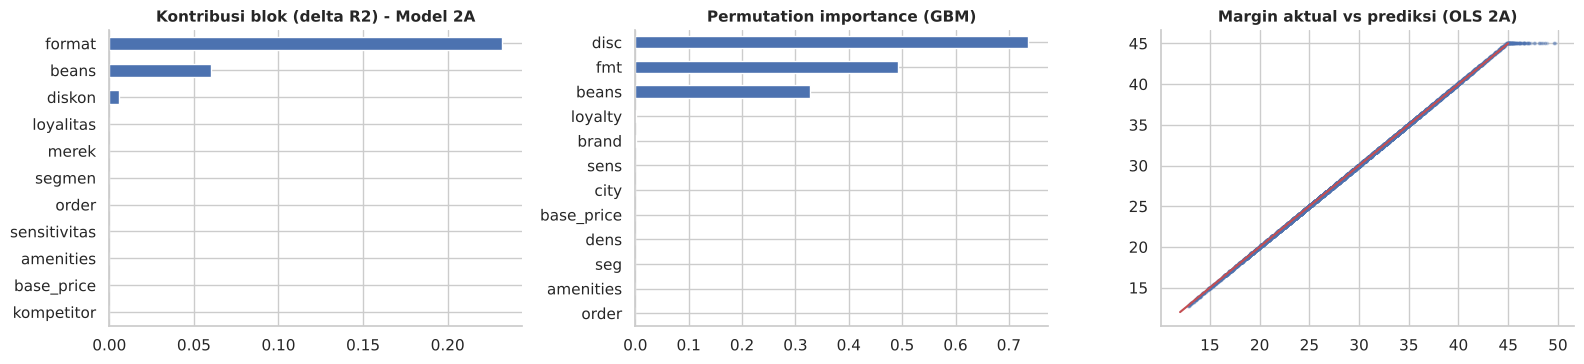

In [28]:
f2A = 'margin ~ disc + np.log(base_price) + dens + sens + C(loyalty) + C(brand) + C(fmt) + C(order) + C(seg) + C(beans) + C(amenities)'
f2B = 'margin ~ disc + np.log(net_price) + dens + sens + C(loyalty) + C(brand) + C(fmt) + C(order) + C(seg) + C(beans) + C(amenities)'
f2C = 'margin ~ disc + np.log(base_price) + dens + C(brand) + C(fmt) + C(order) + C(seg) + C(beans) + C(amenities)'
mA, mB, mC = [smf.ols(f, d).fit(cov_type='HC3') for f in (f2A, f2B, f2C)]; mA_ols = smf.ols(f2A, d).fit()
for nm, f in [('A', f2A), ('B (net price)', f2B)]:
    y, X = dmatrices(f, d, return_type='dataframe'); v = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:]).sort_values(ascending=False)
    print(f'VIF tertinggi spesifikasi {nm}:', v.head(4).round(1).to_dict())
print(f'\nModel 2A: R2={mA.rsquared:.3f}, adjR2={mA.rsquared_adj:.3f} | 2B R2={mB.rsquared:.3f} | 2C R2={mC.rsquared:.3f}')
sd2 = {'disc': d.disc.std(), 'dens': d.dens.std(), 'sens': d.sens.std(), 'np.log(base_price)': np.log(d.base_price).std()}
t2 = tidy(mA, drop='__none__', pct=False, sds=sd2); t2 = t2[~t2.index.str.contains('C.city.')]; display(t2.round(4))
cmp_ = pd.DataFrame({'A (utama)': [mA.params['disc'], *mA.conf_int().loc['disc']], 'B (net price)': [mB.params['disc'], *mB.conf_int().loc['disc']], 'C (tanpa sens/loyalty)': [mC.params['disc'], *mC.conf_int().loc['disc']]}, index=['koef diskon (pp margin/pp diskon)', 'ci_low', 'ci_high']).T
display(cmp_.round(4))
print(f'Interpretasi bisnis (2A): +10 pp diskon berasosiasi dengan margin {10*mA.params["disc"]:+.2f} pp (CI95 {10*mA.conf_int().loc["disc"][0]:+.2f}..{10*mA.conf_int().loc["disc"][1]:+.2f}), ceteris paribus.')

blocks2 = {'diskon':'disc','base_price':'np.log(base_price)','kompetitor':'dens','sensitivitas':'sens','loyalitas':'C(loyalty)','merek':'C(brand)','format':'C(fmt)','order':'C(order)','segmen':'C(seg)','beans':'C(beans)','amenities':'C(amenities)'}
b2 = block_r2(f2A, blocks2, mA_ols); display(b2.round(4).to_frame())

# Model non-linear sebagai pembanding & permutation importance
Xc = d[['disc','base_price','dens','sens','loyalty','brand','fmt','order','seg','beans','amenities','city']].copy()
for c in ['loyalty','brand','fmt','order','seg','beans','amenities','city']: Xc[c] = Xc[c].astype('category')
gbm = HistGradientBoostingRegressor(max_depth=4, learning_rate=.08, max_iter=250, categorical_features='from_dtype', random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
cv_gbm = cross_val_score(gbm, Xc, d.margin, cv=kf, scoring='r2'); Xl = pd.get_dummies(Xc.drop(columns='city').assign(lb=np.log(d.base_price)).drop(columns='base_price'), drop_first=True).astype(float)
cv_ols = cross_val_score(__import__('sklearn.linear_model', fromlist=['LinearRegression']).LinearRegression(), Xl, d.margin, cv=kf, scoring='r2')
print(f'CV R2 (5-fold): OLS = {cv_ols.mean():.3f} +/- {cv_ols.std():.3f} | Gradient boosting = {cv_gbm.mean():.3f} +/- {cv_gbm.std():.3f}')
Xtr, Xte, ytr, yte = train_test_split(Xc, d.margin, test_size=.25, random_state=SEED); gbm.fit(Xtr, ytr)
pi = permutation_importance(gbm, Xte, yte, n_repeats=5, random_state=SEED, scoring='r2'); pim = pd.Series(pi.importances_mean, index=Xc.columns).sort_values(ascending=False)
display(pim.round(4).to_frame('permutation importance (drop R2)'))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)); b2.plot(kind='barh', ax=ax[0]).invert_yaxis(); ax[0].set_title('Kontribusi blok (delta R2) - Model 2A')
pim.plot(kind='barh', ax=ax[1]).invert_yaxis(); ax[1].set_title('Permutation importance (GBM)')
ax[2].scatter(mA_ols.fittedvalues, d.margin, s=3, alpha=.2); ax[2].plot([12,45],[12,45],'r'); ax[2].set_title('Margin aktual vs prediksi (OLS 2A)'); plt.tight_layout(); plt.show()

### 13.3b Model margin ringkas & atribusi perbedaan margin antar-merek
Blok-blok pada Model 2A menunjukkan tiga faktor yang menyerap hampir seluruh variasi: **diskon, format gerai, dan jenis biji**. Kita uji model ringkas dan lihat apakah variabel lain menambah sesuatu.

Model ringkas (diskon + format + biji): R2 = 0.9994, simpangan residual = 0.16 pp | Model penuh (+merek, loyalitas, kompetitor, sens, segmen, order, harga, fasilitas, kota, rating): R2 = 0.9994
Tambahan R2 dari seluruh variabel lain = 0.0000 -> variabel lain hampir tidak memberi informasi tambahan tentang margin


,koef (pp margin),ci_low,ci_high,p
Intercept,41.90,41.87,41.93,0.00
C(fmt)[T.Drive-Thru Highway],-2.94,-2.96,-2.92,0.00
C(fmt)[T.Mall Kiosk],-9.92,-9.95,-9.90,0.00
C(fmt)[T.Office Tower Lobby],-7.92,-7.95,-7.90,0.00
C(fmt)[T.Standalone Shophouse / Ruko],-3.92,-3.95,-3.90,0.00
C(beans)[T.House Blend 70-30],4.01,4.00,4.01,0.00
C(beans)[T.Robusta Blend Commercial],7.92,7.90,7.94,0.00
disc,-0.35,-0.35,-0.35,0.00


,efek_diskon_pp,efek_format_pp,efek_biji_pp,total_dijelaskan,selisih_margin_aktual
brand,,,,,
Fore Coffee,-0.29,0.05,-2.43,-2.68,-2.68
Kopi Janji Jiwa,2.42,-0.10,4.04,6.35,6.36
Kopi Kenangan,0.92,-0.04,0.37,1.26,1.26
Point Coffee,3.31,0.10,3.15,6.56,6.56
Tomoro Coffee,-2.86,-0.00,-1.56,-4.41,-4.42


**Bauran biji per merek (% baris) dan margin/harga/rating per jenis biji**

beans,100% Arabica Specialty,House Blend 70-30,Robusta Blend Commercial
brand,,,
Fore Coffee,100.00,0.00,0.00
Kopi Janji Jiwa,0.00,37.00,63.00
Kopi Kenangan,30.00,70.00,0.00
Point Coffee,0.00,59.70,40.30
Tomoro Coffee,78.10,21.90,0.00


,n,margin,base_price,net_price,cups,rating,profit_m
beans,,,,,,,
100% Arabica Specialty,6605,25.79,"20,671.16","14,842.56",621.54,4.60,2.14
House Blend 70-30,4856,31.96,"19,849.67","15,355.93",569.18,4.44,2.68
Robusta Blend Commercial,1539,37.77,"19,499.68","15,989.84",401.89,4.42,2.41


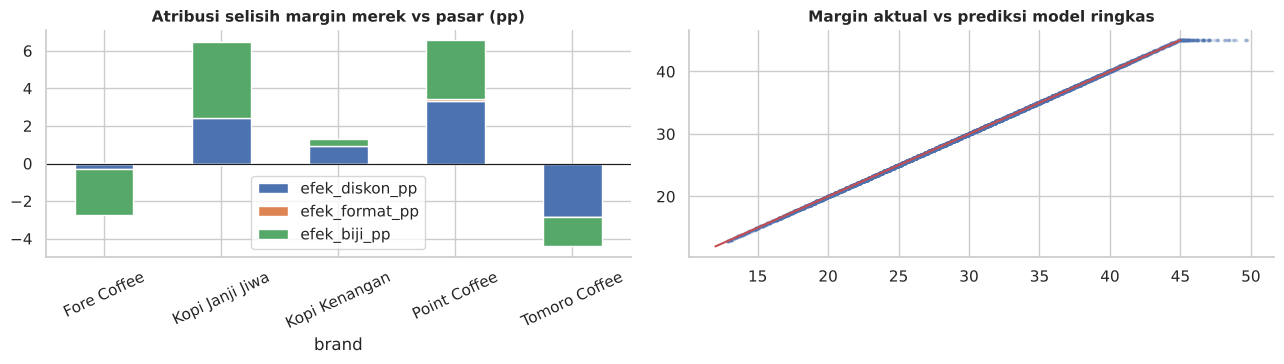

CATATAN: R2 hampir 1 + residual ~1 pp (residual < 0,2 pp) menandakan margin dihasilkan oleh formula (diskon, format, biji) + derau sangat kecil. Ini adalah ciri data sintetis/model, bukan perilaku pasar yang diobservasi.


In [29]:
mp = smf.ols('margin ~ disc + C(fmt) + C(beans)', d).fit(cov_type='HC3'); mp_ols = smf.ols('margin ~ disc + C(fmt) + C(beans)', d).fit()
mfull = smf.ols('margin ~ disc + C(fmt) + C(beans) + C(brand) + C(loyalty) + dens + sens + C(seg) + C(order) + np.log(base_price) + C(amenities) + C(city) + rating', d).fit()
print(f'Model ringkas (diskon + format + biji): R2 = {mp_ols.rsquared:.4f}, simpangan residual = {np.sqrt(mp_ols.scale):.2f} pp | Model penuh (+merek, loyalitas, kompetitor, sens, segmen, order, harga, fasilitas, kota, rating): R2 = {mfull.rsquared:.4f}')
print(f'Tambahan R2 dari seluruh variabel lain = {mfull.rsquared-mp_ols.rsquared:.4f} -> variabel lain hampir tidak memberi informasi tambahan tentang margin')
ci = mp.conf_int(); display(pd.DataFrame({'koef (pp margin)': mp.params, 'ci_low': ci[0], 'ci_high': ci[1], 'p': mp.pvalues}).round(3))

# atribusi margin merek (relatif rata-rata pasar) = diskon + format + biji
fe = mp.params.filter(like='C(fmt)'); be = mp.params.filter(like='C(beans)')
fmt_eff = d.fmt.map(lambda x: fe.get(f'C(fmt)[T.{x}]', 0.0)); bean_eff = d.beans.map(lambda x: be.get(f'C(beans)[T.{x}]', 0.0))
att = pd.DataFrame({'efek_diskon_pp': mp.params['disc']*(d.groupby('brand').disc.mean() - d.disc.mean()), 'efek_format_pp': fmt_eff.groupby(d.brand).mean() - fmt_eff.mean(), 'efek_biji_pp': bean_eff.groupby(d.brand).mean() - bean_eff.mean()})
att['total_dijelaskan'] = att.sum(axis=1); att['selisih_margin_aktual'] = d.groupby('brand').margin.mean() - d.margin.mean(); display(att.round(2))
md_('**Bauran biji per merek (% baris) dan margin/harga/rating per jenis biji**')
display((pd.crosstab(d.brand, d.beans, normalize='index')*100).round(1)); display(d.groupby('beans').agg(n=('cups','size'), margin=('margin','mean'), base_price=('base_price','mean'), net_price=('net_price','mean'), cups=('cups','mean'), rating=('rating','mean'), profit_m=('profit_m','mean')).round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); att[['efek_diskon_pp','efek_format_pp','efek_biji_pp']].plot(kind='bar', stacked=True, ax=ax[0]); ax[0].axhline(0, c='k', lw=.8); ax[0].set_title('Atribusi selisih margin merek vs pasar (pp)'); ax[0].tick_params(axis='x', rotation=25)
ax[1].scatter(mp_ols.fittedvalues, d.margin, s=3, alpha=.2); ax[1].plot([12,45],[12,45],'r'); ax[1].set_title('Margin aktual vs prediksi model ringkas'); plt.tight_layout(); plt.show()
print('CATATAN: R2 hampir 1 + residual ~1 pp (residual < 0,2 pp) menandakan margin dihasilkan oleh formula (diskon, format, biji) + derau sangat kecil. Ini adalah ciri data sintetis/model, bukan perilaku pasar yang diobservasi.')

## 13.4 Sensitivity & Robustness
Setiap temuan utama diuji terhadap spesifikasi alternatif. Hasil dirangkum dalam **robustness ledger** di akhir Bagian 14.

In [30]:
ROB = []  # (klaim, uji, hasil, verdict)
def verdict(ok, note): return 'ROBUST' if ok else 'RAPUH'

# 1. Mean vs median per merek
mm_ = d.groupby('brand').agg(margin_mean=('margin','mean'), margin_med=('margin','median'), rev_mean=('rev','mean'), rev_med=('rev','median'), cups_mean=('cups','mean'), cups_med=('cups','median'))
display(mm_.round(1))
rk = {m: stats.spearmanr(mm_[m+'_mean'], mm_[m+'_med'])[0] for m in ['margin','rev','cups']}
ROB.append(('Peringkat merek stabil mean vs median', 'Spearman peringkat mean vs median (margin/rev/cups)', str({k: round(v,2) for k,v in rk.items()}), verdict(all(v>0.89 for v in rk.values()), '')))

# 2. Skema band diskon alternatif
schemes = {'tetap 5 band': 'disc_band', 'kuintil': 'disc_band_q', '10pp': pd.cut(d.disc, np.arange(0, 70, 10), include_lowest=True), '5pp': 'disc5'}
rows = []
for nm, s in schemes.items():
    g = d.groupby(d[s] if isinstance(s, str) else s, observed=True).agg(margin=('margin','mean'), cups=('cups','mean'), rev=('rev_m','mean'), profit=('profit_m','mean'))
    ix = np.arange(len(g)); rows.append((nm, len(g), stats.spearmanr(ix, g.margin)[0], stats.spearmanr(ix, g.cups)[0], stats.spearmanr(ix, g.rev)[0], g.profit.idxmax()))
sc_ = pd.DataFrame(rows, columns=['skema','n_band','rho_margin','rho_cups','rho_rev','band_profit_tertinggi']); display(sc_.round(2))
ROB.append(('Diskon naik -> margin turun, cups naik', 'Monotonisitas lintas 4 skema band', f'rho_margin={sc_.rho_margin.round(2).tolist()}, rho_cups={sc_.rho_cups.round(2).tolist()}', verdict((sc_.rho_margin<-0.9).all() and (sc_.rho_cups>0.8).all(), '')))
ROB.append(('Diskon naik -> revenue tidak naik monoton (puncak di diskon rendah-menengah)', 'rho revenue vs band lintas skema', str(sc_.rho_rev.round(2).tolist()), verdict((sc_.rho_rev<0).all(), '')))

# 3. Outlier sensitivity
d2 = d[~((d.dwell > 60) | (d.rev > d.rev.quantile(.99)) | (d.rev < d.rev.quantile(.01)) | (d.disc > d.disc.quantile(.99)))]
rho_full, rho_trim = sp('disc','margin')[0], sp('disc','margin', d2)[0]
b_full, b_trim = mA.params['disc'], smf.ols(f2A, d2).fit().params['disc']
print(f'Tanpa outlier ({len(d)-len(d2):,} baris, {1-len(d2)/len(d):.1%}): Spearman disc-margin {rho_full:.3f} -> {rho_trim:.3f}; koef diskon Model 2A {b_full:.4f} -> {b_trim:.4f}')
ROB.append(('Efek diskon thd margin tidak digerakkan outlier', 'Trim dwell>60, rev P1/P99, disc>P99', f'koef {b_full:.3f} -> {b_trim:.3f}', verdict(abs(b_trim/b_full-1) < 0.15, '')))

# 4. Subgroup consistency
def sub(col): return d.groupby(col, observed=True).apply(lambda g: pd.Series({'n': len(g), 'rho_disc_margin': stats.spearmanr(g.disc, g.margin)[0], 'rho_disc_cups': stats.spearmanr(g.disc, g.cups)[0], 'rho_disc_rev': stats.spearmanr(g.disc, g.rev)[0]}))
sg = pd.concat([sub('brand'), sub('fmt'), sub('order'), sub('city').query('n>=100')]); display(sg.round(2))
ROB.append(('Diskon-margin negatif di semua subgrup', 'Brand/format/order/kota (n>=100)', f'rho maks = {sg.rho_disc_margin.max():.2f}', verdict((sg.rho_disc_margin < -0.3).all(), '')))
bmax = sub('brand').rho_disc_cups.max(); ROB.append(('Diskon menaikkan volume DI DALAM merek', 'Spearman diskon-cups per merek (maks)', f'maks={bmax:.2f} (agregat={sp("disc","cups")[0]:.2f}; di dalam format/order +0.3 karena campuran merek)', 'TIDAK TERDUKUNG' if bmax < 0.1 else 'ROBUST'))
rev_neg = (sg.rho_disc_rev < 0).mean(); ROB.append(('Diskon-revenue negatif di semua subgrup', 'Proporsi subgrup rho<0', f'{rev_neg:.0%} ({sg.rho_disc_rev.min():.2f}..{sg.rho_disc_rev.max():.2f})', verdict(rev_neg == 1, '')))


ROB.append(('Peringkat atraktivitas kota bermakna', 'Eta-kuadrat kota pada profit proxy', f'{eta.loc["city","profit_proxy"]*100:.2f}% (format {eta.loc["fmt","profit_proxy"]*100:.1f}%)', verdict(eta.loc['city','profit_proxy'] > 0.02, '')))
ROB.append(('Margin ditentukan terutama diskon+format+biji', 'R2 model ringkas vs penuh', f'{mp_ols.rsquared:.4f} vs {mfull.rsquared:.4f}', verdict(mfull.rsquared - mp_ols.rsquared < 0.01, '')))

# 5. Spesifikasi model & ambang kuadran
ROB.append(('Koefisien diskon stabil lintas spesifikasi 2A/B/C', 'Rentang koefisien', f'A={mA.params["disc"]:.3f}, B={mB.params["disc"]:.3f}, C={mC.params["disc"]:.3f}', verdict(max(abs(x/mA.params["disc"]-1) for x in (mB.params['disc'], mC.params['disc'])) < 0.25, '')))
ROB.append(('OLS cukup menjelaskan margin (non-linearitas kecil)', 'CV R2 OLS vs GBM', f'{cv_ols.mean():.3f} vs {cv_gbm.mean():.3f}', verdict(cv_gbm.mean() - cv_ols.mean() < 0.03, '')))
vt_share = {}
for nm, (a, b) in {'median': (d.rev.median(), d.margin.median()), 'mean': (d.rev.mean(), d.margin.mean()), 'P60/P40': (d.rev.quantile(.6), d.margin.quantile(.6))}.items():
    q_ = (d.margin < b) & (d.rev >= a); vt_share[nm] = d[q_].groupby('brand').size().div(d.groupby('brand').size()).idxmax()
print('Merek dengan porsi Volume Trap terbesar menurut ambang:', vt_share)
ROB.append(('Merek dengan porsi Volume Trap tertinggi stabil', 'Ambang median/mean/P60', str(vt_share), verdict(len(set(vt_share.values())) == 1, '')))

,margin_mean,margin_med,rev_mean,rev_med,cups_mean,cups_med
brand,,,,,,
Fore Coffee,26.80,26.90,"8,466,536.00","8,376,561.00",409.10,413.00
Kopi Janji Jiwa,35.90,35.80,"5,904,100.70","5,934,740.00",369.70,373.00
Kopi Kenangan,30.80,30.70,"9,853,852.30","9,806,154.00",583.00,593.00
Point Coffee,36.10,36.00,"7,037,778.10","7,003,080.00",439.40,444.00
Tomoro Coffee,25.10,25.00,"7,440,608.90","7,333,200.00",798.20,808.00


,skema,n_band,rho_margin,rho_cups,rho_rev,band_profit_tertinggi
0,tetap 5 band,5,-1.00,1.00,-0.90,0-10
1,kuintil,5,-1.00,0.90,-1.00,"(-0.001, 15.2]"
2,10pp,6,-1.00,1.00,-0.94,"(-0.001, 10.0]"
3,5pp,12,-1.00,0.96,-0.85,5-10


Tanpa outlier (1,339 baris, 10.3%): Spearman disc-margin -0.749 -> -0.750; koef diskon Model 2A -0.3491 -> -0.3491


,n,rho_disc_margin,rho_disc_cups,rho_disc_rev
Fore Coffee,"2,420.00",-0.70,0.03,-0.40
Kopi Janji Jiwa,"1,350.00",-0.60,-0.02,-0.34
Kopi Kenangan,"3,510.00",-0.65,-0.01,-0.45
Point Coffee,"1,709.00",-0.60,0.03,-0.29
Tomoro Coffee,"4,011.00",-0.71,0.05,-0.61
Cloud Kitchen / Delivery Only,"1,501.00",-0.87,0.29,-0.31
Drive-Thru Highway,832.00,-0.88,0.31,-0.36
Mall Kiosk,"3,613.00",-0.88,0.37,-0.38
Office Tower Lobby,"2,553.00",-0.88,0.35,-0.40
Standalone Shophouse / Ruko,"4,501.00",-0.88,0.37,-0.37


Merek dengan porsi Volume Trap terbesar menurut ambang: {'median': 'Fore Coffee', 'mean': 'Fore Coffee', 'P60/P40': 'Fore Coffee'}


# 14. Segmentation / Archetype Analysis
Proses: **Feature selection -> Scaling -> Penentuan jumlah klaster -> Fit -> Validasi -> Profiling -> Interpretasi bisnis.**  
Fitur: `net_price` (log), `disc`, `cups` (log), `margin`, `dens`, `sens`, `canni`, `loy_score`. Tidak dipakai: `rev` (turunan), `dwell` (artefak Dine-In), `price_comp` (redundan dengan net price), `conf`, narasi. Nama klaster diberikan **setelah** profil diperiksa.

,inertia,silhouette,calinski_harabasz
k,,,
2,"70,703.88",0.27,"6,121.08"
3,"59,282.87",0.23,"4,901.83"
4,"51,481.66",0.21,"4,419.24"
5,"47,725.23",0.19,"3,830.75"
6,"44,359.24",0.19,"3,494.10"
7,"40,996.85",0.20,"3,327.90"
8,"38,600.16",0.19,"3,144.60"


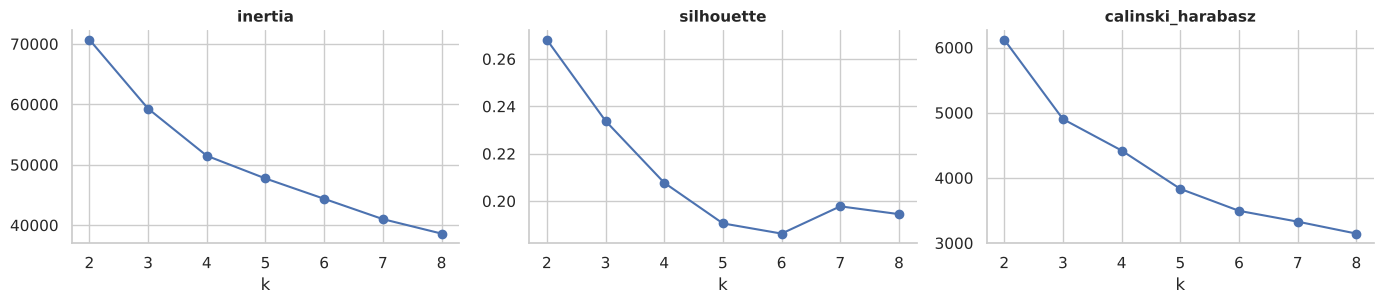

In [31]:
FEATS = ['net_price_log','disc','cups_log','margin','dens','sens','canni','loy_score']
Z = pd.DataFrame({'net_price_log': np.log(d.net_price), 'disc': d.disc, 'cups_log': np.log(d.cups), 'margin': d.margin, 'dens': d.dens, 'sens': d.sens, 'canni': d.canni, 'loy_score': d.loy_score})
Xs = StandardScaler().fit_transform(Z); sub_ix = rng.choice(len(d), 4000, replace=False)
ks = range(2, 9); ev = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xs); ev.append((k, km.inertia_, silhouette_score(Xs[sub_ix], km.labels_[sub_ix]), calinski_harabasz_score(Xs, km.labels_)))
ev = pd.DataFrame(ev, columns=['k','inertia','silhouette','calinski_harabasz']).set_index('k'); display(ev.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2)); [ev[c].plot(marker='o', ax=a, title=c) for a, c in zip(ax, ev.columns)]; plt.tight_layout(); plt.show()

k terpilih = 3


Silhouette = 0.234 | ARI antar-seed = 0.996 | ARI split-half (prediksi) = 0.950 | ARI vs Ward (4.000 sampel) = 0.353
ARI vs k alternatif: {3: 1.0, 4: 0.483}


,n,share,cups,net_price,disc,margin,rev_m,profit_m,dens,sens,canni,diehard,atrisk_promo,rating
cluster,,,,,,,,,,,,,,
0,3635,27.96,772.44,"9,680.45",37.88,23.57,7.19,1.70,4.46,7.28,5.04,0.00,83.11,4.56
1,3619,27.84,545.57,"16,362.68",26.43,28.27,8.65,2.43,7.76,5.24,5.70,2.57,55.68,4.45
2,5746,44.20,470.84,"17,891.90",17.52,34.04,8.26,2.76,3.89,4.57,3.83,29.36,6.21,4.53


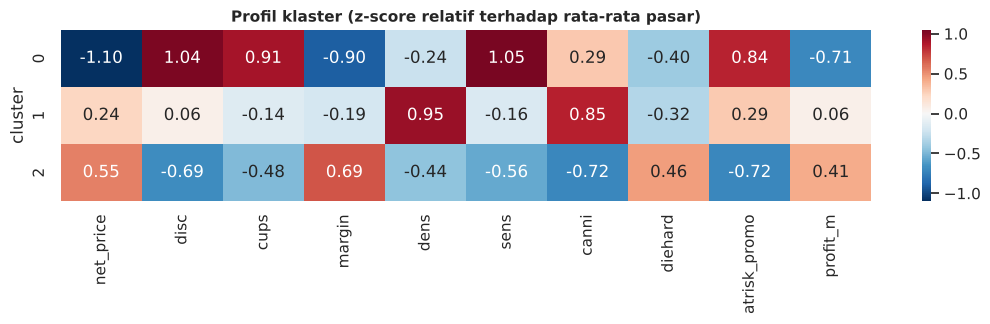

**Komposisi brand per klaster (% baris)**

brand,Fore Coffee,Kopi Janji Jiwa,Kopi Kenangan,Point Coffee,Tomoro Coffee
cluster,,,,,
0,5.70,0.70,13.00,0.20,80.40
1,28.30,10.70,34.30,11.40,15.40
2,20.70,16.30,31.30,22.40,9.30


**Komposisi fmt per klaster (% baris)**

fmt,Cloud Kitchen / Delivery Only,Drive-Thru Highway,Mall Kiosk,Office Tower Lobby,Standalone Shophouse / Ruko
cluster,,,,,
0,8.20,5.30,30.80,19.50,36.30
1,5.80,3.30,35.70,25.00,30.20
2,17.30,9.10,20.90,16.30,36.40


**Komposisi seg per klaster (% baris)**

seg,College Students & Gen Z,Delivery Couriers / Ojol,Office Corporate Workers,Residential Families,Transit Commuters
cluster,,,,,
0,38.20,9.80,31.00,14.20,6.80
1,28.80,7.00,40.10,16.60,7.40
2,29.20,12.10,36.30,14.80,7.60


**Komposisi order per klaster (% baris)**

order,Dine-In POS Cashier,Mobile App Pickup,Online Ojol Delivery
cluster,,,
0,20.70,45.30,34.00
1,21.80,45.80,32.40
2,21.20,45.30,33.50


In [32]:
# Pilihan k: silhouette tertinggi di antara k=3..6 (k=2 hanya pemisahan kasar; k>6 sulit ditindaklanjuti)
K_BEST = int(ev.loc[3:6, 'silhouette'].idxmax()); print('k terpilih =', K_BEST)
km = KMeans(K_BEST, n_init=30, random_state=SEED).fit(Xs); d['cluster'] = km.labels_

# Validasi: stabilitas (ARI antar seed & bootstrap), pembanding hierarkis (Ward)
aris = [adjusted_rand_score(km.labels_, KMeans(K_BEST, n_init=10, random_state=s).fit(Xs).labels_) for s in range(1, 6)]
boot = []
for s in range(5):
    ix = np.random.default_rng(s).choice(len(d), len(d)//2, replace=False); kb = KMeans(K_BEST, n_init=10, random_state=s).fit(Xs[ix]); boot.append(adjusted_rand_score(km.labels_, kb.predict(Xs)))
hc = AgglomerativeClustering(K_BEST, linkage='ward').fit(Xs[sub_ix]); ari_hc = adjusted_rand_score(km.labels_[sub_ix], hc.labels_)
sil = silhouette_score(Xs[sub_ix], km.labels_[sub_ix])
print(f'Silhouette = {sil:.3f} | ARI antar-seed = {np.mean(aris):.3f} | ARI split-half (prediksi) = {np.mean(boot):.3f} | ARI vs Ward (4.000 sampel) = {ari_hc:.3f}')
alt = {k: adjusted_rand_score(km.labels_, KMeans(k, n_init=10, random_state=SEED).fit(Xs).labels_) for k in [max(3, K_BEST-1), K_BEST+1]}; print('ARI vs k alternatif:', {k: round(v, 3) for k, v in alt.items()})

cp = d.groupby('cluster').agg(n=('cups','size'), share=('cups', lambda s: len(s)/len(d)*100), cups=('cups','mean'), net_price=('net_price','mean'), disc=('disc','mean'), margin=('margin','mean'), rev_m=('rev_m','mean'), profit_m=('profit_m','mean'),
        dens=('dens','mean'), sens=('sens','mean'), canni=('canni','mean'), diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), atrisk_promo=('loyalty', lambda s: s.isin(LOY[2:]).mean()*100), rating=('rating','mean')).round(2)
display(cp)
basef = d[['net_price','disc','cups','margin','dens','sens','canni']].assign(diehard=(d.loyalty==LOY[0])*100, atrisk_promo=d.loyalty.isin(LOY[2:])*100, profit_m=d.profit_m)
zc = (cp[basef.columns] - basef.mean()) / basef.std()
fig, ax = plt.subplots(figsize=(11, 3.4)); sns.heatmap(zc, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax); ax.set_title('Profil klaster (z-score relatif terhadap rata-rata pasar)'); plt.tight_layout(); plt.show()
for col in ['brand','fmt','seg','order']: md_(f'**Komposisi {col} per klaster (% baris)**'); display((pd.crosstab(d.cluster, d[col], normalize='index')*100).round(1))

,outlet_share,rev_share,profit_share,cups,net_price,disc,margin,profit_m,dens,sens,diehard,rating
archetype,,,,,,,,,,,,
Healthy Loyal Core,44.20,45.25,51.46,470.84,"17,891.90",17.52,34.04,2.76,3.89,4.57,29.36,4.53
Contested Dense-Market Core,27.84,29.83,28.46,545.57,"16,362.68",26.43,28.27,2.43,7.76,5.24,2.57,4.45
Discount-Driven Volume Chasers,27.96,24.93,20.08,772.44,"9,680.45",37.88,23.57,1.70,4.46,7.28,0.00,4.56


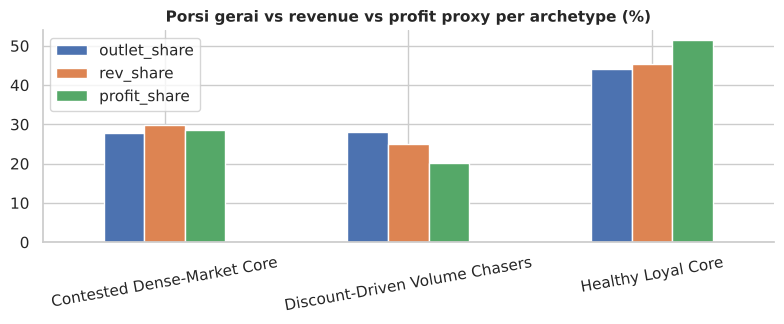

In [33]:
# Penamaan klaster SETELAH memeriksa profil: dasar = karakteristik terukur (diskon tertinggi; kepadatan tertinggi; sisanya)
assert K_BEST == 3, 'Aturan penamaan ditulis untuk k=3; sesuaikan bila k berubah'
c_disc = cp.disc.idxmax(); c_dens = cp.dens.drop(c_disc).idxmax(); c_core = [c for c in cp.index if c not in (c_disc, c_dens)][0]
NAMES = {c_disc: 'Discount-Driven Volume Chasers', c_dens: 'Contested Dense-Market Core', c_core: 'Healthy Loyal Core'}
d['archetype'] = d.cluster.map(NAMES)
ar = d.groupby('archetype').agg(outlet_share=('cups', lambda s: len(s)/len(d)*100), rev_share=('rev', lambda s: s.sum()/d.rev.sum()*100), profit_share=('profit', lambda s: s.sum()/d.profit.sum()*100), cups=('cups','mean'), net_price=('net_price','mean'),
        disc=('disc','mean'), margin=('margin','mean'), profit_m=('profit_m','mean'), dens=('dens','mean'), sens=('sens','mean'), diehard=('loyalty', lambda s: (s==LOY[0]).mean()*100), rating=('rating','mean')).round(2)
display(ar.sort_values('profit_m', ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.4)); ar[['outlet_share','rev_share','profit_share']].plot(kind='bar', ax=ax); ax.set_title('Porsi gerai vs revenue vs profit proxy per archetype (%)'); ax.tick_params(axis='x', rotation=10); ax.set_xlabel(''); plt.tight_layout(); plt.show()

**Interpretasi archetype.**
- **Discount-Driven Volume Chasers:** diskon tertinggi, harga bersih terendah, volume terbesar, margin terendah, hampir tanpa pelanggan Die-Hard, didominasi Tomoro. Banyak revenue, profit proxy per gerai terendah.
- **Contested Dense-Market Core:** kepadatan kompetitor ~2x klaster lain, indeks kanibalisasi tertinggi, diskon dan margin menengah, banyak Mall Kiosk / Office Lobby. Margin tertekan oleh format dan diskon, **bukan** oleh kepadatan itu sendiri (lihat 13.3b).
- **Healthy Loyal Core:** diskon rendah, harga bersih tinggi, margin tertinggi, porsi Die-Hard terbesar, banyak Cloud Kitchen / Drive-Thru / Ruko. Profit proxy per gerai tertinggi dengan volume sedang.

**Kehati-hatian:** struktur klaster **lemah** (silhouette ~0.23) dan sensitif terhadap algoritma/jumlah klaster (ARI vs Ward dan vs k=4 rendah). Klaster stabil terhadap *seed* dan *split-half*, tetapi sebaiknya dibaca sebagai **gradien ekonomi** (diskon-margin-loyalitas), bukan kelompok yang terpisah tegas.

In [34]:
ROB.append(('Segmentasi 3-klaster = kelompok yang terpisah tegas', 'Silhouette; ARI vs Ward; ARI vs k=4', f'sil={sil:.2f}; ARI Ward={ari_hc:.2f}; ARI k=4={alt[K_BEST+1]:.2f}', verdict(sil > 0.4 and ari_hc > 0.7, '')))
ROB.append(('Klaster stabil terhadap inisialisasi/sampel', 'ARI antar-seed & split-half', f'{np.mean(aris):.2f} / {np.mean(boot):.2f}', verdict(np.mean(aris) > 0.9 and np.mean(boot) > 0.9, '')))
ledger = pd.DataFrame(ROB, columns=['klaim','uji','hasil','verdict']); display(ledger)
print(ledger.verdict.value_counts().to_dict())

,klaim,uji,hasil,verdict
0,Peringkat merek stabil mean vs median,Spearman peringkat mean vs median (margin/rev/cups),"{'margin': np.float64(1.0), 'rev': np.float64(1.0), 'cups': np.float64(1.0)}",ROBUST
1,"Diskon naik -> margin turun, cups naik",Monotonisitas lintas 4 skema band,"rho_margin=[-1.0, -1.0, -1.0, -1.0], rho_cups=[1.0, 0.9, 1.0, 0.96]",ROBUST
2,Diskon naik -> revenue tidak naik monoton (puncak di diskon rendah-menengah),rho revenue vs band lintas skema,"[-0.9, -1.0, -0.94, -0.85]",ROBUST
3,Efek diskon thd margin tidak digerakkan outlier,"Trim dwell>60, rev P1/P99, disc>P99",koef -0.349 -> -0.349,ROBUST
4,Diskon-margin negatif di semua subgrup,Brand/format/order/kota (n>=100),rho maks = -0.60,ROBUST
5,Diskon menaikkan volume DI DALAM merek,Spearman diskon-cups per merek (maks),maks=0.05 (agregat=0.32; di dalam format/order +0.3 karena campuran merek),TIDAK TERDUKUNG
6,Diskon-revenue negatif di semua subgrup,Proporsi subgrup rho<0,100% (-0.61..-0.27),ROBUST
7,Peringkat atraktivitas kota bermakna,Eta-kuadrat kota pada profit proxy,0.33% (format 6.8%),RAPUH
8,Margin ditentukan terutama diskon+format+biji,R2 model ringkas vs penuh,0.9994 vs 0.9994,ROBUST
9,Koefisien diskon stabil lintas spesifikasi 2A/B/C,Rentang koefisien,"A=-0.349, B=-0.350, C=-0.349",ROBUST


{'ROBUST': 11, 'RAPUH': 2, 'TIDAK TERDUKUNG': 1}


# 15. Opportunity & Risk Prioritization
**Metodologi (transparan):** *Impact* = porsi **profit proxy** yang terpapar isu/tindakan (data); *Effort/Risk* = penilaian analis skala 1-5 (eksplisit sebagai judgement; >=3 dianggap tinggi). Ambang impact tinggi = **median** porsi profit seluruh inisiatif (bukan angka arbitrer).

Skenario cap diskon 30%: 4,512 gerai (34.7%) terdampak, 24.6% profit proxy berasal dari gerai ini.
(a) Revenue dijaga konstan: profit proxy +2.9% total pasar. (b) Titik impas: volume gerai terdampak boleh turun hingga ~21% sebelum profit proxy lebih rendah dari kondisi sekarang.
Skenario ini bersifat indikatif: memakai hubungan diskon-margin dari data; respons volume sebenarnya harus diuji dengan eksperimen.


,inisiatif,impact_pool_%,effort_risk,bukti,kuadran
1,Batasi diskon massal >30% -> promosi tertarget,24.55,2,"Gerai diskon >30%: 35% dari gerai, margin 23.9% vs 32.5%",PRIORITY OPPORTUNITY
2,Perbaiki model volume-trap Tomoro,24.51,4,Tomoro: profit/gerai Rp1.89 jt vs Kenangan Rp3.03 jt; Die-Hard 0.1%,PRIORITY RISK
3,Tinjau ekonomi Mall Kiosk,26.11,4,Mall: margin 25.4% (-9.9 pp vs Cloud Kitchen); 45% gerai Volume Trap,PRIORITY RISK
4,Lindungi Fore Coffee dari erosi harga,17.81,3,Fore: 64% switching price-driven; diskon 26.5% pada harga premium,MONITOR
5,Uji bauran biji (House/Robusta vs Arabica Specialty),45.82,3,"Margin +4.0 / +7.9 pp vs Arabica, tetapi rating Arabica 4.60 vs 4.43: risiko...",PRIORITY RISK
6,Skalakan Cloud Kitchen / Drive-Thru (margin tinggi),14.99,2,Margin 34.3% tetapi revenue/gerai rendah (Rp5.7 jt),EXPERIMENT
7,Program retensi pelanggan At-Risk (dense market),8.03,3,"At-Risk: 6.6% gerai, kepadatan 8.0, rating 4.00",MONITOR
8,Alokasi ekspansi berdasarkan peringkat kota,0.33,4,Kota hanya menjelaskan 0.33% variasi profit,MONITOR


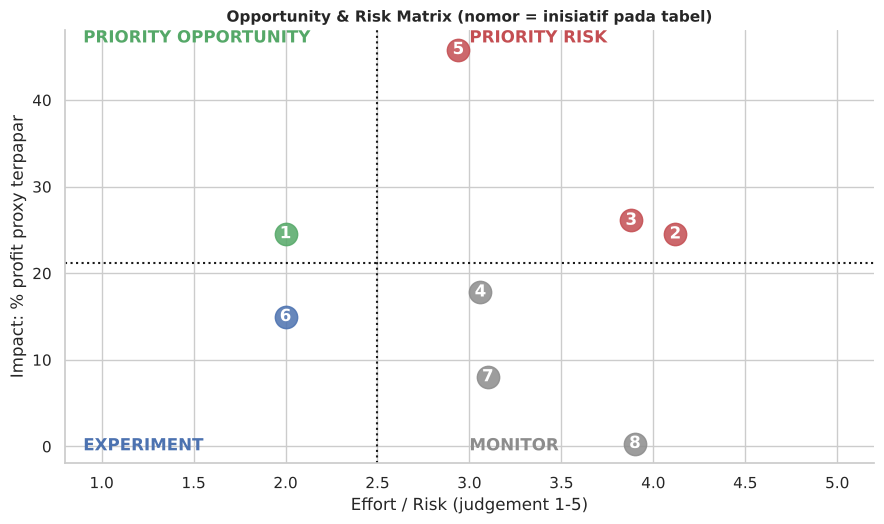

In [35]:
tot_profit = d.profit.sum(); pool = lambda m: d.loc[m, 'profit'].sum()/tot_profit*100
cap = 30; over = d[d.disc > cap]; dm = -mp.params['disc']
gain_cons = (over.rev * dm * (over.disc - cap)/100).sum(); gain_pct = gain_cons/tot_profit*100
pf = (1 - cap/100)/(1 - over.disc/100); v_star = over.profit.sum() / (over.rev*pf*(over.margin + dm*(over.disc-cap))/100).sum(); tol_vol = (1 - v_star)*100
print(f'Skenario cap diskon {cap}%: {len(over):,} gerai ({len(over)/len(d):.1%}) terdampak, {pool(d.disc>cap):.1f}% profit proxy berasal dari gerai ini.')
print(f'(a) Revenue dijaga konstan: profit proxy +{gain_pct:.1f}% total pasar. (b) Titik impas: volume gerai terdampak boleh turun hingga ~{tol_vol:.0f}% sebelum profit proxy lebih rendah dari kondisi sekarang.')
print('Skenario ini bersifat indikatif: memakai hubungan diskon-margin dari data; respons volume sebenarnya harus diuji dengan eksperimen.')

items = pd.DataFrame([
 ('Batasi diskon massal >30% -> promosi tertarget', pool(d.disc > 30), 2, f'Gerai diskon >30%: {len(over)/len(d):.0%} dari gerai, margin {over.margin.mean():.1f}% vs {d[d.disc<=30].margin.mean():.1f}%'),
 ('Perbaiki model volume-trap Tomoro', pool(d.brand=='Tomoro Coffee'), 4, f'Tomoro: profit/gerai Rp{bt.loc["Tomoro Coffee","profit_m"]:.2f} jt vs Kenangan Rp{bt.loc["Kopi Kenangan","profit_m"]:.2f} jt; Die-Hard {bt.loc["Tomoro Coffee","diehard_pct"]:.1f}%'),
 ('Tinjau ekonomi Mall Kiosk', pool(d.fmt=='Mall Kiosk'), 4, f'Mall: margin {fa.loc["Mall Kiosk","margin"]:.1f}% ({mp.params["C(fmt)[T.Mall Kiosk]"]:+.1f} pp vs Cloud Kitchen); {pd.crosstab(d.fmt,d.quad,normalize="index").loc["Mall Kiosk","Volume Trap"]:.0%} gerai Volume Trap'),
 ('Lindungi Fore Coffee dari erosi harga', pool(d.brand=='Fore Coffee'), 3, f'Fore: {(d[d.brand=="Fore Coffee"].switch_type=="Price-driven").mean():.0%} switching price-driven; diskon {bt.loc["Fore Coffee","disc"]:.1f}% pada harga premium'),
 ('Uji bauran biji (House/Robusta vs Arabica Specialty)', pool(d.beans=='100% Arabica Specialty'), 3, f'Margin +{mp.params["C(beans)[T.House Blend 70-30]"]:.1f} / +{mp.params["C(beans)[T.Robusta Blend Commercial]"]:.1f} pp vs Arabica, tetapi rating Arabica {d[d.beans=="100% Arabica Specialty"].rating.mean():.2f} vs {d[d.beans!="100% Arabica Specialty"].rating.mean():.2f}: risiko persepsi kualitas'),
 ('Skalakan Cloud Kitchen / Drive-Thru (margin tinggi)', pool(d.fmt.isin(['Cloud Kitchen / Delivery Only','Drive-Thru Highway'])), 2, f'Margin {d[d.fmt.isin(["Cloud Kitchen / Delivery Only","Drive-Thru Highway"])].margin.mean():.1f}% tetapi revenue/gerai rendah (Rp{d[d.fmt.isin(["Cloud Kitchen / Delivery Only","Drive-Thru Highway"])].rev_m.mean():.1f} jt)'),
 ('Program retensi pelanggan At-Risk (dense market)', pool(d.loyalty==LOY[3]), 3, f'At-Risk: {(d.loyalty==LOY[3]).mean():.1%} gerai, kepadatan {d[d.loyalty==LOY[3]].dens.mean():.1f}, rating {d[d.loyalty==LOY[3]].rating.mean():.2f}'),
 ('Alokasi ekspansi berdasarkan peringkat kota', eta.loc['city','profit_proxy']*100, 4, f'Kota hanya menjelaskan {eta.loc["city","profit_proxy"]*100:.2f}% variasi profit'),
], columns=['inisiatif','impact_pool_%','effort_risk','bukti'])
thr = items['impact_pool_%'].median()
items['kuadran'] = np.select([(items['impact_pool_%']>=thr)&(items.effort_risk<3), (items['impact_pool_%']>=thr)&(items.effort_risk>=3), (items['impact_pool_%']<thr)&(items.effort_risk<3)], ['PRIORITY OPPORTUNITY','PRIORITY RISK','EXPERIMENT'], 'MONITOR')
items.index = range(1, len(items)+1); display(items.round(2))

fig, ax = plt.subplots(figsize=(9, 5.4)); col = {'PRIORITY OPPORTUNITY':'#55A868','PRIORITY RISK':'#C44E52','EXPERIMENT':'#4C72B0','MONITOR':'#8C8C8C'}
jit = np.array([0, .12, -.12, .06, -.06, 0, .1, -.1])
for i, r in items.iterrows(): ax.scatter(r.effort_risk + jit[i-1], r['impact_pool_%'], s=260, color=col[r.kuadran], alpha=.85); ax.text(r.effort_risk + jit[i-1], r['impact_pool_%'], str(i), ha='center', va='center', color='white', fontweight='bold')
ax.axvline(2.5, c='k', ls=':'); ax.axhline(thr, c='k', ls=':'); ax.set_xlim(.8, 5.2); ax.set_xlabel('Effort / Risk (judgement 1-5)'); ax.set_ylabel('Impact: % profit proxy terpapar')
ax.set_title('Opportunity & Risk Matrix (nomor = inisiatif pada tabel)'); yl = ax.get_ylim()
ax.text(.9, yl[1]*.97, 'PRIORITY OPPORTUNITY', color=col['PRIORITY OPPORTUNITY'], fontweight='bold'); ax.text(3.0, yl[1]*.97, 'PRIORITY RISK', color=col['PRIORITY RISK'], fontweight='bold')
ax.text(.9, yl[0]+(yl[1]-yl[0])*.03, 'EXPERIMENT', color=col['EXPERIMENT'], fontweight='bold'); ax.text(3.0, yl[0]+(yl[1]-yl[0])*.03, 'MONITOR', color=col['MONITOR'], fontweight='bold')
plt.tight_layout(); plt.show()

# 16. Strategic Recommendations
Format setiap rekomendasi: **Finding -> Evidence -> Business Implication -> Recommended Action -> Expected Benefit -> Risk / Caveat.** Urutan = prioritas. Seluruh angka di bawah dihitung langsung dari data (bukan diketik manual).

In [36]:
b0, b4 = bd.loc['0-10'], bd.loc['40+']
tom, kk, fo = bt.loc['Tomoro Coffee'], bt.loc['Kopi Kenangan'], bt.loc['Fore Coffee']
vt = qa.loc['Volume Trap']; stq = qa.loc['Star']
hq, lq = rq.loc['High-quality'], rq.loc['Low-quality']
dh, pc = ls.loc[LOY[0]], ls.loc[LOY[2]]
ar_ = d[d.loyalty==LOY[3]]
sw_share = d.switch_type.value_counts(normalize=True)*100
cups_ctrl = 100*(np.exp(ols_c.params['disc'])-1)
cv_loy, cv_brand, cv_seg = [cramers(d[c], d.switch)[0] for c in ['loyalty','brand','seg']]
R = []
R.append(('1. Ganti diskon massal dengan promosi tertarget (PRIORITAS 1)',
 'Diskon yang dalam membeli volume pada level agregat, tetapi menghancurkan unit economics tanpa tambahan volume yang nyata di dalam merek.',
 f'Gerai diskon >40% vs <=10%: cups {b4["d_cups_%"]:+.0f}%, revenue {b4["d_rev_%"]:+.0f}%, margin {b4["d_margin_pp"]:+.0f} pp, profit proxy {b4["d_profit_%"]:+.0f}%. Di dalam merek: +1 pp diskon ~ {cups_ctrl:+.2f}% cups (kontrol merek/kota/format) tetapi {mp.params["disc"]:+.2f} pp margin (CI95 {mp.conf_int().loc["disc"][0]:+.2f}..{mp.conf_int().loc["disc"][1]:+.2f}). Profit proxy tertinggi pada diskon {best} pp; revenue puncak pada band 10-20%.',
 'Diskon massal membeli revenue/volume semu. Kenaikan cups pada level agregat berasal dari komposisi merek murah-diskon-tinggi, bukan dari respons volume terhadap diskon.',
 f'Tetapkan plafon diskon umum (indikatif 20-30%), alihkan anggaran ke promo tertarget (pelanggan Promo-Chaser, jam sepi, produk tertentu). Jalankan uji A/B per merek/kota sebelum rollout.',
 f'Skenario cap {cap}% (revenue konstan): profit proxy ~+{gain_pct:.1f}% pasar; titik impas volume ~-{tol_vol:.0f}% pada gerai terdampak.',
 'Asosiasi, bukan kausal; respons volume yang hampir nol mungkin cerminan struktur data sintetis. Wajib divalidasi eksperimen terkontrol.'))
R.append(('2. Perbaiki model volume-trap Tomoro (PRIORITAS 2)',
 'Tomoro volume tertinggi tetapi profit per gerai terendah; basis pelanggannya hampir sepenuhnya pemburu promo.',
 f'Cups {tom.cups:.0f} (tertinggi), net price Rp{tom.net_price:,.0f}, diskon {tom.disc:.1f}%, margin {tom.margin:.1f}%, profit/gerai Rp{tom.profit_m:.2f} jt vs Kopi Kenangan Rp{kk.profit_m:.2f} jt; Die-Hard {tom.diehard_pct:.1f}%, promo/at-risk {tom.atrisk_promo_pct:.0f}%. Pemicu switching utama Tomoro: antrean/pickup ({(d[d.brand=="Tomoro Coffee"].switch=="Long-Queue-Pickup-Delay").mean():.0%}), bukan harga.',
 'Pertumbuhan dibeli dengan subsidi harga tanpa loyalitas; rentan bila subsidi dikurangi atau kompetitor meniru.',
 'Turunkan diskon bertahap di wilayah uji (mis. -5 pp per siklus) sambil memperbaiki kecepatan pickup/antrean dan membangun program loyalitas non-diskon.',
 f'Setiap -10 pp diskon ~ +{10*dm:.1f} pp margin (asosiasi). Menutup separuh selisih diskon ke level Kopi Kenangan menambah margin ~{dm*(tom.disc-kk.disc)/2:.1f} pp.',
 'Risiko kehilangan volume pada basis sensitif harga; ukur elastisitas per wilayah sebelum eskalasi.'))
R.append(('3. Arahkan ekspansi menurut format, tinjau Mall Kiosk (PRIORITAS 3)',
 'Format, bukan kota, adalah pembeda ekonomi terbesar; Mall Kiosk memiliki penalti margin struktural.',
 f'Margin: Cloud {fa.loc["Cloud Kitchen / Delivery Only","margin"]:.1f}%, Drive-Thru {fa.loc["Drive-Thru Highway","margin"]:.1f}%, Ruko {fa.loc["Standalone Shophouse / Ruko","margin"]:.1f}%, Office {fa.loc["Office Tower Lobby","margin"]:.1f}%, Mall {fa.loc["Mall Kiosk","margin"]:.1f}%. Setelah kontrol diskon & merek, Mall {fa.loc["Mall Kiosk","margin_resid_after_disc_brand"]:+.1f} pp. Profit proxy/gerai tertinggi: Office Tower Rp{fa.loc["Office Tower Lobby","profit_m"]:.2f} jt; risk-adjusted terbaik: Ruko ({fa.loc["Standalone Shophouse / Ruko","risk_adj_profit"]:.2f}). Volume Trap: {pd.crosstab(d.fmt,d.quad,normalize="index").loc["Mall Kiosk","Volume Trap"]:.0%} Mall, {pd.crosstab(d.fmt,d.quad,normalize="index").loc["Office Tower Lobby","Volume Trap"]:.0%} Office.',
 'Revenue tinggi di Mall/Office tidak otomatis profit tinggi; Cloud Kitchen margin tinggi tetapi skala kecil. Perbedaan risk-adjusted antar format relatif sempit.',
 'Prioritaskan Ruko dan Office Lobby (dengan disiplin diskon), uji Cloud Kitchen/Drive-Thru sebagai pelengkap margin, dan renegosiasi/rasionalisasi biaya Mall Kiosk.',
 f'Mall sebagai format terlemah: menutup separuh penalti struktural (~{-fa.loc["Mall Kiosk","margin_resid_after_disc_brand"]/2:.1f} pp) bernilai besar karena Mall = {pool(d.fmt=="Mall Kiosk"):.0f}% profit proxy.',
 'Margin adalah estimasi; biaya sewa/capex tidak ada dalam data. Verifikasi dengan P&L gerai.'))
R.append(('4. Koreksi posisi Fore Coffee: biaya bauran biji, bukan diskon',
 'Fore adalah merek premium dengan 100% Arabica Specialty; margin rendahnya terutama berasal dari bauran biji, dan pelanggannya paling rentan terhadap pesaing lebih murah.',
 f'Fore: net price Rp{fo.net_price:,.0f}, diskon {fo.disc:.1f}%, margin {fo.margin:.1f}%. Atribusi selisih margin vs pasar: diskon {att.loc["Fore Coffee","efek_diskon_pp"]:+.1f} pp, format {att.loc["Fore Coffee","efek_format_pp"]:+.1f} pp, biji {att.loc["Fore Coffee","efek_biji_pp"]:+.1f} pp. {(d[d.brand=="Fore Coffee"].switch=="Cheaper-Competitor-Opening").mean():.0%} switching dipicu pesaing lebih murah; Volume Trap {pd.crosstab(d.brand,d.quad,normalize="index").loc["Fore Coffee","Volume Trap"]:.0%} gerai; rating Fore {fo.rating:.2f} (tertinggi).',
 'Menurunkan diskon saja hanya memberi dampak kecil bagi Fore; biaya biji premium adalah pengungkitnya, sementara premium kualitas (rating) adalah aset merek.',
 'Pertahankan Arabica sebagai pembeda, tetapi uji penyesuaian harga/produk premium untuk menutup biaya biji, dan pantau gerai pesaing murah di sekitar Fore. Uji bauran biji hanya pada produk non-signature.',
 f'Diskon ke rata-rata pasar hanya ~+{dm*(fo.disc-d.disc.mean()):.1f} pp margin; sebagian besar peluang ada pada harga/bauran produk.',
 'Biaya biji tidak ada di data (efek biji diturunkan dari margin estimasi); risiko menggerus persepsi kualitas bila bauran diubah.'))
R.append(('5. Bangun loyalitas lewat pengalaman, bukan voucher',
 'Tier loyalitas adalah pembeda nilai pelanggan terkuat dan pemicu switching bergantung pada pengalaman/harga, bukan hanya promosi.',
 f'Die-Hard: diskon {dh.disc:.1f}%, margin {dh.margin:.1f}%, profit Rp{dh.profit_m:.2f} jt; Promo-Chaser: diskon {pc.disc:.1f}%, margin {pc.margin:.1f}%, profit Rp{pc.profit_m:.2f} jt. Pemicu switching: experience {sw_share["Experience-driven"]:.1f}%, price {sw_share["Price-driven"]:.1f}%, availability {sw_share["Availability/Convenience-driven"]:.1f}%, promotion {sw_share["Promotion-driven"]:.1f}%. Cramer V switching vs loyalitas = {cv_loy:.2f}, vs merek = {cv_brand:.2f}, vs segmen = {cv_seg:.2f}. At-Risk: kepadatan {ar_.dens.mean():.1f} (pasar {d.dens.mean():.1f}), rating {ar_.rating.mean():.2f} (pasar {d.rating.mean():.2f}).',
 'Pelanggan paling bernilai adalah yang tidak perlu diskon besar. Segmen demografis nyaris identik secara ekonomi, jadi segmentasi perilaku (loyalitas) lebih berguna daripada segmen.',
 'Prioritaskan konsistensi rasa, kecepatan layanan, dan kenyamanan (tempat duduk/WiFi) di gerai padat; ukur loyalitas sebagai KPI; komunikasikan perubahan voucher dengan jelas (switching karena voucher habis hanya muncul pada gerai diskon rendah).',
 'Mengurangi ketergantungan pada pemburu promo dan meningkatkan porsi pelanggan margin tinggi.',
 'Hubungan loyalitas-diskon-margin bersifat asosiatif dan terikat definisi tier; uji intervensi retensi dengan kelompok kontrol.'))
R.append(('6. Gunakan screening gerai (format + diskon), bukan peringkat kota, untuk ekspansi',
 'Antar-kota hampir identik; yang membedakan adalah kepadatan kompetitor dan format.',
 f'Kota menjelaskan {eta.loc["city","profit_proxy"]*100:.2f}% variasi profit vs format {eta.loc["fmt","profit_proxy"]*100:.1f}% dan merek {eta.loc["brand","profit_proxy"]*100:.1f}%. Setelah kontrol, +1 kompetitor ~ {100*(np.exp(smf.ols("np.log(rev) ~ dens + C(brand) + C(city) + C(fmt) + C(order)", d).fit().params["dens"])-1):+.1f}% revenue dan efek margin ~0; indeks kanibalisasi naik {mc.params["dens"]:.2f} per kompetitor (dihasilkan mekanis oleh formula).',
 'Kepadatan kompetitor berasosiasi dengan demand yang sedikit lebih kuat, bukan penalti margin; skor kanibalisasi tinggi di Jakarta/Surabaya adalah fungsi kepadatan.',
 'Nilai calon gerai pada level format, kepadatan, dan disiplin diskon; kumpulkan data penjualan nyata (transfer sales antar-gerai) untuk mengukur kanibalisasi sebenarnya.',
 'Menghindari alokasi modal berdasarkan perbedaan kota yang tidak material.',
 'Kota dengan n<100 (Malang, Makassar, Palembang, Batam) tidak dapat dinilai; tidak ada dimensi waktu.'))
for t, f, e, imp, act, ben, cav in R:
    md_(f"### {t}\n- **Finding:** {f}\n- **Evidence:** {e}\n- **Business implication:** {imp}\n- **Recommended action:** {act}\n- **Expected benefit:** {ben}\n- **Risk / caveat:** {cav}")

### 1. Ganti diskon massal dengan promosi tertarget (PRIORITAS 1)
- **Finding:** Diskon yang dalam membeli volume pada level agregat, tetapi menghancurkan unit economics tanpa tambahan volume yang nyata di dalam merek.
- **Evidence:** Gerai diskon >40% vs <=10%: cups +58%, revenue -33%, margin -18 pp, profit proxy -64%. Di dalam merek: +1 pp diskon ~ +0.03% cups (kontrol merek/kota/format) tetapi -0.35 pp margin (CI95 -0.35..-0.35). Profit proxy tertinggi pada diskon 5-10 pp; revenue puncak pada band 10-20%.
- **Business implication:** Diskon massal membeli revenue/volume semu. Kenaikan cups pada level agregat berasal dari komposisi merek murah-diskon-tinggi, bukan dari respons volume terhadap diskon.
- **Recommended action:** Tetapkan plafon diskon umum (indikatif 20-30%), alihkan anggaran ke promo tertarget (pelanggan Promo-Chaser, jam sepi, produk tertentu). Jalankan uji A/B per merek/kota sebelum rollout.
- **Expected benefit:** Skenario cap 30% (revenue konstan): profit proxy ~+2.9% pasar; titik impas volume ~-21% pada gerai terdampak.
- **Risk / caveat:** Asosiasi, bukan kausal; respons volume yang hampir nol mungkin cerminan struktur data sintetis. Wajib divalidasi eksperimen terkontrol.

### 2. Perbaiki model volume-trap Tomoro (PRIORITAS 2)
- **Finding:** Tomoro volume tertinggi tetapi profit per gerai terendah; basis pelanggannya hampir sepenuhnya pemburu promo.
- **Evidence:** Cups 798 (tertinggi), net price Rp9,457, diskon 33.9%, margin 25.1%, profit/gerai Rp1.89 jt vs Kopi Kenangan Rp3.03 jt; Die-Hard 0.1%, promo/at-risk 63%. Pemicu switching utama Tomoro: antrean/pickup (54%), bukan harga.
- **Business implication:** Pertumbuhan dibeli dengan subsidi harga tanpa loyalitas; rentan bila subsidi dikurangi atau kompetitor meniru.
- **Recommended action:** Turunkan diskon bertahap di wilayah uji (mis. -5 pp per siklus) sambil memperbaiki kecepatan pickup/antrean dan membangun program loyalitas non-diskon.
- **Expected benefit:** Setiap -10 pp diskon ~ +3.5 pp margin (asosiasi). Menutup separuh selisih diskon ke level Kopi Kenangan menambah margin ~1.9 pp.
- **Risk / caveat:** Risiko kehilangan volume pada basis sensitif harga; ukur elastisitas per wilayah sebelum eskalasi.

### 3. Arahkan ekspansi menurut format, tinjau Mall Kiosk (PRIORITAS 3)
- **Finding:** Format, bukan kota, adalah pembeda ekonomi terbesar; Mall Kiosk memiliki penalti margin struktural.
- **Evidence:** Margin: Cloud 35.3%, Drive-Thru 32.5%, Ruko 31.5%, Office 27.5%, Mall 25.4%. Setelah kontrol diskon & merek, Mall -4.1 pp. Profit proxy/gerai tertinggi: Office Tower Rp2.69 jt; risk-adjusted terbaik: Ruko (2.67). Volume Trap: 45% Mall, 48% Office.
- **Business implication:** Revenue tinggi di Mall/Office tidak otomatis profit tinggi; Cloud Kitchen margin tinggi tetapi skala kecil. Perbedaan risk-adjusted antar format relatif sempit.
- **Recommended action:** Prioritaskan Ruko dan Office Lobby (dengan disiplin diskon), uji Cloud Kitchen/Drive-Thru sebagai pelengkap margin, dan renegosiasi/rasionalisasi biaya Mall Kiosk.
- **Expected benefit:** Mall sebagai format terlemah: menutup separuh penalti struktural (~2.0 pp) bernilai besar karena Mall = 26% profit proxy.
- **Risk / caveat:** Margin adalah estimasi; biaya sewa/capex tidak ada dalam data. Verifikasi dengan P&L gerai.

### 4. Koreksi posisi Fore Coffee: biaya bauran biji, bukan diskon
- **Finding:** Fore adalah merek premium dengan 100% Arabica Specialty; margin rendahnya terutama berasal dari bauran biji, dan pelanggannya paling rentan terhadap pesaing lebih murah.
- **Evidence:** Fore: net price Rp20,841, diskon 26.5%, margin 26.8%. Atribusi selisih margin vs pasar: diskon -0.3 pp, format +0.0 pp, biji -2.4 pp. 64% switching dipicu pesaing lebih murah; Volume Trap 41% gerai; rating Fore 4.62 (tertinggi).
- **Business implication:** Menurunkan diskon saja hanya memberi dampak kecil bagi Fore; biaya biji premium adalah pengungkitnya, sementara premium kualitas (rating) adalah aset merek.
- **Recommended action:** Pertahankan Arabica sebagai pembeda, tetapi uji penyesuaian harga/produk premium untuk menutup biaya biji, dan pantau gerai pesaing murah di sekitar Fore. Uji bauran biji hanya pada produk non-signature.
- **Expected benefit:** Diskon ke rata-rata pasar hanya ~+0.3 pp margin; sebagian besar peluang ada pada harga/bauran produk.
- **Risk / caveat:** Biaya biji tidak ada di data (efek biji diturunkan dari margin estimasi); risiko menggerus persepsi kualitas bila bauran diubah.

### 5. Bangun loyalitas lewat pengalaman, bukan voucher
- **Finding:** Tier loyalitas adalah pembeda nilai pelanggan terkuat dan pemicu switching bergantung pada pengalaman/harga, bukan hanya promosi.
- **Evidence:** Die-Hard: diskon 9.8%, margin 36.5%, profit Rp3.23 jt; Promo-Chaser: diskon 38.6%, margin 24.0%, profit Rp1.68 jt. Pemicu switching: experience 40.6%, price 30.5%, availability 21.2%, promotion 7.7%. Cramer V switching vs loyalitas = 0.49, vs merek = 0.35, vs segmen = 0.17. At-Risk: kepadatan 8.0 (pasar 5.1), rating 4.00 (pasar 4.52).
- **Business implication:** Pelanggan paling bernilai adalah yang tidak perlu diskon besar. Segmen demografis nyaris identik secara ekonomi, jadi segmentasi perilaku (loyalitas) lebih berguna daripada segmen.
- **Recommended action:** Prioritaskan konsistensi rasa, kecepatan layanan, dan kenyamanan (tempat duduk/WiFi) di gerai padat; ukur loyalitas sebagai KPI; komunikasikan perubahan voucher dengan jelas (switching karena voucher habis hanya muncul pada gerai diskon rendah).
- **Expected benefit:** Mengurangi ketergantungan pada pemburu promo dan meningkatkan porsi pelanggan margin tinggi.
- **Risk / caveat:** Hubungan loyalitas-diskon-margin bersifat asosiatif dan terikat definisi tier; uji intervensi retensi dengan kelompok kontrol.

### 6. Gunakan screening gerai (format + diskon), bukan peringkat kota, untuk ekspansi
- **Finding:** Antar-kota hampir identik; yang membedakan adalah kepadatan kompetitor dan format.
- **Evidence:** Kota menjelaskan 0.33% variasi profit vs format 6.8% dan merek 22.4%. Setelah kontrol, +1 kompetitor ~ +0.6% revenue dan efek margin ~0; indeks kanibalisasi naik 0.34 per kompetitor (dihasilkan mekanis oleh formula).
- **Business implication:** Kepadatan kompetitor berasosiasi dengan demand yang sedikit lebih kuat, bukan penalti margin; skor kanibalisasi tinggi di Jakarta/Surabaya adalah fungsi kepadatan.
- **Recommended action:** Nilai calon gerai pada level format, kepadatan, dan disiplin diskon; kumpulkan data penjualan nyata (transfer sales antar-gerai) untuk mengukur kanibalisasi sebenarnya.
- **Expected benefit:** Menghindari alokasi modal berdasarkan perbedaan kota yang tidak material.
- **Risk / caveat:** Kota dengan n<100 (Malang, Makassar, Palembang, Batam) tidak dapat dinilai; tidak ada dimensi waktu.

# 17. Limitations & Data Caveats
- **Kemungkinan data sintetis.** Margin (R² 0,999), cannibalization index (R² 1,000), dan sensitivitas harga (R² 0,997) dapat direkonstruksi dari kolom mentah; `confidence_score` tertumpuk pada 0,99; narasi adalah templat; kategori sangat bersih. Hubungan yang ditemukan bisa mencerminkan **formula pembangkit data**, bukan perilaku pasar sebenarnya.
- **Estimasi, bukan akuntansi.** Margin adalah estimasi; tidak ada data biaya (sewa, capex, COGS) sehingga *profit proxy* = revenue x margin hanya indikatif.
- **Korelasi bukan kausalitas.** Tidak ada eksperimen/instrumen; efek diskon, harga, dan kepadatan adalah asosiasi. Skenario (mis. plafon diskon) hanya what-if, bukan prediksi.
- **Tidak ada dimensi waktu.** Tidak dapat menilai tren, musiman, retensi sebenarnya, atau dampak jangka panjang diskon.
- **Unit analisis ambigu.** `store_transaction_id` menyerupai satu snapshot gerai/hari; tidak ada ID gerai berulang, sehingga tidak ada kontrol efek-tetap per gerai.
- **Variabel eksternal hilang:** demografi, biaya sewa, kapasitas gerai, kualitas lokasi, kampanye pemasaran, harga kompetitor aktual, dan data penjualan antar-gerai untuk kanibalisasi nyata.
- **Artefak dwell time.** Variasi dwell time hanya ada pada Dine-In; rasio dwell-to-spend turunan dan tidak digunakan untuk inferensi.
- **Referensi price_comp hampir konstan (~Rp20,2 rb).** Rasio ini praktis net price yang diskalakan, bukan ukuran daya saing yang berdiri sendiri.
- **Kota kecil** (n<100: Malang, Makassar, Palembang, Batam) tidak diberi peringkat; **segmentasi klaster berstruktur lemah** (silhouette ~0,23) dan sensitif terhadap algoritma.
- **Efek kolinearitas:** `sens`, `loyalty`, `disc` berkorelasi kuat; koefisien individual pada Model 2 dibaca bersama analisis blok dan model ringkas.

# 18. Final Executive Conclusion
## 18.1 Executive Dashboard

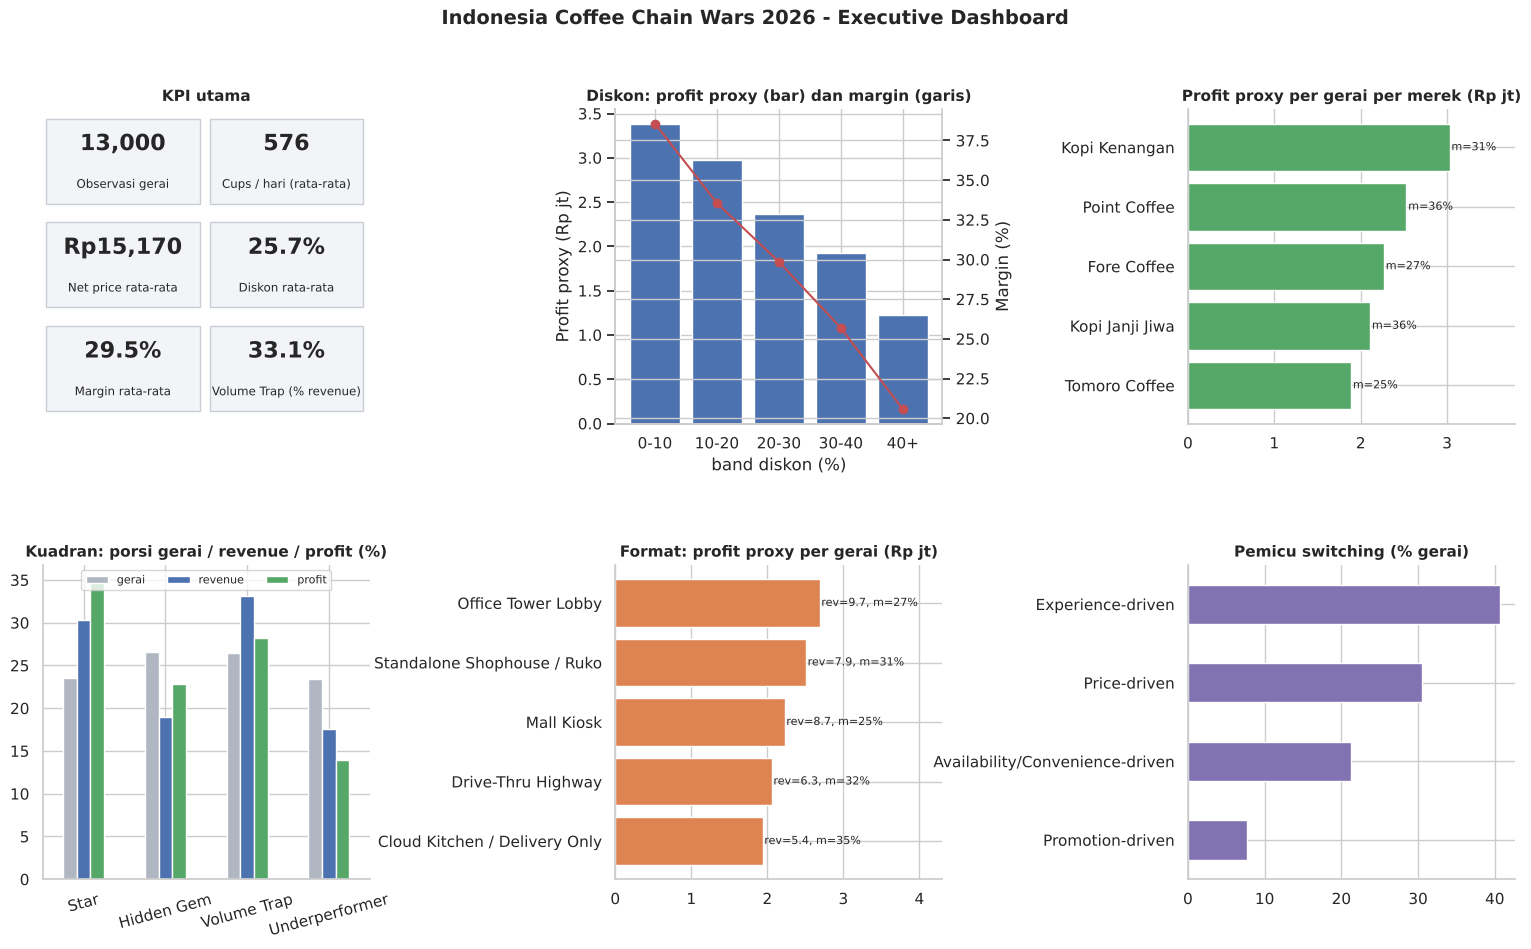

In [37]:
fig = plt.figure(figsize=(19, 10)); gs = fig.add_gridspec(2, 3, hspace=.45, wspace=.75)
ax = fig.add_subplot(gs[0, 0]); ax.axis('off')
cards = [('Observasi gerai', f'{len(d):,}'), ('Cups / hari (rata-rata)', f'{d.cups.mean():.0f}'), ('Net price rata-rata', f'Rp{d.net_price.mean():,.0f}'),
         ('Diskon rata-rata', f'{d.disc.mean():.1f}%'), ('Margin rata-rata', f'{d.margin.mean():.1f}%'), ('Volume Trap (% revenue)', f'{qa.loc["Volume Trap","rev_share"]:.1f}%')]
for i, (k, v) in enumerate(cards):
    x, y = (i % 2)*.5, .70 - (i//2)*.33
    ax.add_patch(plt.Rectangle((x+.01, y), .47, .27, fc='#F2F4F7', ec='#C9CED6', transform=ax.transAxes)); ax.text(x+.245, y+.17, v, ha='center', fontsize=16, fontweight='bold', transform=ax.transAxes); ax.text(x+.245, y+.05, k, ha='center', fontsize=8.5, transform=ax.transAxes)
ax.set_title('KPI utama')
ax = fig.add_subplot(gs[0, 1]); ax.bar(bd.index.astype(str), bd.profit_m, color='#4C72B0'); ax.set_ylabel('Profit proxy (Rp jt)'); a2 = ax.twinx(); a2.plot(bd.index.astype(str), bd.margin, 'o-', color='#C44E52'); a2.set_ylabel('Margin (%)'); a2.spines['right'].set_visible(True); ax.set_title('Diskon: profit proxy (bar) dan margin (garis)'); ax.set_xlabel('band diskon (%)')
ax = fig.add_subplot(gs[0, 2]); bs = bt.sort_values('profit_m'); ax.barh(bs.index, bs.profit_m, color='#55A868'); [ax.text(v+.02, i, f'm={m:.0f}%', va='center', fontsize=8) for i, (v, m) in enumerate(zip(bs.profit_m, bs.margin))]; ax.set_title('Profit proxy per gerai per merek (Rp jt)'); ax.set_xlim(0, bs.profit_m.max()*1.25)
ax = fig.add_subplot(gs[1, 0]); qq = qa.loc[['Star','Hidden Gem','Volume Trap','Underperformer'], ['n_share','rev_share','profit_share']]; qq.plot(kind='bar', ax=ax, color=['#B0B7C3','#4C72B0','#55A868']); ax.set_title('Kuadran: porsi gerai / revenue / profit (%)'); ax.tick_params(axis='x', rotation=15); ax.set_xlabel(''); ax.legend(['gerai','revenue','profit'], fontsize=8, loc='upper center', ncol=3)
ax = fig.add_subplot(gs[1, 1]); fs = fa.sort_values('profit_m'); ax.barh(fs.index, fs.profit_m, color='#DD8452'); [ax.text(v+.02, i, f'rev={r:.1f}, m={m:.0f}%', va='center', fontsize=8) for i, (v, r, m) in enumerate(zip(fs.profit_m, fs.rev_m, fs.margin))]; ax.set_xlim(0, fs.profit_m.max()*1.6); ax.set_title('Format: profit proxy per gerai (Rp jt)')
ax = fig.add_subplot(gs[1, 2]); sw_share.sort_values().plot(kind='barh', ax=ax, color='#8172B2'); ax.set_title('Pemicu switching (% gerai)'); ax.set_ylabel('')
plt.suptitle('Indonesia Coffee Chain Wars 2026 - Executive Dashboard', fontsize=14, fontweight='bold', y=.98); plt.show()

## 18.2 Jawaban akhir untuk manajemen

In [38]:
md_(f"""
### What happened?
Pasar kopi ini **membeli volume dengan diskon, dan harganya adalah profit.** Gerai berdiskon >40% mencatat cups {b4["d_cups_%"]:+.0f}% tetapi revenue {b4["d_rev_%"]:+.0f}% dan profit proxy {b4["d_profit_%"]:+.0f}% dibanding gerai berdiskon <=10%. Kenaikan volume pada level agregat adalah efek komposisi merek, bukan respons volume di dalam merek ({cups_ctrl:+.2f}% cups per +1 pp diskon setelah kontrol). Kopi Kenangan memimpin profit per gerai (Rp{kk.profit_m:.2f} jt), sementara Tomoro memimpin volume tetapi terendah profit (Rp{tom.profit_m:.2f} jt).

### Why did it happen?
Margin dalam data ini ditentukan hampir sepenuhnya oleh **tiga hal: diskon ({mp.params["disc"]:+.2f} pp per poin), format gerai (Mall {mp.params["C(fmt)[T.Mall Kiosk]"]:+.1f} pp, Office {mp.params["C(fmt)[T.Office Tower Lobby]"]:+.1f} pp vs Cloud Kitchen) dan jenis biji** (R² model ringkas = {mp_ols.rsquared:.3f}). Revenue ditentukan oleh format, merek, dan harga/diskon. Segmen pelanggan dan kota hampir tidak membedakan kinerja; yang membedakan adalah tier loyalitas.

### Where is the opportunity?
**Disiplin diskon.** {len(over)/len(d):.0%} gerai berdiskon >{cap}%. Membatasinya (skenario revenue konstan) berpotensi menambah ~{gain_pct:.1f}% profit proxy pasar; volume gerai terdampak dapat turun ~{tol_vol:.0f}% sebelum profit lebih buruk dari sekarang. Peluang kedua: ekspansi ke format Ruko/Office Lobby/Drive-Thru yang lebih sehat secara risk-adjusted.

### Where is the risk?
**Volume Trap:** {vt.n_share:.1f}% gerai, {vt.rev_share:.1f}% revenue, {vt.profit_share:.1f}% profit proxy (margin ~{vt.margin:.0f}%), terkonsentrasi di Mall/Office dan paling besar porsinya pada Fore Coffee. Revenue yang tampak besar menutupi ekonomi lemah. Risiko kedua: pelanggan pemburu promo ({(d.loyalty==LOY[2]).mean():.0%} gerai) yang tidak loyal dan mudah berpindah.

### What should management do?
1. **Ganti diskon massal dengan promosi tertarget** dan buktikan lewat eksperimen A/B per merek.
2. **Perbaiki model Tomoro**: turunkan diskon bertahap, atasi antrean/pickup, dan bangun loyalitas non-diskon.
3. **Arahkan ekspansi menurut format dan disiplin diskon** (Ruko, Office Lobby, Drive-Thru), serta tinjau ulang ekonomi Mall Kiosk; investasikan pada data biaya dan penjualan nyata.

### What should management avoid?
1. **Tindakan berisiko:** diskon massal untuk mengejar volume, dan alokasi modal berdasarkan peringkat kota (kota menjelaskan {eta.loc["city","profit_proxy"]*100:.2f}% variasi profit).
2. **KPI menyesatkan:** peringkat merek/gerai berdasarkan revenue atau cups saja; `revenue_per_competitor`, `price_competitiveness`, `confidence_score` sebagai bukti independen.
3. **Asumsi tak terdukung:** menafsirkan asosiasi sebagai kausalitas, menganggap kepadatan kompetitor otomatis buruk (efek margin ~0 setelah kontrol), dan menganggap data sintetis ini setara bukti pasar riil.

> **Apa yang boleh dipercaya manajemen dengan yakin:** diskon dalam menekan margin dan profit; format dan loyalitas membedakan ekonomi gerai. **Yang masih tidak pasti:** besaran respons volume terhadap diskon di dunia nyata, kanibalisasi sebenarnya, dan dampak jangka panjang. **Langkah berikutnya:** uji eksperimen diskon, kumpulkan data biaya dan penjualan nyata, ulangi analisis dengan data waktu.
""")


### What happened?
Pasar kopi ini **membeli volume dengan diskon, dan harganya adalah profit.** Gerai berdiskon >40% mencatat cups +58% tetapi revenue -33% dan profit proxy -64% dibanding gerai berdiskon <=10%. Kenaikan volume pada level agregat adalah efek komposisi merek, bukan respons volume di dalam merek (+0.03% cups per +1 pp diskon setelah kontrol). Kopi Kenangan memimpin profit per gerai (Rp3.03 jt), sementara Tomoro memimpin volume tetapi terendah profit (Rp1.89 jt).

### Why did it happen?
Margin dalam data ini ditentukan hampir sepenuhnya oleh **tiga hal: diskon (-0.35 pp per poin), format gerai (Mall -9.9 pp, Office -7.9 pp vs Cloud Kitchen) dan jenis biji** (R² model ringkas = 0.999). Revenue ditentukan oleh format, merek, dan harga/diskon. Segmen pelanggan dan kota hampir tidak membedakan kinerja; yang membedakan adalah tier loyalitas.

### Where is the opportunity?
**Disiplin diskon.** 35% gerai berdiskon >30%. Membatasinya (skenario revenue konstan) berpotensi menambah ~2.9% profit proxy pasar; volume gerai terdampak dapat turun ~21% sebelum profit lebih buruk dari sekarang. Peluang kedua: ekspansi ke format Ruko/Office Lobby/Drive-Thru yang lebih sehat secara risk-adjusted.

### Where is the risk?
**Volume Trap:** 26.5% gerai, 33.1% revenue, 28.2% profit proxy (margin ~25%), terkonsentrasi di Mall/Office dan paling besar porsinya pada Fore Coffee. Revenue yang tampak besar menutupi ekonomi lemah. Risiko kedua: pelanggan pemburu promo (35% gerai) yang tidak loyal dan mudah berpindah.

### What should management do?
1. **Ganti diskon massal dengan promosi tertarget** dan buktikan lewat eksperimen A/B per merek.
2. **Perbaiki model Tomoro**: turunkan diskon bertahap, atasi antrean/pickup, dan bangun loyalitas non-diskon.
3. **Arahkan ekspansi menurut format dan disiplin diskon** (Ruko, Office Lobby, Drive-Thru), serta tinjau ulang ekonomi Mall Kiosk; investasikan pada data biaya dan penjualan nyata.

### What should management avoid?
1. **Tindakan berisiko:** diskon massal untuk mengejar volume, dan alokasi modal berdasarkan peringkat kota (kota menjelaskan 0.33% variasi profit).
2. **KPI menyesatkan:** peringkat merek/gerai berdasarkan revenue atau cups saja; `revenue_per_competitor`, `price_competitiveness`, `confidence_score` sebagai bukti independen.
3. **Asumsi tak terdukung:** menafsirkan asosiasi sebagai kausalitas, menganggap kepadatan kompetitor otomatis buruk (efek margin ~0 setelah kontrol), dan menganggap data sintetis ini setara bukti pasar riil.

> **Apa yang boleh dipercaya manajemen dengan yakin:** diskon dalam menekan margin dan profit; format dan loyalitas membedakan ekonomi gerai. **Yang masih tidak pasti:** besaran respons volume terhadap diskon di dunia nyata, kanibalisasi sebenarnya, dan dampak jangka panjang. **Langkah berikutnya:** uji eksperimen diskon, kumpulkan data biaya dan penjualan nyata, ulangi analisis dengan data waktu.


## 18.3 Audit angka Executive Summary
Cell berikut memverifikasi bahwa angka yang diketik pada Bagian 00 sama dengan hasil perhitungan notebook (gagal = ada ketidaksesuaian).

In [39]:
chk = {
 'cups +58% (diskon>40 vs <=10)': abs(bd.loc['40+','d_cups_%'] - 58) < 1,
 'revenue -33%': abs(bd.loc['40+','d_rev_%'] + 33) < 1,
 'margin -18 pp': abs(bd.loc['40+','d_margin_pp'] + 18) < 0.6,
 'profit proxy -64%': abs(bd.loc['40+','d_profit_%'] + 64) < 1,
 'cups per pp diskon within-brand ~ +0.03%': abs(cups_ctrl - 0.03) < 0.02,
 'margin per pp diskon -0.35': abs(mp.params['disc'] + 0.35) < 0.01,
 'R2 model ringkas >= 0.99': mp_ols.rsquared > 0.99,
 'Volume Trap: gerai 26.5 / revenue 33.1 / profit 28.2 %': abs(qa.loc['Volume Trap','n_share']-26.5)<.2 and abs(qa.loc['Volume Trap','rev_share']-33.1)<.2 and abs(qa.loc['Volume Trap','profit_share']-28.2)<.2,
 'Die-Hard diskon 9.8 / margin 36.5': abs(ls.loc[LOY[0],'disc']-9.8)<.1 and abs(ls.loc[LOY[0],'margin']-36.5)<.1,
 'Promo-Chaser diskon 38.6 / margin 24.0': abs(ls.loc[LOY[2],'disc']-38.6)<.1 and abs(ls.loc[LOY[2],'margin']-24.0)<.1,
 'Switching experience 40.6 / price 30.5 / promo 7.7': abs(sw_share['Experience-driven']-40.6)<.1 and abs(sw_share['Price-driven']-30.5)<.1 and abs(sw_share['Promotion-driven']-7.7)<.1,
 'Kota < 1% variasi profit': eta.loc['city','profit_proxy'] < 0.01,
 'Silhouette ~0.23': abs(sil-0.23) < 0.02,
}
audit = pd.Series(chk, name='cocok'); display(audit.to_frame())
assert audit.all(), 'Ada angka Executive Summary yang tidak cocok dengan hasil perhitungan - perbarui Bagian 00'
print('Semua angka Executive Summary terverifikasi.')

,cocok
cups +58% (diskon>40 vs <=10),True
revenue -33%,True
margin -18 pp,True
profit proxy -64%,True
cups per pp diskon within-brand ~ +0.03%,True
margin per pp diskon -0.35,True
R2 model ringkas >= 0.99,True
Volume Trap: gerai 26.5 / revenue 33.1 / profit 28.2 %,True
Die-Hard diskon 9.8 / margin 36.5,True
Promo-Chaser diskon 38.6 / margin 24.0,True


Semua angka Executive Summary terverifikasi.
